# Industrial Analytics Project - Group 4

## 1. How to Run This Notebook

> **The dataset is not included in this repository.** The raw CSV is about 218 MB, which is more than GitHub's 100 MB file limit. Download it from the original source before you run the notebook.

**Step 1: Download the data**

1. Open the [MetroPT-3 dataset on the UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/791/metropt%203%20dataset) and click **Download**.
2. Unzip the archive. It contains `MetroPT3(AirCompressor).csv` (about 218 MB, 1,516,948 rows).

**Step 2: Put the file next to this notebook**

1. Rename the file to `MetroPT3_raw_data.csv`.
2. Place it in the same folder as this notebook. The notebook loads it in section 3.3 with `pd.read_csv("MetroPT3_raw_data.csv")`.

If you prefer to keep the original file name or another folder, change the path in that cell instead.

**Step 3: Install the packages**

```bash
pip install pandas numpy matplotlib seaborn plotly pyarrow notebook
```

In VS Code, install the *Python* and *Jupyter* extensions instead of `notebook`.

**Step 4: Run the notebook**

Use **Run All** and run the cells from top to bottom. Later sections depend on columns and data frames created earlier.

Section 4.7 saves the prepared dataset to `data/processed/metropt3_prepared.parquet` (about 28 MB). Later notebooks can load it directly instead of repeating Data Preparation.

> **Do not commit the CSV.** Keep it out of git, for example by adding `*.csv` to `.gitignore`.

## 2. Business Understanding

*Draft compiled from the project README. To be reviewed and completed by the Business Analyst.*

### 2.1 Determine business objectives

The project uses MetroPT-3, an open real-world dataset collected from the Air Production Unit (APU) of an operating Metro do Porto train. The UCI release contains 1,516,948 observations and 15 sensor variables, covering pressure, motor current, oil temperature and digital compressor-control signals from 1 February to 1 September 2020. It is published for predictive maintenance, anomaly detection, failure prediction and related tasks.

The APU supplies compressed air to the brakes, doors and suspension. There is no backup unit: when it fails, the train has to be taken out of service immediately. The most common fault is an **air leak**, which starts small and gets worse over time.

**Business question:** How can a railway operator recognize a developing problem early enough to make a maintenance decision before it disrupts train services?

**Business objectives**

- Give the maintenance team at least 2 hours' warning before an APU air-leak failure.
- Turn unplanned failures in service into planned depot interventions.
- Keep false alarms low enough that maintenance planners trust and act on the alerts.

### 2.2 Assess situation

#### 2.2.1 Inventory of resources

| Resource | Details |
|---|---|
| Data | MetroPT-3 sensor CSV (UCI, open access); failure reports in the dataset description; papers by Veloso et al. (2022) and Davari et al. (2021) |
| People | Data Engineer (data sourcing, quality, preparation), Data Scientist (analysis, models, evaluation), Business Analyst (problem definition, KPIs, presentations) |
| Tools | Python 3, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, Jupyter, GitHub |
| Hardware | Team laptops; the dataset (218 MB) fits in memory |
| Time | One semester: milestone presentation on 19 Nov 2026, final presentation on 21 Jan 2027 |

#### 2.2.2 Requirements

- **Lead time:** a warning must come at least 2 hours before the failure, so the train can be taken off the line safely (Veloso et al., 2022).
- **Few false alarms:** alerts must be reliable enough that planners act on them.
- **Explainable:** maintenance staff need to see which signals triggered an alert.
- **Reproducible:** fixed random seeds, documented steps, and code that runs from top to bottom.
- **Attributable:** grading is per student, so every contribution must be traceable to its author.

#### 2.2.3 Assumptions and constraints

**Assumptions**

- The period before the first reported failure (1 Feb – 11 Apr 2020) represents healthy operation.
- The four reported failure windows are correct and complete enough for evaluation.
- An air leak changes the compressor's operating behaviour before it becomes critical.

**Constraints**

- Only 4 failures, all of the same type (air leak).
- One train and one APU, so results may not hold for the whole fleet.
- No row-level labels; ground truth only from coarse report windows.
- The CSV is downsampled to about 10 seconds, and about 18% of the period has no data.
- The raw data (218 MB) is too large for GitHub and must be downloaded separately.

#### 2.2.4 Risks and contingencies

| Risk | Contingency |
|---|---|
| Too few failures for reliable statistics | Report results per event; use leave-one-event-out evaluation; avoid over-claiming |
| Unreported failures in the data | Report alarms outside the failure windows per event and check them against the operating profile (3.5.7) |
| Logger faults (frozen sensor values, 3.4.6) look like anomalies | Flag the frozen readings in Data Preparation (4.3) and exclude them from training and evaluation |
| Data gaps hide the warning period | Mark continuous segments; report lead time only where data exists |
| No model gives a 2-hour warning | Report this honestly; fall back to early detection with a persistence rule |
| Information from the failure windows leaks into training | Train and fit scalers and thresholds only on healthy periods; split by time |
| A team member is unavailable | Shared code on GitHub, documented notebooks and a contributions log |

#### 2.2.5 Terminology

| Term | Meaning |
|---|---|
| APU (Air Production Unit) | Compressor unit on the train roof that produces compressed air for brakes, doors and suspension |
| Air leak | Loss of compressed air in the system; the compressor must run longer and more often to compensate |
| Loaded / offloaded | Compressor producing air (loaded) or running without producing air (offloaded) |
| Duty cycle | Share of running time the compressor spends loaded |
| Failure window | Period in which the operator reported a failure |
| Lead time | Time between the first sustained alarm and the start of a failure window |
| Anomaly detection | Finding readings that differ from normal behaviour without labelled examples |
| False alarm | An alert in a period without a failure |
| Predictive maintenance | Maintenance planned on the basis of the measured condition of the equipment |
| CRISP-DM | Cross-Industry Standard Process for Data Mining; the six-phase process this project follows |

#### 2.2.6 Costs and benefits

**Costs**

- Team effort over one semester; no licence or data costs (open data, open-source tools).
- In operation: each false alarm causes an unnecessary inspection, and each missed failure an unplanned breakdown.

**Benefits**

- Fewer failures in service, fewer cancelled trips and better train availability. Metro do Porto reported more than 170 trips cancelled for this kind of reason in 2017 (Veloso et al., 2022).
- Repairs scheduled in normal depot time instead of emergency work and overtime.
- Components used for their full life instead of being replaced on a fixed schedule.

*No cost figures from Metro do Porto are available; the benefit is estimated in the Evaluation phase from the simulated downtime avoided.*

### 2.3 Determine data mining goals

| Business objective | Data mining goal | Success criterion |
|---|---|---|
| Warn early enough to plan maintenance | Build an unsupervised anomaly-detection model on healthy data that flags degrading compressor behaviour | First sustained alarm at least 2 h before the failure window |
| Detect failures reliably | Detect each reported air-leak failure | Event recall (failures detected out of 4) |
| Keep planners' trust | Limit alerts in healthy periods | False alarms per day or week in healthy periods |
| Justify the effort | Compare against a simple baseline | Better lead time and fewer false alarms than a rolling z-score baseline |

### 2.4 Produce project plan

| CRISP-DM phase | Tasks | Period | Milestone |
|---|---|---|---|
| Business Understanding | Objectives, situation assessment, data mining goals, project plan | until 15 Oct 2026 | Team, roles and topic approved |
| Data Understanding | Collect, describe and explore data; verify data quality | Oct – Nov 2026 | |
| Data Preparation and EDA | Select, format, clean, construct and integrate data; explore the prepared data visually | Nov 2026 | **Milestone presentation, 19 Nov 2026** |
| Modeling | Baseline, Isolation Forest, One-Class SVM, autoencoder; test design | Nov – Dec 2026 | |
| Evaluation | Lead time, event recall, false alarms; review process | Dec 2026 – Jan 2027 | |
| Deployment / Finalization | Alert rule, final report, project review | Jan 2027 | **Final presentation, 21 Jan 2027** |

## 3. Data Understanding

### 3.1 Importing libraries

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np

# Keep embedded figures small so GitHub can render the notebook
%config InlineBackend.figure_format = "png"
plt.rcParams["figure.dpi"] = 72

# Embed inline figures as 128-colour PNGs: they look the same for these charts
# but take about 55% less space, so the notebook stays small enough for GitHub.
import io, base64
from PIL import Image
from matplotlib.figure import Figure

def _compact_png(fig):
    if not fig.axes:
        return None
    buf = io.BytesIO()
    fig.savefig(buf, format='png', bbox_inches='tight')
    img = Image.open(buf).convert('RGB').quantize(
        colors=128, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)
    out = io.BytesIO()
    img.save(out, format='png', optimize=True)
    return base64.b64encode(out.getvalue()).decode('ascii')

# Load the inline backend first (matplotlib loads it lazily and it would overwrite this formatter)
plt.close(plt.figure())
get_ipython().display_formatter.formatters['image/png'].for_type(Figure, _compact_png)

functools.partial(<function print_figure at 0x00000231B00AAA30>, fmt='png', base64=True, bbox_inches='tight')

### 3.2 Collect initial data

The data comes from two sources:

| Source | Content | Size | Access |
|---|---|---|---|
| `MetroPT3(AirCompressor).csv`, saved as `MetroPT3_raw_data.csv` | Sensor readings of the APU: running index, timestamp, 7 analog and 8 digital signals | 1,516,948 rows × 17 columns, 218 MB | [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/791/metropt%203%20dataset), open download |
| `Data Description_Metro.pdf` | Signal descriptions and the operator's failure reports (4 air leaks with start, end and maintenance date) | 4 failure events | Part of the UCI download |

The readings were logged at 1 Hz by an on-board device and published downsampled to about 10 seconds. The dataset has no labels per row; the failure reports are entered manually as a separate table in Data Preparation (4.4.2).

### 3.3 Describing the data

In [2]:
#Reading the dataset and printing the head
df = pd.read_csv("MetroPT3_raw_data.csv")
df.head()

,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [3]:
print("The total number of rows, columns: ", df.shape)


The total number of rows, columns:  (1516948, 17)


In [4]:
#Describing the data by columns, non null count and dtype
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 17 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   Unnamed: 0       1516948 non-null  int64  
 1   timestamp        1516948 non-null  str    
 2   TP2              1516948 non-null  float64
 3   TP3              1516948 non-null  float64
 4   H1               1516948 non-null  float64
 5   DV_pressure      1516948 non-null  float64
 6   Reservoirs       1516948 non-null  float64
 7   Oil_temperature  1516948 non-null  float64
 8   Motor_current    1516948 non-null  float64
 9   COMP             1516948 non-null  float64
 10  DV_eletric       1516948 non-null  float64
 11  Towers           1516948 non-null  float64
 12  MPG              1516948 non-null  float64
 13  LPS              1516948 non-null  float64
 14  Pressure_switch  1516948 non-null  float64
 15  Oil_level        1516948 non-null  float64
 16  Caudal_impulses  1516948 non-

In [5]:
df.describe()

,Unnamed: 0,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
count,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06
mean,7.584735e+06,1.367826e+00,8.984611e+00,7.568155e+00,5.595619e-02,8.985233e+00,6.264418e+01,2.050171e+00,8.369568e-01,1.606106e-01,9.198483e-01,8.326640e-01,3.420025e-03,9.914368e-01,9.041556e-01,9.371066e-01
std,4.379053e+06,3.250930e+00,6.390951e-01,3.333200e+00,3.824015e-01,6.383070e-01,6.516261e+00,2.302053e+00,3.694052e-01,3.671716e-01,2.715280e-01,3.732757e-01,5.838091e-02,9.214078e-02,2.943779e-01,2.427712e-01
min,0.000000e+00,-3.200000e-02,7.300000e-01,-3.600000e-02,-3.200000e-02,7.120000e-01,1.540000e+01,2.000000e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.792368e+06,-1.400000e-02,8.492000e+00,8.254000e+00,-2.200000e-02,8.494000e+00,5.777500e+01,4.000000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
50%,7.584735e+06,-1.200000e-02,8.960000e+00,8.784000e+00,-2.000000e-02,8.960000e+00,6.270000e+01,4.500000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
75%,1.137710e+07,-1.000000e-02,9.492000e+00,9.374000e+00,-1.800000e-02,9.492000e+00,6.725000e+01,3.807500e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
max,1.516947e+07,1.067600e+01,1.030200e+01,1.028800e+01,9.844000e+00,1.030000e+01,8.905000e+01,9.295000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [6]:
df.columns

Index(['Unnamed: 0', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure',
       'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric',
       'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level',
       'Caudal_impulses'],
      dtype='str')

In [7]:
df.dtypes

Unnamed: 0           int64
timestamp              str
TP2                float64
TP3                float64
H1                 float64
DV_pressure        float64
Reservoirs         float64
Oil_temperature    float64
Motor_current      float64
COMP               float64
DV_eletric         float64
Towers             float64
MPG                float64
LPS                float64
Pressure_switch    float64
Oil_level          float64
Caudal_impulses    float64
dtype: object

In [8]:
# Group MetroPT-3 sensors by physical subsystem
signal_groups = {
    "Pressures (5)": ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs"],
    "Temperature (1)": ["Oil_temperature"],
    "Electrical / Load (1)": ["Motor_current"],
    "Valve & System States (8)": [
        "COMP", "DV_eletric", "Towers", "MPG",
        "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"
    ]
}

ts = pd.to_datetime(df["timestamp"])
print("Signal groups:", {k: len(v) for k, v in signal_groups.items()})
print("Total rows:", f"{len(df):,}")
print("Date range:", ts.min().strftime("%Y-%m-%d"), "to", ts.max().strftime("%Y-%m-%d"))
print("Missing values (NaN):", df.isna().sum().sum())

Signal groups: {'Pressures (5)': 5, 'Temperature (1)': 1, 'Electrical / Load (1)': 1, 'Valve & System States (8)': 8}
Total rows: 1,516,948
Date range: 2020-02-01 to 2020-09-01
Missing values (NaN): 0


#### 3.3.1 Data description table

In [9]:
#Defining Measurement scales and descriptions
nominal_columns = [
    'COMP',
    'DV_eletric',
    'Towers',
    'MPG',
    'LPS',
    'Pressure_switch',
    'Oil_level',
    'Caudal_impulses',
    'Unnamed: 0'
]

interval_columns = [
    'timestamp',
    'Oil_temperature'
]


# Business descriptions
descriptions = {
    'Unnamed: 0': 'Original row index of the 1 Hz recording (steps of 10); not a sensor, removed in Data Preparation',

    'timestamp': 'Date and time of sensor measurement',

    'TP2': 'Pressure at the compressor (bar)',

    'TP3': 'Pressure generated at the pneumatic panel (bar)',

    'H1': 'Pressure resulting from cyclonic separator filter discharge (bar)',

    'DV_pressure': 'Pressure drop during air dryer tower discharge (bar); zero indicates loaded operation',

    'Reservoirs': 'Pressure downstream of the reservoirs (bar); normally close to TP3',

    'Motor_current': 'Motor current (A); approximately 0 A off, 4 A unloaded, 7 A loaded, 9 A starting',

    'Oil_temperature': 'Compressor oil temperature (°C)',

    'COMP': 'Air intake valve signal; active when compressor is off or unloaded',

    'DV_eletric': 'Outlet valve signal; active during loaded compressor operation',

    'Towers': 'Air dryer tower selection; 0 = tower 1, 1 = tower 2',

    'MPG': 'Signal initiating loaded operation when APU pressure falls below 8.2 bar',

    'LPS': 'Low-pressure signal activated below 7 bar',

    'Pressure_switch': 'Signal detecting air dryer tower discharge',

    'Oil_level': 'Signal activated when compressor oil level is too low',

    'Caudal_impulses': 'Pulse signal representing air flow from APU to reservoirs'
}

In [10]:
#Creating the descriptive table
rows = []

for col in df.columns:
    # Determine measurement scale
    if col in nominal_columns:
        scale = 'Nominal'
        operators = '=, !='
    elif col in interval_columns:
        scale = 'Interval'
        operators = '=, !=, <, <=, >, >=, +, -'
    else:
        scale = 'Ratio'
        operators = '=, !=, <, <=, >, >=, +, -, *, /'

    # Determine value range
    # timestamp is still text at this point; its ISO format sorts chronologically, so min/max give the period
    if col == 'timestamp' or pd.api.types.is_datetime64_any_dtype(df[col]):
        value_range = f"{df[col].min()} to {df[col].max()}"

    elif col in nominal_columns and df[col].nunique() <= 10:
        values = df[col].dropna().unique()
        value_range = str(sorted(values.tolist()))

    elif pd.api.types.is_numeric_dtype(df[col]):
        value_range = f"{df[col].min():.3f} to {df[col].max():.3f}"

    else:
        value_range = f"{df[col].nunique()} unique values"

    # Missing values
    missing = df[col].isna().sum()

    rows.append({
        'Column Name': col,
        'Scale': scale,
        'Operators': operators,
        'Value Range': value_range,
        'Null Values': f"Yes ({missing})" if missing > 0 else "No",
        'Data Type': str(df[col].dtype),
        'Note': descriptions.get(col, 'Description to be added')
    })

data_description = pd.DataFrame(rows)

display(data_description)

,Column Name,Scale,Operators,Value Range,Null Values,Data Type,Note
0,Unnamed: 0,Nominal,"=, !=",0.000 to 15169470.000,No,int64,Original row index of the 1 Hz recording (step...
1,timestamp,Interval,"=, !=, <, <=, >, >=, +, -",2020-02-01 00:00:00 to 2020-09-01 03:59:50,No,str,Date and time of sensor measurement
2,TP2,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.032 to 10.676,No,float64,Pressure at the compressor (bar)
3,TP3,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.730 to 10.302,No,float64,Pressure generated at the pneumatic panel (bar)
4,H1,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.036 to 10.288,No,float64,Pressure resulting from cyclonic separator fil...
5,DV_pressure,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.032 to 9.844,No,float64,Pressure drop during air dryer tower discharge...
6,Reservoirs,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.712 to 10.300,No,float64,Pressure downstream of the reservoirs (bar); n...
7,Oil_temperature,Interval,"=, !=, <, <=, >, >=, +, -",15.400 to 89.050,No,float64,Compressor oil temperature (°C)
8,Motor_current,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.020 to 9.295,No,float64,"Motor current (A); approximately 0 A off, 4 A ..."
9,COMP,Nominal,"=, !=","[0.0, 1.0]",No,float64,Air intake valve signal; active when compresso...


### 3.4 Verify Data Quality

The data quality check follows the six quality dimensions from the lecture:

| # | Issue | Quality dimension | Question |
|---|---|---|---|
| 1 | Incorrect format | Conformity | Is every value in the expected format? |
| 2 | Missing data | Completeness | Are values or whole records missing? |
| 3 | Duplicate data | Uniqueness | Are there redundant records? |
| 4 | Inaccurate data | Accuracy | Are there errors or outliers? |
| 5 | Out-of-date data | Timeliness | Is the data current and regularly recorded? |
| 6 | Invalid data | Consistency | Do related values agree with each other? |

Each subsection ends with a short finding. All findings are collected in the Data Quality Report at the end of this section.

In [11]:
# Helpers for the data quality charts in this section.
# The time-based checks need real dates; the column in df itself is converted in Data Preparation (4.2).
parsed_timestamps = pd.to_datetime(df['timestamp'])

# Temporary operating state from the motor current (the permanent column is built in 4.4.1)
operating_state = pd.cut(df['Motor_current'], bins=[-np.inf, 1, 5, np.inf],
                         labels=['Off', 'Offloaded', 'Loaded'], right=False).rename('state')

# Reported failure windows from the dataset description, used to shade the charts.
# They are turned into a proper table in Data Preparation (4.4.2).
reported_failures = pd.DataFrame({
    'failure_id': [1, 2, 3, 4],
    'start': pd.to_datetime(['2020-04-18 00:00', '2020-05-29 23:30', '2020-06-05 10:00', '2020-07-15 14:30']),
    'end': pd.to_datetime(['2020-04-18 23:59', '2020-05-30 06:00', '2020-06-07 14:30', '2020-07-15 19:00']),
})

def shade_failures(ax, labels=True):
    """Shade the reported failure windows on a time axis."""
    for _, f in reported_failures.iterrows():
        ax.axvspan(f['start'], f['end'], color='red', alpha=0.2, linewidth=0)
        if labels:
            ax.annotate(f"F{f['failure_id']}", (f['start'], 1), xycoords=('data', 'axes fraction'),
                        va='bottom', ha='center', fontsize=9, color='red',
                        annotation_clip=True)  # only label windows inside the plotted period

state_colors = {'Off': 'tab:gray', 'Offloaded': 'tab:blue', 'Loaded': 'tab:orange'}

#### 3.4.1 Incorrect format / Conformity

In [12]:
# Expected data type per column (conformity check)
analog_columns = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']
digital_columns = ['COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

expected_schema = {'timestamp': 'datetime'}
expected_schema.update({col: 'float' for col in analog_columns})
expected_schema.update({col: 'binary (0/1)' for col in digital_columns})

conformity = []
for col, expected in expected_schema.items():
    actual = df[col].dtype
    if expected == 'datetime':
        conforms = pd.api.types.is_datetime64_any_dtype(actual)
    elif expected == 'float':
        conforms = pd.api.types.is_float_dtype(actual)
    else:
        # Digital signals may only take the values 0 and 1
        conforms = set(df[col].unique()) <= {0, 1}
    conformity.append({'Column': col, 'Expected': expected, 'Actual dtype': str(actual), 'Conforms': conforms})

conformity = pd.DataFrame(conformity)
display(conformity)
print('Columns that do not conform:', conformity.loc[~conformity['Conforms'], 'Column'].tolist() or 'none')

,Column,Expected,Actual dtype,Conforms
0,timestamp,datetime,str,False
1,TP2,float,float64,True
2,TP3,float,float64,True
3,H1,float,float64,True
4,DV_pressure,float,float64,True
5,Reservoirs,float,float64,True
6,Oil_temperature,float,float64,True
7,Motor_current,float,float64,True
8,COMP,binary (0/1),float64,True
9,DV_eletric,binary (0/1),float64,True


Columns that do not conform: ['timestamp']


**Finding:** Two columns do not have the format their content requires:

- **`timestamp`** is stored as text (`str`), because pandas reads dates from a CSV as text unless told otherwise. As text it cannot be used for time calculations such as intervals, gaps or resampling. The time-based checks in this section therefore work on a parsed copy (`parsed_timestamps`).
- **The 8 digital signals** contain only 0 and 1 but are stored as `float64`, the default type pandas uses for numbers with a decimal point. This is not a data error, but the type does not match their nominal scale (see 3.3.1).

All other columns conform. Both issues can be fixed automatically (level 1): `timestamp` is converted to datetime and the digital signals to `int8` in Data Preparation (4.2). The integer type matches their meaning and saves about 85 MB of memory.

#### 3.4.2 Missing values / Completeness

In [13]:
#Counting missing values
df.isnull().sum()

Unnamed: 0         0
timestamp          0
TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64

In [14]:
# There are no empty cells, but whole records can still be missing.
# Compare the actual timestamps with the regular sampling grid.
# parsed_timestamps comes from the helper cell at the start of 3.4
timestamps = parsed_timestamps.sort_values()
intervals = timestamps.diff()
sampling_step = intervals.mode()[0]

expected_rows = (timestamps.max() - timestamps.min()) // sampling_step + 1
print(f'Most common sampling interval: {sampling_step.total_seconds():.0f} s')
print(f'Expected rows on that grid:    {expected_rows:,}')
print(f'Actual rows:                   {len(df):,}')
print(f'Coverage:                      {100 * len(df) / expected_rows:.1f}%')

# A gap is any pause longer than two sampling steps
is_gap = intervals > 2 * sampling_step
gaps = pd.DataFrame({'gap_start': timestamps.shift()[is_gap], 'gap_end': timestamps[is_gap]})
gaps['duration_h'] = (gaps['gap_end'] - gaps['gap_start']).dt.total_seconds() / 3600

print(f'\nGaps longer than {2 * sampling_step.total_seconds():.0f} s: {len(gaps)} (total {gaps["duration_h"].sum():.0f} h)')
display(gaps.nlargest(10, 'duration_h').round(1).reset_index(drop=True))

Most common sampling interval: 10 s
Expected rows on that grid:    1,841,760
Actual rows:                   1,516,948
Coverage:                      82.4%



Gaps longer than 20 s: 351 (total 910 h)


,gap_start,gap_end,duration_h
0,2020-04-25 01:10:51,2020-04-27 01:12:49,48.0
1,2020-06-27 10:53:07,2020-06-28 23:07:43,36.2
2,2020-02-28 23:57:08,2020-03-01 04:00:09,28.1
3,2020-08-04 07:42:28,2020-08-05 08:23:01,24.7
4,2020-05-24 00:39:23,2020-05-25 01:14:14,24.6
5,2020-07-07 15:24:51,2020-07-08 15:20:51,23.9
6,2020-08-22 19:11:44,2020-08-23 18:51:01,23.7
7,2020-05-10 00:31:17,2020-05-10 22:48:58,22.3
8,2020-06-07 14:19:39,2020-06-08 11:48:04,21.5
9,2020-04-01 13:15:40,2020-04-02 09:59:17,20.7


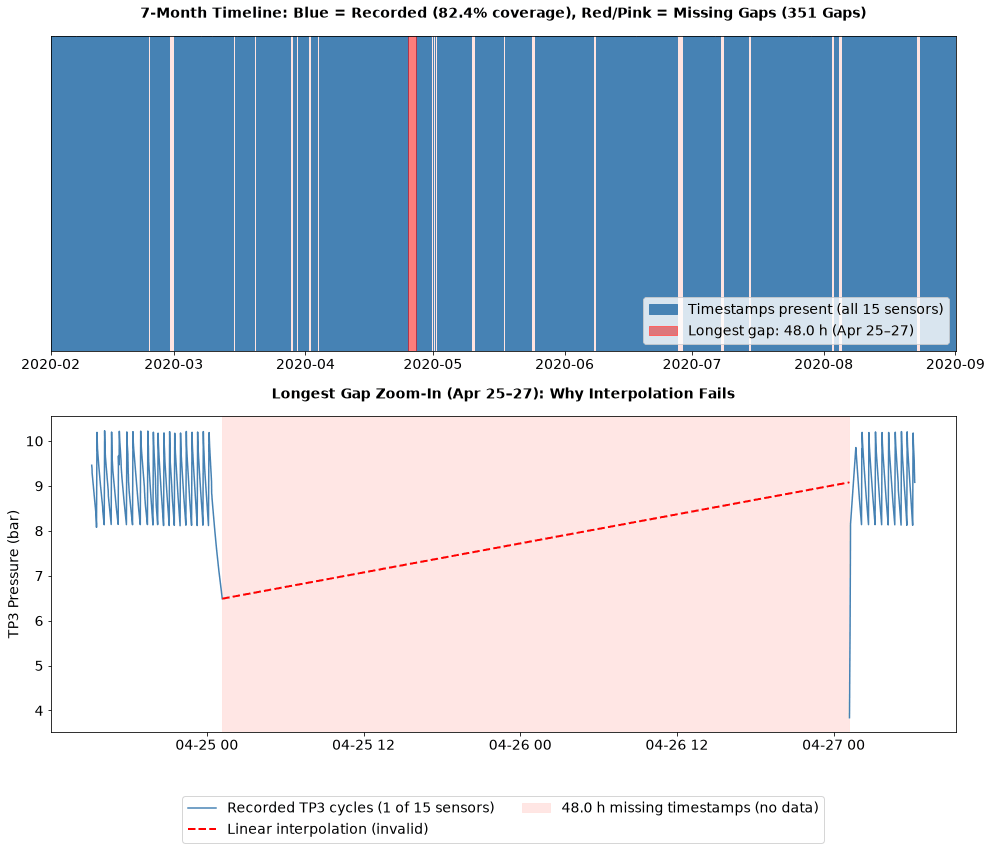

In [15]:
plt.rcParams.update({"font.size": 14})
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12))

# Get the exact longest gap directly from the table above shoiwng all the gaps 
# (Apr 25 01:10:51 to Apr 27 01:12:49)
longest = gaps.loc[gaps["duration_h"].idxmax()]
tp3 = pd.Series(df["TP3"].values, index=parsed_timestamps).sort_index()

# Recorded blocks (blue) vs. Missing gaps (pink/red background)
hourly_present = tp3.resample("1h").count() > 0   

ax1.set_facecolor("mistyrose")
ax1.fill_between(hourly_present.index, 0, 1, where=hourly_present, step="post", color="steelblue", label="Timestamps present (all 15 sensors)")
ax1.axvspan(longest["gap_start"], longest["gap_end"], color="red", alpha=0.45, label=f"Longest gap: {longest['duration_h']:.1f} h (Apr 25–27)")

ax1.set_xlim(hourly_present.index.min(), hourly_present.index.max()) 
# makes sure automatic margins are not highlighting outside data acquisition period (before and ftaer April and September)
ax1.set_ylim(0, 1)
ax1.set_yticks([])
ax1.set_title("7-Month Timeline: Blue = Recorded (82.4% coverage), Red/Pink = Missing Gaps (351 Gaps)", fontweight="bold", pad = 18, fontsize = 14)
ax1.legend(loc="lower right")

# 48.0h gap on TP3 pressure sensor
before = tp3.loc[longest["gap_start"] - pd.Timedelta(hours=10) : longest["gap_start"]]
after  = tp3.loc[longest["gap_end"] : longest["gap_end"] + pd.Timedelta(hours=5)]

ax2.plot(before, color="steelblue", label="Recorded TP3 cycles (1 of 15 sensors)")
ax2.plot(after, color="steelblue")
ax2.plot([before.index[-1], after.index[0]], [before.iloc[-1], after.iloc[-1]], color="red", linestyle="--", linewidth=2, label="Linear interpolation (invalid)")

ax2.axvspan(longest["gap_start"], longest["gap_end"], color="mistyrose", alpha=0.9, label="48.0 h missing timestamps (no data)")
ax2.set_title("Longest Gap Zoom-In (Apr 25–27): Why Interpolation Fails", fontweight="bold", pad = 18, fontsize = 14)
ax2.set_ylabel("TP3 Pressure (bar)", fontsize = 14)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=True)

plt.tight_layout()
plt.show()

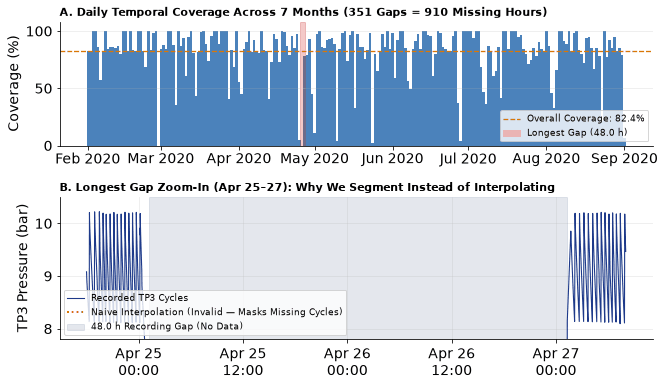

In [16]:
import matplotlib.dates as mdates

# Ensure timestamp is datetime and sorted
ts = pd.to_datetime(df["timestamp"])
s_tp3 = pd.Series(df["TP3"].to_numpy(), index=ts).sort_index()

# 1. Daily coverage (%) based on 8,640 expected rows and 10-second sampling frequency
daily_cov = (s_tp3.resample("D").size() / 8640 * 100).clip(upper=100)

# 2. Zoom window around the longest 48.0h gap (2020-04-25 01:10 to 2020-04-27 01:12)
zoom = s_tp3.loc["2020-04-24 18:00":"2020-04-27 08:00"]
gap_start = pd.Timestamp("2020-04-25 01:10:51")
gap_end   = pd.Timestamp("2020-04-27 01:12:49")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.5, 5.6), gridspec_kw={"height_ratios": [1, 1.15]})

# --- Top Panel: 7-Month Daily Coverage ---
ax1.bar(daily_cov.index, daily_cov.values, width=1.0, color="#2b6cb0", alpha=0.85)
ax1.axhline(82.4, color="#d97706", linestyle="--", linewidth=1.3, label="Overall Coverage: 82.4%")
ax1.axvspan(gap_start, gap_end, color="#dc2626", alpha=0.25, label="Longest Gap (48.0 h)")
ax1.set_title("A. Daily Temporal Coverage Across 7 Months (351 Gaps = 910 Missing Hours)", fontsize=10.5, fontweight="bold", loc="left")
ax1.set_ylabel("Coverage (%)")
ax1.set_ylim(0, 108)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax1.legend(loc="lower right", fontsize=8.5, frameon=True)
ax1.grid(axis="y", alpha=0.25)
ax1.spines[["top", "right"]].set_visible(False)

# --- Bottom Panel: Zoom into the 48h Gap ---
pre_gap  = zoom.loc[:gap_start]
post_gap = zoom.loc[gap_end:]

ax2.plot(pre_gap.index, pre_gap.values, color="#1e3a8a", linewidth=1.1, label="Recorded TP3 Cycles")
ax2.plot(post_gap.index, post_gap.values, color="#1e3a8a", linewidth=1.1)

# Show what naive linear interpolation would wrongly draw across the 48h gap
ax2.plot(
    [pre_gap.index[-1], post_gap.index[0]],
    [pre_gap.iloc[-1], post_gap.iloc[0]],
    color="#dc2626", linestyle=":", linewidth=1.8,
    label="Naive Interpolation (Invalid — Masks Missing Cycles)"
)
ax2.axvspan(gap_start, gap_end, color="#94a3b8", alpha=0.25, label="48.0 h Recording Gap (No Data)")

ax2.set_title("B. Longest Gap Zoom-In (Apr 25–27): Why We Segment Instead of Interpolating", fontsize=10.5, fontweight="bold", loc="left")
ax2.set_ylabel("TP3 Pressure (bar)")
ax2.set_ylim(7.8, 10.5)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
ax2.legend(loc="lower left", fontsize=8.5, frameon=True)
ax2.grid(alpha=0.25)
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("figures/slide18_recording_gaps.png", dpi=300, bbox_inches="tight")
plt.show()

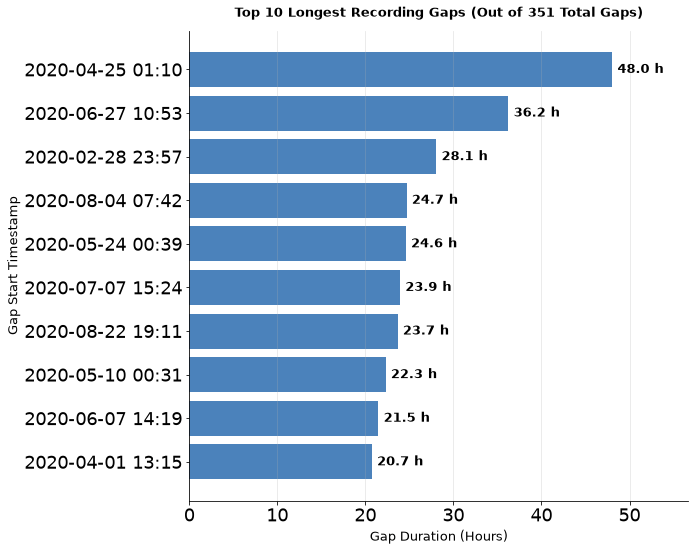

In [17]:
plt.rcParams.update({"font.size": 18})

top10 = gaps.nlargest(10, "duration_h").sort_values("duration_h")

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(
    top10["gap_start"].dt.strftime("%Y-%m-%d %H:%M"),
    top10["duration_h"],
    color="#2b6cb0",
    alpha=0.85
)
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f} h",
        ha="left",
        va="center",
        fontsize=13,
        fontweight="bold"
    )

ax.set_title("Top 10 Longest Recording Gaps (Out of 351 Total Gaps)", fontweight="bold", pad=14, fontsize=13)
ax.set_xlabel("Gap Duration (Hours)", fontsize=13)
ax.set_ylabel("Gap Start Timestamp", fontsize=13)
ax.set_xlim(0, top10["duration_h"].max() * 1.18) 
ax.grid(axis="x", alpha=0.3)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

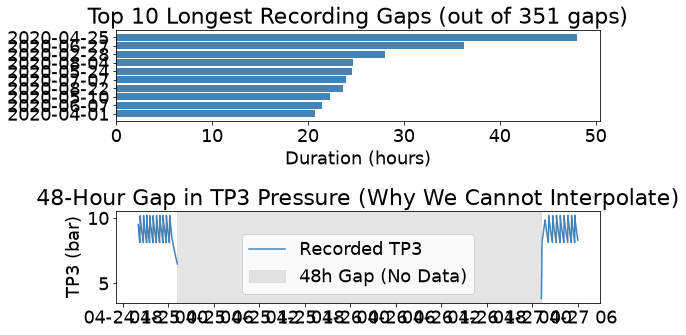

In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5))

# 1. Top 10 longest gaps (using `gaps` from Section 3.4)
top10 = gaps.nlargest(10, "duration_h").sort_values("duration_h")
ax1.barh(top10["gap_start"].dt.strftime("%Y-%m-%d"), top10["duration_h"], color="steelblue")
ax1.set_title("Top 10 Longest Recording Gaps (out of 351 gaps)")
ax1.set_xlabel("Duration (hours)")

# 2. Zoom into the 48h gap on TP3 (Apr 25–27)
tp3 = pd.Series(df["TP3"].values, index=parsed_timestamps).sort_index()
ax2.plot(tp3.loc["2020-04-24 20:00":"2020-04-25 01:11"], color="steelblue", label="Recorded TP3")
ax2.plot(tp3.loc["2020-04-27 01:12":"2020-04-27 06:00"], color="steelblue")
ax2.axvspan(pd.Timestamp("2020-04-25 01:11"), pd.Timestamp("2020-04-27 01:12"),
            color="lightgrey", alpha=0.6, label="48h Gap (No Data)")
ax2.set_title("48-Hour Gap in TP3 Pressure (Why We Cannot Interpolate)")
ax2.set_ylabel("TP3 (bar)")
ax2.legend()

plt.tight_layout()
plt.show()

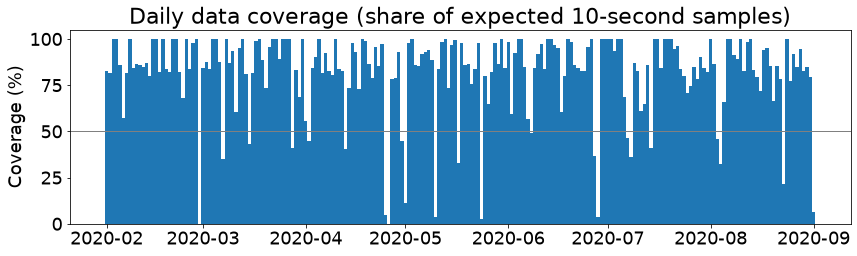

Days with less than 50% coverage: 23
Days without any data: 2


In [19]:
# Share of expected samples per day
samples_per_day = pd.Timedelta(days=1) / sampling_step
daily_coverage = (pd.Series(1, index=parsed_timestamps).resample('D').size() / samples_per_day * 100).clip(upper=100)

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(daily_coverage.index, daily_coverage, width=1)
ax.axhline(50, color='grey', linewidth=1)
ax.set_title('Daily data coverage (share of expected 10-second samples)')
ax.set_ylabel('Coverage (%)')
plt.show()

print('Days with less than 50% coverage:', (daily_coverage < 50).sum())
print('Days without any data:', (daily_coverage == 0).sum())

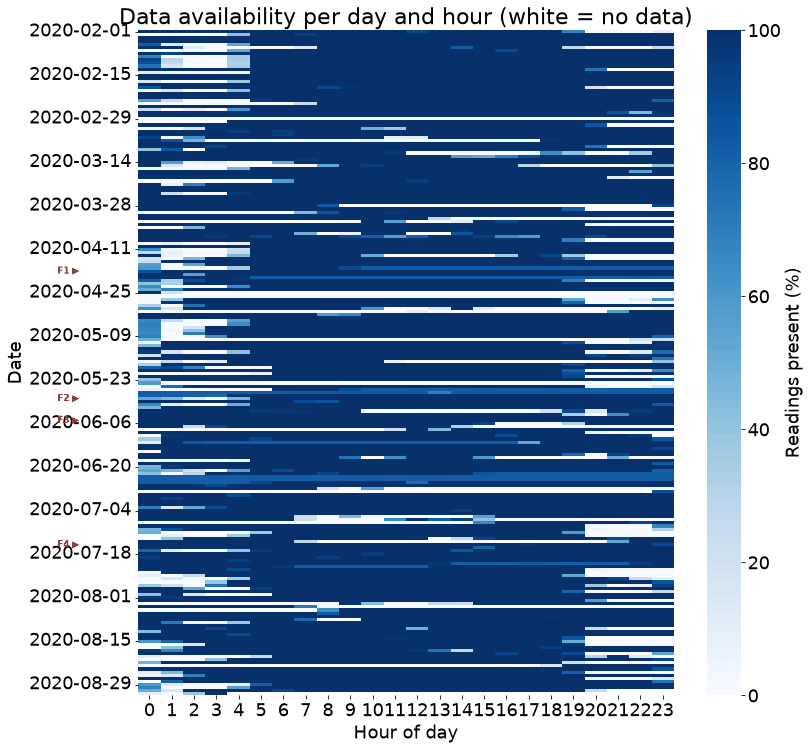

Hours with no data at all:   700 of 5,136 (13.6%)
Hours with complete data:    3,840 (74.8%)


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Average availability (%),66.4,63.1,64.7,69.5,77.4,87.5,90.6,89.8,89.2,89.9,...,87.7,88.7,88.2,88.2,89.4,86.7,72.4,72.1,71.8,75.1


In [20]:
# Availability heatmap: share of expected readings per day (rows) and hour of day (columns)
readings_per_hour = pd.Series(1, index=parsed_timestamps).resample('h').size()
availability = (readings_per_hour / (pd.Timedelta(hours=1) / sampling_step) * 100).clip(upper=100)
availability = availability.to_frame('pct')
availability['date'] = availability.index.date
availability['hour'] = availability.index.hour
availability_matrix = availability.pivot(index='date', columns='hour', values='pct')

fig, ax = plt.subplots(figsize=(12, 12))
sns.heatmap(availability_matrix, cmap='Blues', vmin=0, vmax=100, yticklabels=14,
            cbar_kws={'label': 'Readings present (%)'}, ax=ax)
# Mark the days of the reported failures on the left edge
dates = list(availability_matrix.index)
for _, f in reported_failures.iterrows():
    row = dates.index(f['start'].date())
    ax.annotate(f"F{f['failure_id']} ▶", (-0.11, row + 0.5), xycoords=('axes fraction', 'data'),
                ha='right', va='center', color='red', fontsize=9, fontweight='bold')
ax.set_title('Data availability per day and hour (white = no data)')
ax.set_xlabel('Hour of day')
ax.set_ylabel('Date')
plt.show()

hourly = availability_matrix.stack()
print(f'Hours with no data at all:   {(hourly == 0).sum():,} of {hourly.size:,} ({100 * (hourly == 0).mean():.1f}%)')
print(f'Hours with complete data:    {(hourly >= 95).sum():,} ({100 * (hourly >= 95).mean():.1f}%)')
display(availability_matrix.mean().round(1).to_frame('Average availability (%)').T)

**Figure: availability heatmap.** Each row is a day and each column an hour; white means no data.

- **13.6%** of all hours have no data at all, while 74.8% are complete.
- Missing data is concentrated at **night and late evening**: between midnight and 3 a.m. only 63–70% of the expected readings exist, and between 8 p.m. and 11 p.m. about 72–75%, compared with 87–91% during the day. This fits a train that is parked outside service hours.
- Full white rows are whole days without data, for example 25–26 April (the 48-hour gap).
- The failure days (red markers) mostly have good coverage, which is important for evaluating the models.

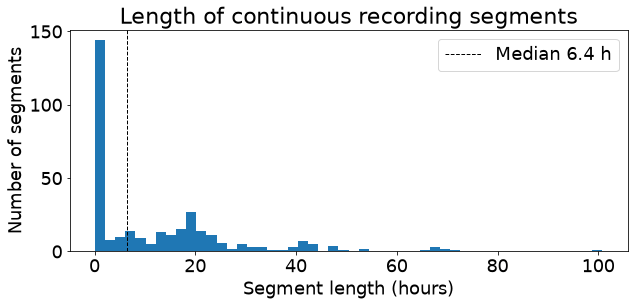

Segments: 332
Shorter than 30 minutes: 92  |  longer than 24 hours: 51


In [21]:
# Length of the continuous recording stretches between gaps longer than 1 minute
segment_number = (parsed_timestamps.diff() > pd.Timedelta(minutes=1)).cumsum()
segment_hours = parsed_timestamps.groupby(segment_number).agg(
    lambda s: (s.max() - s.min()).total_seconds() / 3600)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(segment_hours, bins=50)
ax.axvline(segment_hours.median(), color='black', linestyle='--', linewidth=1,
           label=f'Median {segment_hours.median():.1f} h')
ax.set_title('Length of continuous recording segments')
ax.set_xlabel('Segment length (hours)')
ax.set_ylabel('Number of segments')
ax.legend()
plt.show()

print(f'Segments: {len(segment_hours)}')
print(f'Shorter than 30 minutes: {(segment_hours < 0.5).sum()}  |  longer than 24 hours: {(segment_hours > 24).sum()}')

**Figure: segment lengths.** Splitting the data at every pause longer than 1 minute gives **332 continuous segments**. Their median length is about 6.4 hours, but 92 segments are shorter than 30 minutes and 51 are longer than 24 hours. Short segments cannot provide enough history for rolling-window features; this is taken into account in the Modeling phase.

**Finding:** No column contains empty values (NaN). However, **whole records are missing**:

- Only **82.4%** of the expected 10-second readings exist (1,516,948 of 1,841,760).
- There are **351 gaps** longer than 20 seconds, adding up to **910 hours** without data. The longest gap lasts 48 hours (25–27 April 2020).
- 23 days have less than 50% coverage and 2 days have no data at all.

The gaps most likely occur when the train is out of service or the data logger is switched off. They matter for the analysis because a model needs data *before* a failure in order to warn early. The gaps are not filled; they are marked as segment boundaries in Data Preparation (4.3).

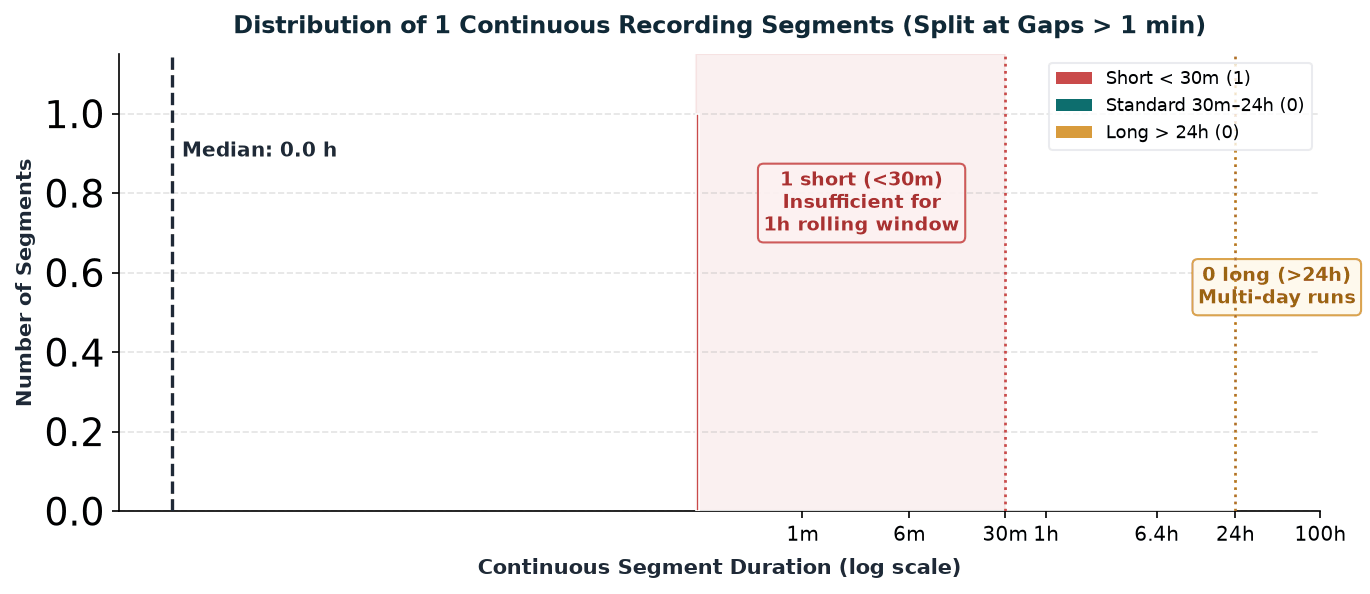

In [22]:
from matplotlib.patches import Patch

# coonvert df index to a series, sort it, drop the index, store it in a timestamp
ts = pd.to_datetime(df.index.to_series()).sort_values().reset_index(drop=True)

# Find recording gaps [ segments where (gap > 1 min)] and durations in hours
segment_id = (ts.diff() > pd.Timedelta(minutes=1)).cumsum()
# find total number of recording pauses within a segment greater than 1 minute.

segment_hours = ts.groupby(segment_id).agg(
    lambda s: (s.max() - s.min()).total_seconds() / 3600
)
# total number of minutes of all pauses lasted for in each segment

plot_hours = segment_hours.clip(lower=10 / 3600)

n_total = len(segment_hours)
n_short = (segment_hours < 0.5).sum()
n_long = (segment_hours > 24).sum()
n_mid = n_total - n_short - n_long
med_h = segment_hours.median()

# 3. Create log-spaced bins aligned cleanly with 0.5h (30m) and 24h thresholds
bins_short = np.logspace(np.log10(plot_hours.min()), np.log10(0.5), 11)
bins_mid = np.logspace(np.log10(0.5), np.log10(24.0), 15)
bins_long = np.logspace(np.log10(24.0), np.log10(plot_hours.max() * 1.05), 8)
bins = np.unique(np.concatenate([bins_short, bins_mid, bins_long]))

# 4. Plot sized & color-matched to Slide 18
fig, ax = plt.subplots(figsize=(9.5, 4.3), dpi=150)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

counts, edges, patches = ax.hist(plot_hours, bins=bins, edgecolor='white', linewidth=0.8, zorder=3)

# Color bars by operational regime (Coral = <30m, Teal = 30m–24h, Gold = >24h)
for left, right, patch in zip(edges[:-1], edges[1:], patches):
    mid_bin = np.sqrt(left * right)
    if mid_bin < 0.5:
        patch.set_facecolor('#c94a4a')   # Coral/Red: too short for 1h rolling window
    elif mid_bin > 24.0:
        patch.set_facecolor('#d89b3c')   # Gold/Ochre: multi-day continuous runs
    else:
        patch.set_facecolor('#0d6e6e')   # Slide Teal: standard operational runs

# Shaded zone for unusable short segments (< 30 min)
ax.axvspan(plot_hours.min(), 0.5, color='#c94a4a', alpha=0.08, zorder=1)
ax.axvline(0.5, color='#c94a4a', linestyle=':', linewidth=1.3, zorder=4)
ax.axvline(24.0, color='#b87d1e', linestyle=':', linewidth=1.3, zorder=4)

# Median reference line
ax.axvline(med_h, color='#1f2937', linestyle='--', linewidth=1.6, zorder=5)

# Direct annotations inside the plot
y_max = counts.max()
ax.text( 0.045, y_max * 0.86, f'{n_short} short (<30m)\nInsufficient for\n1h rolling window', color='#a83232', fontsize=9, fontweight='bold', ha='center', va='top',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#fdf2f2', edgecolor='#c94a4a', alpha=0.9)
)
ax.text(
    med_h * 1.18, y_max * 0.93,
    f'Median: {med_h:.1f} h',
    color='#1f2937', fontsize=9.5, fontweight='bold', va='top'
)
ax.text( 48, y_max * 0.62, f'{n_long} long (>24h)\nMulti-day runs', color='#9a6512', fontsize=9, fontweight='bold', ha='center', va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='#fef9ec', edgecolor='#d89b3c', alpha=0.9))

ax.set_xscale('log')
tick_vals = [1/60, 0.1, 0.5, 1, 6.4, 24, 100]
tick_labels = ['1m', '6m', '30m', '1h', '6.4h', '24h', '100h']
ax.set_xticks(tick_vals)
ax.set_xticklabels(tick_labels, fontsize=9.5)
ax.minorticks_off()

ax.set_ylim(0, y_max * 1.15)
ax.set_xlabel('Continuous Segment Duration (log scale)', fontsize=10, fontweight='bold', color='#1f2937', labelpad=6)
ax.set_ylabel('Number of Segments', fontsize=10, fontweight='bold', color='#1f2937')
ax.set_title(f'Distribution of {n_total} Continuous Recording Segments (Split at Gaps > 1 min)',
             fontsize=11.5, fontweight='bold', color='#0f2937', pad=10)

legend_handles = [
    Patch(facecolor='#c94a4a', label=f'Short < 30m ({n_short})'),
    Patch(facecolor='#0d6e6e', label=f'Standard 30m–24h ({n_mid})'),
    Patch(facecolor='#d89b3c', label=f'Long > 24h ({n_long})')
]
ax.legend(handles=legend_handles, loc='upper right', frameon=True, facecolor='white', edgecolor='#e5e7eb', fontsize=8.5)

ax.grid(axis='y', linestyle='--', alpha=0.35, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

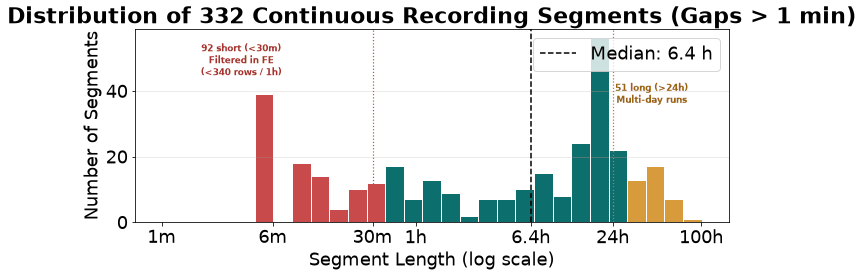

In [23]:
# 1. Compute continuous segments (gaps > 1 min) and durations in hours
segment_number = (parsed_timestamps.diff() > pd.Timedelta(minutes=1)).cumsum()
segment_hours = parsed_timestamps.groupby(segment_number).agg(
    lambda s: (s.max() - s.min()).total_seconds() / 3600
)

# 2. Log-spaced bins so both short (<30m) and multi-day (>24h) segments show clearly
hours_clipped = segment_hours.clip(lower=1/60)
bins = np.logspace(np.log10(1/60), np.log10(hours_clipped.max()), 30)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
counts, edges, patches = ax.hist(hours_clipped, bins=bins, color='#0d6e6e', edgecolor='white')

# Color-code short (<30m) and long (>24h) segments
for left, patch in zip(edges[:-1], patches):
    if left < 0.5:
        patch.set_facecolor('#c94a4a')
    elif left >= 24:
        patch.set_facecolor('#d89b3c')

# Threshold lines & annotations
ax.axvline(0.5, color='#c94a4a', linestyle=':', linewidth=1.2)
ax.axvline(segment_hours.median(), color='black', linestyle='--', linewidth=1.5,
           label=f'Median: {segment_hours.median():.1f} h')
ax.axvline(24, color='#b87d1e', linestyle=':', linewidth=1.2)

ax.text(0.06, counts.max() * 0.80, '92 short (<30m)\nFiltered in FE\n(<340 rows / 1h)',
        color='#a83232', fontsize=9, fontweight='bold', ha='center')
ax.text(45, counts.max() * 0.65, '51 long (>24h)\nMulti-day runs',
        color='#9a6512', fontsize=9, fontweight='bold', ha='center')

# Clean log axis formatting
ax.set_xscale('log')
ax.set_xticks([1/60, 0.1, 0.5, 1, 6.4, 24, 100])
ax.set_xticklabels(['1m', '6m', '30m', '1h', '6.4h', '24h', '100h'])
ax.minorticks_off()
ax.set_title('Distribution of 332 Continuous Recording Segments (Gaps > 1 min)', fontweight='bold')
ax.set_xlabel('Segment Length (log scale)')
ax.set_ylabel('Number of Segments')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

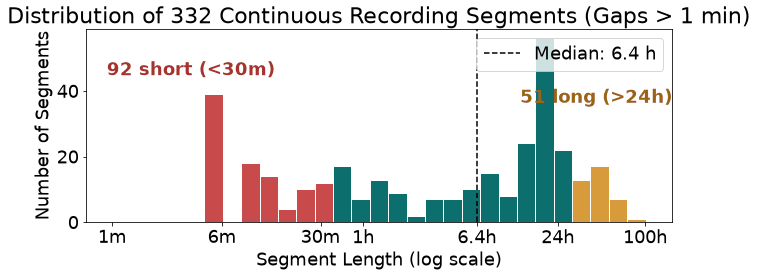

In [24]:
segment_number = (parsed_timestamps.diff() > pd.Timedelta(minutes=1)).cumsum()
segment_hours = parsed_timestamps.groupby(segment_number).agg(lambda s: (s.max() - s.min()).total_seconds() / 3600)

hours = segment_hours.clip(lower=1/60)
bins = np.logspace(np.log10(1/60), np.log10(hours.max()), 30)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
counts, edges, patches = ax.hist(hours, bins=bins, color='#0d6e6e', edgecolor='white')

for left, patch in zip(edges[:-1], patches):
    if left < 0.5: patch.set_facecolor('#c94a4a')
    elif left >= 24: patch.set_facecolor('#d89b3c')

ax.axvline(segment_hours.median(), color='black', ls='--', lw=1.5, label=f'Median: {segment_hours.median():.1f} h')
ax.text(0.06, counts.max() * 0.8, '92 short (<30m)', color='#a83232', fontweight='bold', ha='center')
ax.text(45, counts.max() * 0.65, '51 long (>24h)', color='#9a6512', fontweight='bold', ha='center')

ax.set(xscale='log', title='Distribution of 332 Continuous Recording Segments (Gaps > 1 min)',
       xlabel='Segment Length (log scale)', ylabel='Number of Segments')
ax.set_xticks([1/60, 0.1, 0.5, 1, 6.4, 24, 100], ['1m', '6m', '30m', '1h', '6.4h', '24h', '100h'])
ax.minorticks_off()
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

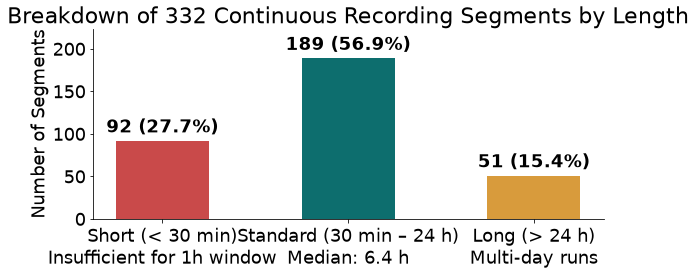

In [25]:
# Use the actual timestamp column (not the integer row index)
raw_ts = df['timestamp'] if 'timestamp' in df.columns else df.index
ts = pd.Series(pd.to_datetime(raw_ts)).sort_values().reset_index(drop=True)

# Split at gaps > 1 minute and compute each segment's length in hours
segment_id = (ts.diff() > pd.Timedelta(minutes=1)).cumsum()
segment_hours = ts.groupby(segment_id).agg(lambda s: (s.max() - s.min()).total_seconds() / 3600)

# Group the 332 segments into 3 categories
categories = pd.cut(segment_hours, bins=[-np.inf, 0.5, 24, np.inf], labels=['Short (< 30 min)\nInsufficient for 1h window', 'Standard (30 min – 24 h)\nMedian: 6.4 h',
            'Long (> 24 h)\nMulti-day runs'],
    right=False
)
counts = categories.value_counts().sort_index()

# 4. Draw the 3-bar chart
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bars = ax.bar(counts.index, counts.values, color=['#c94a4a', '#0d6e6e', '#d89b3c'], width=0.5)

labels = [f'{v} ({v / len(segment_hours) * 100:.1f}%)' for v in counts.values]
ax.bar_label(bars, labels=labels, padding=4, fontweight='bold')

ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel('Number of Segments')
ax.set_title(f'Breakdown of {len(segment_hours)} Continuous Recording Segments by Length')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

#### 3.4.3 Duplicate data / Uniqueness

In [26]:
# Count fully duplicated rows.
# 'Unnamed: 0' is a running index and unique by construction, so it is excluded from the check.
df.drop(columns='Unnamed: 0').duplicated().sum()

np.int64(0)

In [27]:
# Two readings with the same timestamp would also be duplicates
print('Duplicate timestamps:', df['timestamp'].duplicated().sum())
print('Timestamps in chronological order:', parsed_timestamps.is_monotonic_increasing)

Duplicate timestamps: 0
Timestamps in chronological order: True


In [28]:
#Returning the number of unique values in a column
df.nunique()

Unnamed: 0         1516948
timestamp          1516948
TP2                   5257
TP3                   3683
H1                    2665
DV_pressure           2257
Reservoirs            3682
Oil_temperature       2462
Motor_current         1809
COMP                     2
DV_eletric               2
Towers                   2
MPG                      2
LPS                      2
Pressure_switch          2
Oil_level                2
Caudal_impulses          2
dtype: int64

**Finding:** There are **no duplicate rows** and **no duplicate timestamps**, and the timestamps are in chronological order.
The counts of unique values confirm the scales from the description table: the digital signals have exactly two values (0 and 1), and `Unnamed: 0` is unique for every row because it is only a running index.

#### 3.4.4 Inaccurate data / Accuracy

In [29]:
# Plausible value ranges per sensor, based on the dataset description.
# Pressures are allowed down to -0.05 bar to tolerate the sensors' zero offset.
plausible_ranges = {
    'TP2': (-0.05, 11), 'TP3': (-0.05, 11), 'H1': (-0.05, 11),
    'DV_pressure': (-0.05, 11), 'Reservoirs': (-0.05, 11),
    'Oil_temperature': (0, 120), 'Motor_current': (0, 10)
}

accuracy = []
for col, (low, high) in plausible_ranges.items():
    values = df[col]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    accuracy.append({
        'Sensor': col,
        'Min': values.min(),
        'Max': values.max(),
        'Negative values (%)': 100 * (values < 0).mean(),
        'Outside plausible range (%)': 100 * ((values < low) | (values > high)).mean(),
        'Statistical outliers, 1.5 IQR (%)': 100 * ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).mean()
    })

display(pd.DataFrame(accuracy).round(3))

,Sensor,Min,Max,Negative values (%),Outside plausible range (%),"Statistical outliers, 1.5 IQR (%)"
0,TP2,-0.032,10.676,84.082,0.0,17.772
1,TP3,0.730,10.302,0.000,0.0,0.298
2,H1,-0.036,10.288,15.689,0.0,15.909
3,DV_pressure,-0.032,9.844,95.191,0.0,7.456
4,Reservoirs,0.712,10.300,0.000,0.0,0.298
5,Oil_temperature,15.400,89.050,0.000,0.0,0.342
6,Motor_current,0.020,9.295,0.000,0.0,0.000


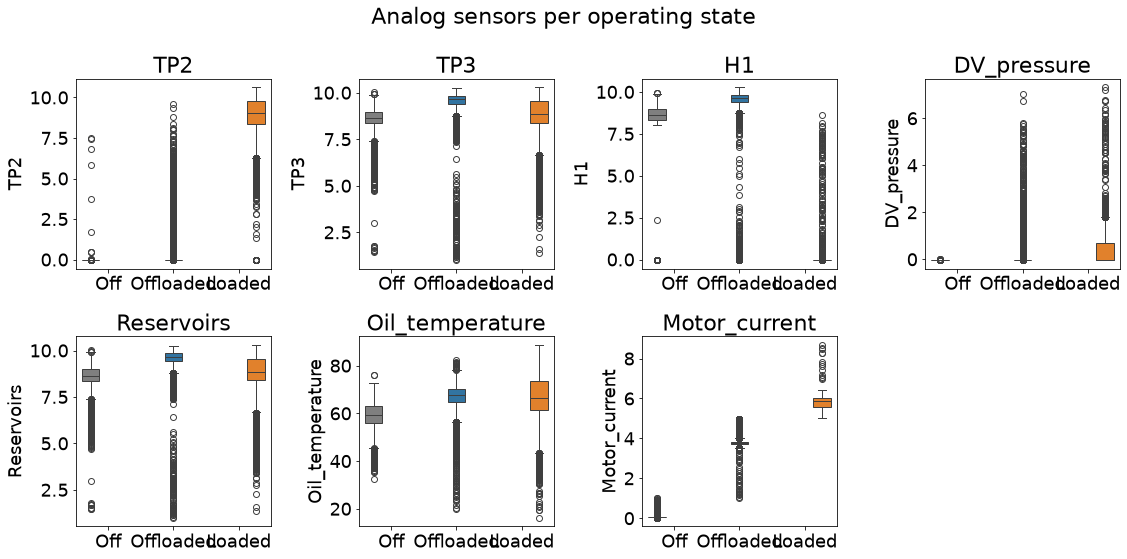

,"Outliers, all data (%)",Outliers within operating state (%)
TP2,17.8,5.8
TP3,0.3,1.4
H1,15.9,2.3
DV_pressure,7.5,5.1
Reservoirs,0.3,1.4
Oil_temperature,0.3,1.4
Motor_current,0.0,5.3


In [30]:
# Boxplots per operating state: are the 'outliers' errors or just a different operating state?
sample = df[analog_columns].assign(state=operating_state).sample(200_000, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), analog_columns):
    sns.boxplot(data=sample, x='state', y=col, hue='state', palette=state_colors, legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
axes.flatten()[-1].axis('off')
plt.suptitle('Analog sensors per operating state')
plt.tight_layout()
plt.show()

# Share of IQR outliers: over all data vs. within each operating state
def iqr_outliers(values):
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)

state_outliers = pd.DataFrame({
    col: df[col].groupby(operating_state, observed=True).transform(iqr_outliers).astype(bool)
    for col in analog_columns
})
outlier_comparison = pd.DataFrame({
    'Outliers, all data (%)': [100 * iqr_outliers(df[col]).mean() for col in analog_columns],
    'Outliers within operating state (%)': [100 * state_outliers[col].mean() for col in analog_columns],
}, index=analog_columns).round(1)
display(outlier_comparison)

**Figure: sensors per operating state.** Splitting the boxplots of 3.5.1 by operating state shows why most "outliers" are not errors:

| Sensor | Outliers, all data | Outliers within operating state |
|---|---|---|
| TP2 | 17.8% | 5.8% |
| H1 | 15.9% | 2.3% |
| DV_pressure | 7.5% | 5.1% |

Within one state each sensor has a narrow, clearly defined level (for example, motor current about 3.8 A offloaded and about 5.8 A loaded; TP3 about 9.6 bar offloaded). The high outlier share over all data came from mixing these states. For TP3, Reservoirs, Oil_temperature and Motor_current the share rises slightly within a state (to 1.4–5.3%), because the boxes become so narrow that readings taken during a switch between states are counted as outliers.

**Finding:** No value lies outside the physically plausible range of its sensor.

- **Negative pressures** (down to −0.036 bar) appear in 84% of TP2 readings and 95% of DV_pressure readings. These are not errors: they are the sensors' zero offset while the compressor is idle and the pressure is effectively 0 bar.
- **Statistical outliers** (1.5 × IQR rule) are frequent for TP2 (17.8%), H1 (15.9%) and DV_pressure (7.5%). These sensors switch between two levels depending on the operating state (idle vs. loaded), so the IQR rule flags normal operation as "outliers" (see also the boxplots in 3.5.1).
- Outliers are therefore **kept**. Removing them would delete exactly the operating behaviour that changes during an air leak.

#### 3.4.5 Out-of-date data / Timeliness

In [31]:
start, end = parsed_timestamps.min(), parsed_timestamps.max()
print(f'Data period: {start} to {end} ({(end - start).days} days)')

# Rows per month: is every month represented?
display(df.groupby(parsed_timestamps.dt.to_period('M')).size().rename('rows').to_frame())

# Regularity of the sampling interval
interval_s = parsed_timestamps.diff().dt.total_seconds().dropna()
display(interval_s.value_counts().head(6).rename('count').to_frame())
print(f'Intervals that differ from {sampling_step.total_seconds():.0f} s: '
      f'{100 * (interval_s != sampling_step.total_seconds()).mean():.1f}%')

Data period: 2020-02-01 00:00:00 to 2020-09-01 03:59:50 (213 days)


,rows
timestamp,
2020-02,214850
2020-03,230448
2020-04,198734
2020-05,212800
2020-06,216514
2020-07,222638
2020-08,220434
2020-09,530


,count
timestamp,
10.0,1337521
9.0,128277
12.0,38321
13.0,7988
11.0,4471
21.0,10


Intervals that differ from 10 s: 11.8%


**Finding:**

- The data covers **1 February to 1 September 2020 (213 days)**. September contains only the first four hours (530 rows), so it is effectively February to August.
- Every month from February to August has a similar number of records (199,000–230,000).
- The sampling interval is mostly 10 seconds, but **11.8%** of intervals are 9–13 seconds. Time-window features should therefore be based on timestamps, not on a fixed number of rows.
- The original logger recorded at 1 Hz; this CSV is downsampled to about 10 seconds. Very short events (for example the ~9 A start-up current peak) are mostly lost.
- The data is from 2020. For this study the age is acceptable, because the goal is to test a method on documented historical failures, not to monitor the current fleet.

#### 3.4.6 Invalid data / Consistency

In [32]:
# Cross-checks between signals that should agree according to the dataset description
consistency = {
    'TP3 and Reservoirs within 0.1 bar': (df['TP3'] - df['Reservoirs']).abs() < 0.1,
    'COMP equals MPG': df['COMP'] == df['MPG'],
    'DV_eletric is the opposite of COMP': df['DV_eletric'] == 1 - df['COMP'],
}
loaded = df['Motor_current'] > 5
consistency['DV_eletric = 1 when Motor_current > 5 A'] = df.loc[loaded, 'DV_eletric'] == 1

display(pd.Series({name: 100 * check.mean() for name, check in consistency.items()},
                  name='Consistent rows (%)').round(2).to_frame())

,Consistent rows (%)
TP3 and Reservoirs within 0.1 bar,100.00
COMP equals MPG,99.57
DV_eletric is the opposite of COMP,98.90
DV_eletric = 1 when Motor_current > 5 A,98.09


In [33]:
# Very long periods with an unchanged value can indicate a stuck sensor
def longest_constant_run_hours(values, times):
    starts = np.flatnonzero(values.ne(values.shift()).to_numpy())
    ends = np.append(starts[1:] - 1, len(values) - 1)
    t = times.to_numpy()
    return ((t[ends] - t[starts]) / np.timedelta64(1, 'h')).max()

constant_runs = {col: longest_constant_run_hours(df[col], parsed_timestamps)
                 for col in analog_columns + digital_columns}
display(pd.Series(constant_runs, name='Longest constant run (h)').round(1).to_frame())

,Longest constant run (h)
TP2,62.0
TP3,62.0
H1,62.0
DV_pressure,62.1
Reservoirs,62.0
Oil_temperature,62.0
Motor_current,62.0
COMP,76.1
DV_eletric,76.1
Towers,48.1


In [34]:
# Frozen readings: all seven analog sensors repeat exactly the same value for many readings in a row.
# A running compressor never does this (normal runs of identical readings last at most 2 rows), so it points to a logger fault.
analog_unchanged = df[analog_columns].diff().abs().sum(axis=1).eq(0)
run_id = (~analog_unchanged).cumsum()
frozen_rows = analog_unchanged & (analog_unchanged.groupby(run_id).transform('size') >= 30)   # 30 readings = about 5 minutes
print(f'Frozen readings: {frozen_rows.sum():,} ({100 * frozen_rows.mean():.1f}% of rows), about {frozen_rows.sum() * 10 / 3600:.0f} hours')

# Start and end of each frozen period (used to mark them in the charts of 3.5)
frozen_times = parsed_timestamps[frozen_rows]
frozen_periods = frozen_times.groupby(run_id[frozen_rows]).agg(['min', 'max'])
frozen_periods = frozen_periods[(frozen_periods['max'] - frozen_periods['min']) > pd.Timedelta(hours=1)]

def shade_frozen(ax):
    """Mark the frozen sensor periods with grey hatching."""
    for start, end in frozen_periods.itertuples(index=False):
        ax.axvspan(start, end, facecolor='none', edgecolor='#888888', hatch='///', linewidth=0)

per_day = frozen_rows.groupby(parsed_timestamps.dt.floor('D')).sum()
per_day = per_day[per_day > 0].to_frame('Frozen readings')
per_day['Hours'] = (per_day['Frozen readings'] * 10 / 3600).round(1)
per_day['Frozen Motor_current (A)'] = df.loc[frozen_rows, 'Motor_current'].groupby(parsed_timestamps[frozen_rows].dt.floor('D')).median()
display(per_day)

changes = df[digital_columns].diff().abs()
display(pd.DataFrame({'Normal readings': changes[~frozen_rows].mean() * 1000,
                      'Frozen readings': changes[frozen_rows].mean() * 1000}).round(1)
        .rename_axis('State changes per 1,000 readings'))

Frozen readings: 50,855 (3.4% of rows), about 141 hours


,Frozen readings,Hours,Frozen Motor_current (A)
timestamp,,,
2020-03-11,147,0.4,5.4025
2020-04-13,290,0.8,4.0975
2020-04-17,4378,12.2,0.0400
2020-04-18,91,0.3,0.0400
2020-04-20,5726,15.9,3.9225
2020-04-21,383,1.1,3.9225
2020-05-26,4377,12.2,0.0400
2020-05-27,7096,19.7,0.0400
2020-05-28,975,2.7,0.0400


,Normal readings,Frozen readings
"State changes per 1,000 readings",,
COMP,15.1,229.2
DV_eletric,15.1,182.5
Towers,31.7,356.1
MPG,15.1,173.7
LPS,0.2,0.0
Pressure_switch,3.8,356.1
Oil_level,0.0,300.5
Caudal_impulses,0.0,300.5


**Finding:** The signals are consistent with the dataset description:

- **TP3 and Reservoirs** agree within 0.1 bar in 100% of rows. The two sensors carry the same information, so one of them is redundant for modelling.
- **COMP and MPG** behave the same way in 99.6% of rows, and **DV_eletric** is the opposite of COMP in 98.9% of rows, as described by the manufacturer. The small differences are expected around switching moments.
- When the motor draws more than 5 A, the outlet valve (DV_eletric) is open in 98.1% of rows, confirming that high current means loaded operation.

**Frozen sensor periods (logger fault):** on 13 days all seven analog sensors repeat exactly the same value for hours, in total **50,855 readings (3.4% of rows, about 141 hours)**, the longest for 62 hours (22–25 June). During normal operation identical consecutive readings never last more than 2 rows, so this is not a parked train but a fault in the data logger: the analog values freeze while timestamps keep coming. At the same time the digital signals switch 10–20 times more often than normal, and **all** state changes of `Oil_level` and `Caudal_impulses` happen during these frozen periods. These readings do not describe the compressor and are flagged in Data Preparation (4.3).

`LPS` keeps the same value for more than 800 hours; it changes only once or twice a day when the pressure falls below 7 bar.

**Inconsistency in the failure reports:** for Failure 2 (29–30 May 2020) the dataset description lists the maintenance on 30 April 2020, which is *before* the failure. This date is not used in the analysis and should be checked against Veloso et al. (2022).

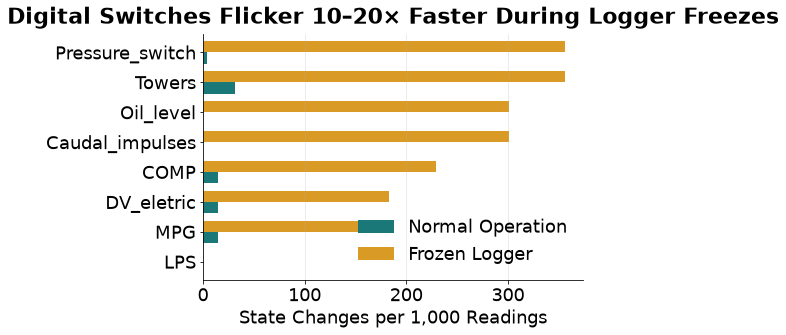

In [35]:
is_frozen = df['sensors_frozen'].astype(bool) if 'sensors_frozen' in df.columns else frozen_rows
changes = df[digital_columns].diff().abs()

summary = pd.DataFrame({
    'Normal Operation': changes[~is_frozen].mean() * 1000,
    'Frozen Logger': changes[is_frozen].mean() * 1000
}).sort_values('Frozen Logger')

ax = summary.plot(kind='barh', figsize=(8, 5), color=['#1b7878', '#d99b26'], width=0.75)
ax.set_title('Digital Switches Flicker 10–20× Faster During Logger Freezes', fontweight='bold', pad=10)
ax.set_xlabel('State Changes per 1,000 Readings')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

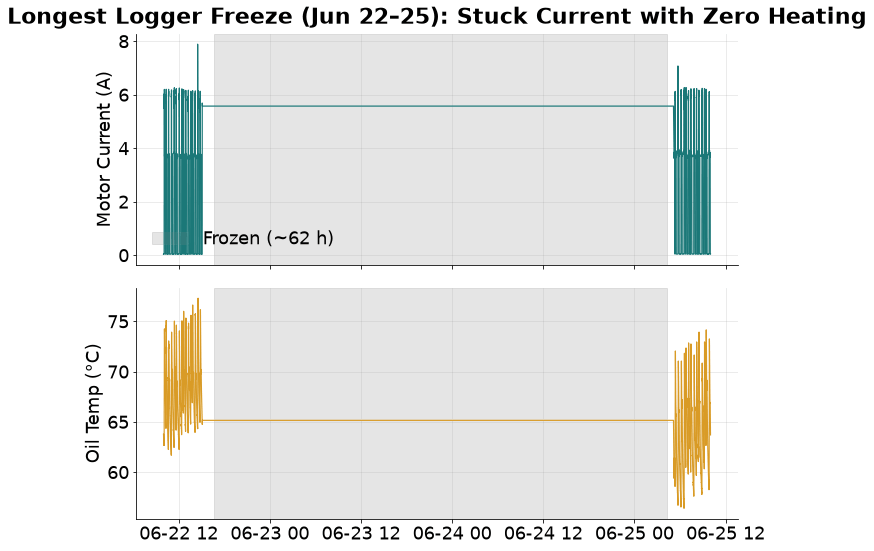

In [36]:
ts = pd.to_datetime(df['timestamp'])
sub = df.set_index(ts).loc['2020-06-22 10:00':'2020-06-25 10:00']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(sub.index, sub['Motor_current'], color='#1b7878', linewidth=1.2)
ax1.set_ylabel('Motor Current (A)')
ax1.set_title('Longest Logger Freeze (Jun 22–25): Stuck Current with Zero Heating', fontweight='bold', pad=10)

ax2.plot(sub.index, sub['Oil_temperature'], color='#d99b26', linewidth=1.2)
ax2.set_ylabel('Oil Temp (°C)')

for ax in (ax1, ax2):
    ax.axvspan(pd.Timestamp('2020-06-22 16:36'), pd.Timestamp('2020-06-25 04:15'), color='grey', alpha=0.2, label='Frozen (~62 h)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.3)

ax1.legend(frameon=False, loc='lower left')
plt.tight_layout()
plt.show()

In [37]:
sns.set_theme(style="whitegrid")

# check if the vairables exist in the nb first otherwise calculate them
ts = pd.to_datetime(df['timestamp'])
if 'sensors_frozen' in df.columns:
    frozen = df['sensors_frozen'].astype(bool)
elif 'frozen_rows' in globals():
    frozen = frozen_rows.astype(bool)
else:
    analog_unchanged = df[analog_columns].diff().abs().sum(axis=1).eq(0)
    run_id = (~analog_unchanged).cumsum()
    frozen = analog_unchanged & (analog_unchanged.groupby(run_id).transform('size') >= 30)

# Calculate monthly hours & overall percentages (Feb–Aug 2020)
months = pd.period_range('2020-02', '2020-08', freq='M')
total_h = pd.Series([m.days_in_month * 24 for m in months], index=months)

m_group = ts.dt.to_period('M')
usable_h = ((~frozen).groupby(m_group).sum() * 10 / 3600).reindex(months, fill_value=0)
frozen_h = (frozen.groupby(m_group).sum() * 10 / 3600).reindex(months, fill_value=0)
gap_h = (total_h - usable_h - frozen_h).clip(lower=0)

# Overall totals computed directly from the data
tot_all = total_h.sum()
u_pct_all = usable_h.sum() / tot_all * 100
f_pct_all = frozen_h.sum() / tot_all * 100
g_pct_all = gap_h.sum() / tot_all * 100

# Small summary table
summary_table = pd.DataFrame({
    'Category': ['Usable Sensor Data', 'Frozen Logger Faults', 'Missing Recording Gaps', 'Total (Feb–Aug 2020)'],
    'Hours': [usable_h.sum(), frozen_h.sum(), gap_h.sum(), tot_all],
    'Share (%)': [u_pct_all, f_pct_all, g_pct_all, 100.0]
}).round(1)
display(summary_table)


,Category,Hours,Share (%)
0,Usable Sensor Data,4071.0,79.6
1,Frozen Logger Faults,141.3,2.8
2,Missing Recording Gaps,899.7,17.6
3,Total (Feb–Aug 2020),5112.0,100.0


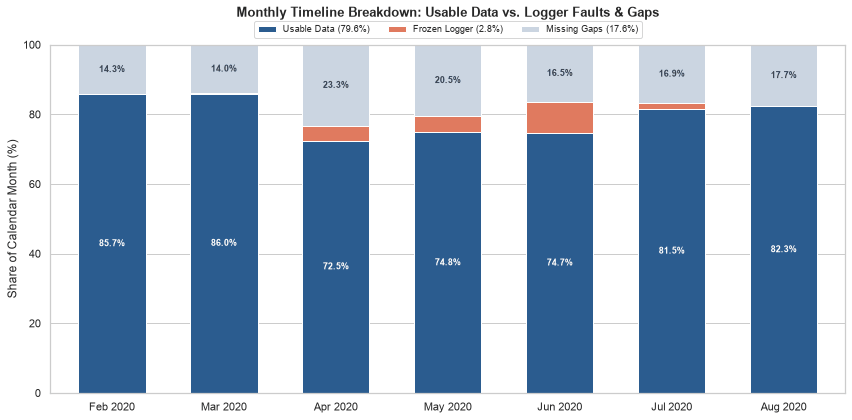

In [38]:
# stacked bar chart
monthly_pct = pd.DataFrame({
    f'Usable Data ({u_pct_all:.1f}%)': usable_h / total_h * 100,
    f'Frozen Logger ({f_pct_all:.1f}%)': frozen_h / total_h * 100,
    f'Missing Gaps ({g_pct_all:.1f}%)': gap_h / total_h * 100
}, index=months.strftime('%b %Y'))

fig, ax = plt.subplots(figsize=(12, 6))
monthly_pct.plot(kind='bar', stacked=True, ax=ax, width=0.6,
                 color=['#2b5c8f', '#e07a5f', '#cbd5e1'], edgecolor='white')

ax.bar_label(ax.containers[0], label_type='center', fmt='%.1f%%', color='white', fontweight='bold', fontsize=9)
ax.bar_label(ax.containers[2], label_type='center', fmt='%.1f%%', color='#334155', fontweight='bold', fontsize=9)

ax.set_title('Monthly Timeline Breakdown: Usable Data vs. Logger Faults & Gaps', fontsize=12.5, fontweight='bold', pad=28)
ax.set_ylabel('Share of Calendar Month (%)', fontsize=12)
ax.set_xlabel('')
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

In [39]:
# copy var to prevent accidental changes to the original variables.
analog_cols = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']
ts_series = pd.to_datetime(df['timestamp']) if 'timestamp' in df.columns else pd.Series(df.index, index=df.index)

# check if frozen_rows have already been identified; if variable does not exist, find frozen rows and store them
if 'frozen_rows' not in globals():
    analog_unchanged = df[analog_cols].diff().abs().sum(axis=1).eq(0)
    run_id = (~analog_unchanged).cumsum()
    frozen_rows = analog_unchanged & (analog_unchanged.groupby(run_id).transform('size') >= 30)

# Group by continuous freeze episode (run_id) rather than splitting at midnight;
tmp_frozen = df.loc[frozen_rows, analog_cols].copy()
tmp_frozen['timestamp'] = ts_series.loc[frozen_rows].values
tmp_frozen['episode_id'] = run_id.loc[frozen_rows].values

episodes = (
    tmp_frozen.groupby('episode_id')
    .agg(
        Start=('timestamp', 'min'),
        End=('timestamp', 'max'),
        Rows=('TP2', 'size'),
        **{col: (col, 'first') for col in analog_cols}
    )
    .reset_index(drop=True)
)
episodes['Duration (h)'] = (episodes['Rows'] * 10 / 3600).round(2)

# Reorder columns cleanly
display_cols = ['Start', 'End', 'Duration (h)', 'Rows'] + analog_cols
print(f"Total continuous freeze episodes: {len(episodes)} | Calendar days affected: {ts_series.loc[frozen_rows].dt.date.nunique()}")
display(episodes[display_cols].round(3))

Total continuous freeze episodes: 9 | Calendar days affected: 16


,Start,End,Duration (h),Rows,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
0,2020-03-11 18:29:54,2020-03-11 18:59:14,0.41,147,7.888,7.314,-0.010,-0.020,7.314,71.250,5.402
1,2020-04-13 18:29:20,2020-04-13 19:27:16,0.81,290,0.004,10.140,10.144,0.000,10.138,57.050,4.098
2,2020-04-17 09:20:43,2020-04-18 00:18:07,12.41,4469,-0.018,8.248,8.238,-0.024,8.248,49.450,0.040
3,2020-04-20 04:49:17,2020-04-21 01:16:52,16.97,6109,-0.014,9.728,9.718,-0.024,9.728,65.025,3.922
4,2020-05-26 09:19:36,2020-05-28 03:16:28,34.58,12448,-0.010,8.168,8.158,-0.018,8.170,64.600,0.040
5,2020-06-12 02:01:56,2020-06-12 17:06:06,12.50,4501,-0.016,8.284,8.274,-0.024,8.284,55.900,0.045
6,2020-06-22 15:06:21,2020-06-25 05:08:35,51.43,18514,8.390,8.506,-0.014,-0.014,8.506,65.150,5.575
7,2020-07-21 13:45:12,2020-07-21 22:03:16,6.89,2480,-0.010,8.496,8.482,-0.014,8.498,66.725,0.038
8,2020-07-22 06:43:44,2020-07-22 13:04:24,5.27,1897,-0.020,10.042,10.036,-0.018,10.038,73.650,3.742


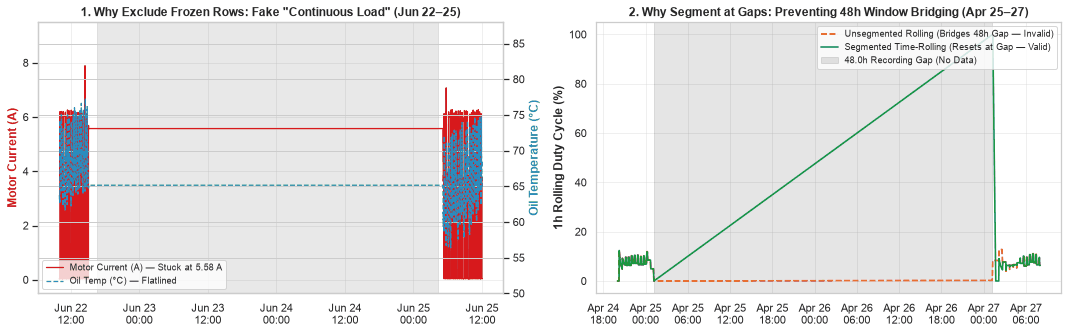

In [40]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# time-indexed slice for visualization without altering df
ts_clean = df[analog_cols + ['DV_eletric', 'Pressure_switch']].copy()
ts_clean.index = ts_series.values
ts_clean = ts_clean.sort_index()
ts_clean['is_loaded'] = (ts_clean['Motor_current'] >= 5.0).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# --- PANEL 1: Why Exclude Frozen Logger Periods (June 22–25, 62h Freeze) ---
freeze_win = ts_clean.loc['2020-06-22 10:00':'2020-06-25 12:00']
ax1 = axes[0]
ax1_twin = ax1.twinx()

l1 = ax1.plot(freeze_win.index, freeze_win['Motor_current'], color='#d7191c', linewidth=1.3, label='Motor Current (A) — Stuck at 5.58 A')
l2 = ax1_twin.plot(freeze_win.index, freeze_win['Oil_temperature'], color='#2b8cbe', linewidth=1.3, linestyle='--', label='Oil Temp (°C) — Flatlined')

ax1.axvspan(pd.Timestamp('2020-06-22 16:36'), pd.Timestamp('2020-06-25 04:15'), color='grey', alpha=0.18, label='Logger Freeze (~62 h)')
ax1.set_title('1. Why Exclude Frozen Rows: Fake "Continuous Load" (Jun 22–25)', fontweight='bold')
ax1.set_ylabel('Motor Current (A)', color='#d7191c', fontweight='bold')
ax1_twin.set_ylabel('Oil Temperature (°C)', color='#2b8cbe', fontweight='bold')
ax1.set_ylim(-0.5, 9.5)
ax1_twin.set_ylim(50, 88)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %d\n%H:%M'))
ax1.grid(alpha=0.3)

lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='lower left', fontsize=8.5)

# --- PANEL 2: Why Segment at Gaps (48h Outage on Apr 25–27) ---
gap_win = ts_clean.loc['2020-04-24 20:00':'2020-04-27 08:00'].copy()

# Naive rolling (360 rows = ~1h, ignores 48h gap & bridges across it)
gap_win['naive_duty_1h'] = gap_win['is_loaded'].rolling(360, min_periods=1).mean() * 100

# Proper segmented time-based rolling (resets cleanly after gaps > 1 min)
gap_win['seg_id'] = (gap_win.index.to_series().diff() > pd.Timedelta(minutes=1)).cumsum()
gap_win['segmented_duty_1h'] = (
    gap_win.groupby('seg_id')['is_loaded']
    .rolling('1h', min_periods=1).mean()
    .reset_index(level=0, drop=True) * 100
)

ax2 = axes[1]
ax2.plot(gap_win.index, gap_win['naive_duty_1h'], color='#e66101', linestyle='--', linewidth=1.6,
         label='Unsegmented Rolling (Bridges 48h Gap — Invalid)')
ax2.plot(gap_win.index, gap_win['segmented_duty_1h'], color='#1a9641', linewidth=1.6,
         label='Segmented Time-Rolling (Resets at Gap — Valid)')

ax2.axvspan(pd.Timestamp('2020-04-25 01:10:51'), pd.Timestamp('2020-04-27 01:12:49'),
            color='black', alpha=0.10, label='48.0h Recording Gap (No Data)')
ax2.set_title('2. Why Segment at Gaps: Preventing 48h Window Bridging (Apr 25–27)', fontweight='bold')
ax2.set_ylabel('1h Rolling Duty Cycle (%)', fontweight='bold')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d\n%H:%M'))
ax2.grid(alpha=0.3)
ax2.legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.show()

#### 3.4.7 Further data analysis: Skewness and Kurtosis

In [41]:
# Skewness: > 0 right-skewed, < 0 left-skewed, about 0 symmetric
# Kurtosis: > 0 heavy tails (more extreme values), < 0 light tails, about 0 normal-like
distribution_shape = pd.DataFrame({
    'Skewness': df[analog_columns].skew(),
    'Kurtosis': df[analog_columns].kurt()
}).round(2)
display(distribution_shape)

,Skewness,Kurtosis
TP2,1.99,2.06
TP3,-0.88,7.40
H1,-1.76,1.30
DV_pressure,5.72,38.71
Reservoirs,-0.89,7.48
Oil_temperature,-0.05,-0.06
Motor_current,0.45,-1.45


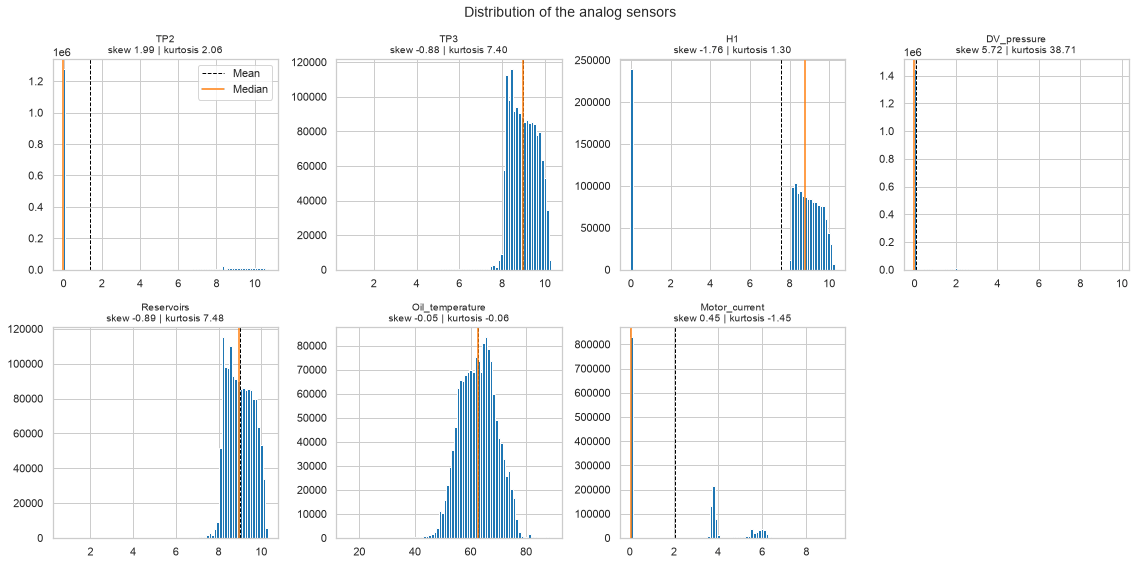

In [42]:
# Distribution of each analog sensor, with its skewness and kurtosis
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), analog_columns):
    ax.hist(df[col], bins=80, color='tab:blue')
    ax.axvline(df[col].mean(), color='black', linestyle='--', linewidth=1, label='Mean')
    ax.axvline(df[col].median(), color='tab:orange', linewidth=1.5, label='Median')
    ax.set_title(f"{col}\nskew {distribution_shape.loc[col, 'Skewness']:.2f} | "
                 f"kurtosis {distribution_shape.loc[col, 'Kurtosis']:.2f}", fontsize=10)
axes[0, 0].legend()
axes.flatten()[-1].axis('off')
plt.suptitle('Distribution of the analog sensors')
plt.tight_layout()
plt.show()

**Figure: distributions with skewness and kurtosis.**

- **TP2** and **H1** each have two groups of values (near 0 bar and 8–10 bar), one per operating state. Their mean lies between the groups, far from the median (TP2: mean 1.37 bar, median −0.01 bar), so the mean describes no real operating condition.
- **DV_pressure** is a single spike at 0 bar with a long tail to the right, which explains the very high kurtosis (38.7).
- **TP3** and **Reservoirs** are concentrated between 8 and 10 bar with a long tail of rare pressure drops to the left (kurtosis about 7.4).
- **Oil_temperature** is the only bell-shaped distribution; mean and median are almost equal (62.6 °C and 62.7 °C).
- **Motor_current** has three peaks (off, offloaded, loaded) and therefore a negative kurtosis.

**Finding:**

- **DV_pressure** is extremely right-skewed (skewness 5.7, kurtosis 38.7): it is almost always about 0 and only rises during air-dryer discharges and failures.
- **TP2** (1.99) is right-skewed and **H1** (−1.76) is left-skewed because both switch between two operating levels.
- **TP3** and **Reservoirs** have heavy tails (kurtosis about 7.4) caused by rare pressure drops.
- **Oil_temperature** is almost normally distributed (skewness −0.05, kurtosis −0.06).
- **Motor_current** has negative kurtosis (−1.45) because its values group into separate states (off, unloaded, loaded) rather than one peak.

Because several sensors are skewed or multi-modal, models should use scaling that is robust to this (for example median/IQR-based scaling) or work per operating state.

#### 3.4.8 Data Quality Report

Summary of the data quality check. The *level* column follows the lecture's monitoring and remediation levels (1 = automated monitoring and remediation, 2 = automated monitoring and manual remediation, 3 = manual monitoring and remediation).

| # | Dimension | Finding | Level | Action in Data Preparation |
|---|---|---|---|---|
| 1 | Conformity | `timestamp` stored as text; 8 digital signals stored as `float64` although they are nominal 0/1 values | 1 | Convert `timestamp` to datetime and the digital signals to `int8` (4.2) |
| 2 | Completeness | No NaN values, but only 82.4% of expected records: 351 gaps, 910 h missing, longest 48 h | 1 | Do not interpolate; mark continuous segments with `segment_id` (4.3) |
| 3 | Uniqueness | No duplicate rows or timestamps | 1 | None needed. Remove the running index `Unnamed: 0` (4.1) |
| 4 | Accuracy | No physically impossible values; negative pressures are the sensor zero offset; IQR "outliers" reflect operating states. **Frozen sensor periods: 3.4% of rows (about 141 h on 13 days) repeat identical analog values (logger fault)** | 2 | Keep outliers; robust scaling or per-state models. Flag frozen readings with `sensors_frozen` (4.3) and exclude them from training and evaluation |
| 5 | Timeliness | Feb–Aug 2020; sampling 10 s with 11.8% jitter (9–13 s); downsampled from 1 Hz | 2 | Build time windows on timestamps, not row counts |
| 6 | Consistency | Signals agree with the description (98–100%); TP3 = Reservoirs; F2 maintenance date lies before the failure; `Oil_level` and `Caudal_impulses` change only during frozen periods | 3 | Treat TP3/Reservoirs as redundant; do not use the F2 maintenance date |

**Notes for the next steps**

1. The data set is complete at the cell level but **not continuous in time**. Every time-based feature (rolling means, rates of change) must be calculated within a continuous segment (see the availability heatmap and segment lengths in 3.4.2).
2. Statistical outliers are **not removed**, because the abnormal behaviour of a failing compressor is exactly what the models need to detect (see the outliers per operating state in 3.4.4 and the sensor behaviour around Failure 2 in 3.5.5).
3. During the **frozen sensor periods** the analog values stop changing while the digital signals switch extremely often. These readings would look like anomalies to every model, so they are flagged (`sensors_frozen`, 4.3) and excluded. `Oil_level` and `Caudal_impulses` change *only* during these periods and are therefore not useful as features (see 3.4.6 and the activity of the digital signals in 3.5.6).
4. Several sensors are skewed or switch between operating levels, so robust scaling or a separate view per operating state (see `motor_state`, 4.4.1) is recommended (see the histograms in 3.4.7 and the distributions per operating state in 3.5.4).
5. The dataset has no row-level labels. The four reported failure windows are joined onto the readings in 4.5 and are used **only for evaluation**, never for training. The daily operating profile in 3.5.7 shows a few short abnormal days without a failure report.

### 3.5 Data Exploration and Visualization

#### 3.5.1 Outlier Detection

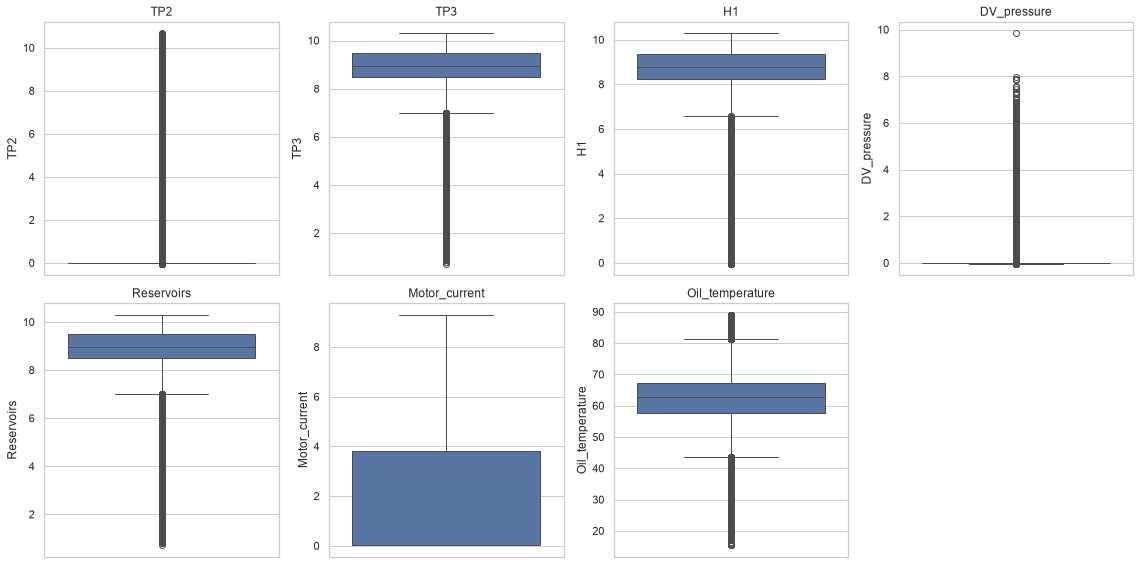

In [43]:
# Boxplot graph to examine each sensor separately
sensor_columns = [
    'TP2', 'TP3', 'H1', 'DV_pressure',
    'Reservoirs', 'Motor_current', 'Oil_temperature'
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, column in enumerate(sensor_columns):
    sns.boxplot(y=df[column], ax=axes[i])
    axes[i].set_title(column)

axes[-1].axis('off')

plt.tight_layout()
plt.show()

The boxplot analysis reveals numerous statistical outliers across several compressor sensor measurements, particularly TP2, TP3, H1, DV_pressure, and Reservoirs. However, these extreme values cannot automatically be classified as abnormal behavior because compressor measurements vary according to operational states, including startup, loaded, unloaded, and inactive conditions.

#### 3.5.2 Heatmap Correlation

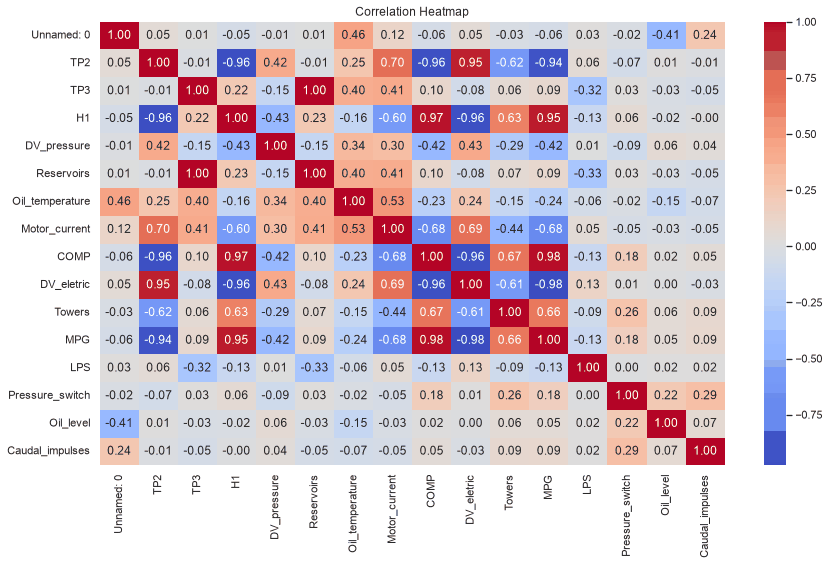

In [44]:
plt.figure(figsize=(14, 8))
corr = df.corr(numeric_only= True)
sns.heatmap(corr, annot= True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**Interpretation:**

- **TP3 and Reservoirs** are perfectly correlated (1.00): they measure the same pressure.
- **The control signals move together:** COMP and MPG (0.98) switch together, and DV_eletric is their opposite (−0.98 and −0.96). All three describe the same loaded / offloaded cycle.
- **TP2 and H1 follow that cycle too:** TP2 rises with DV_eletric (0.95) while H1 falls (TP2–H1 −0.96). When the compressor works under load, the compressor pressure is high and the separator pressure drops.
- **Oil_temperature** correlates moderately with Motor_current (0.53): the oil heats up when the motor works harder.
- **Caudal_impulses and Oil_level** are almost uncorrelated with every other signal (|r| ≤ 0.29). They change only during the frozen sensor periods (3.4.6), so they carry no information about the compressor.
- `Unnamed: 0` is only a running index; its correlations reflect the time order, not sensor behaviour. It is removed in 4.1.

Many signals are redundant, so a model can work with a reduced set. A linear correlation over the whole period does not show the failures, because they make up only 2% of the rows; the behaviour around failures is analysed in section 5.

#### 3.5.3 Motor current overview - Histogram Graph

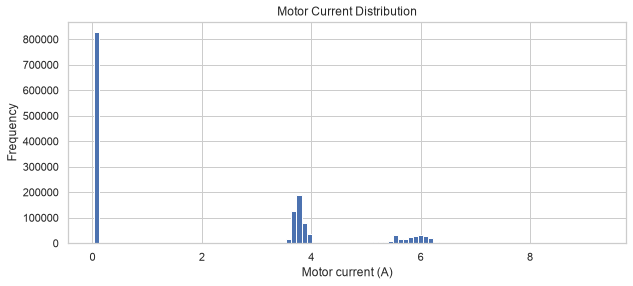

In [45]:
plt.figure(figsize=(10, 4))

plt.hist(df['Motor_current'].dropna(), bins=100)

plt.title('Motor Current Distribution')
plt.xlabel('Motor current (A)')
plt.ylabel('Frequency')
plt.show()

**Interpretation:** The motor current has three clearly separated groups, one per operating state:

- **About 0 A (54.6% of readings below 1 A):** the compressor is off.
- **About 3.6–3.9 A (30.1% between 1 and 5 A):** the compressor runs offloaded.
- **About 5.5 A and above (15.2% at 5 A or more):** the compressor runs under load.

The loaded level in the data is about 5.5–6 A, lower than the ~7 A given in the dataset description. The thresholds for the `motor_state` column (4.4.1) are therefore based on the observed distribution (1 A and 5 A). The ~9 A start-up peak is almost invisible because it lasts only a few seconds and is mostly lost at 10-second sampling.

#### 3.5.4 Sensor distributions per operating state

The skewness and kurtosis in 3.4.7 are calculated over all readings, which mix three operating states. Here the distributions are shown separately for each state.

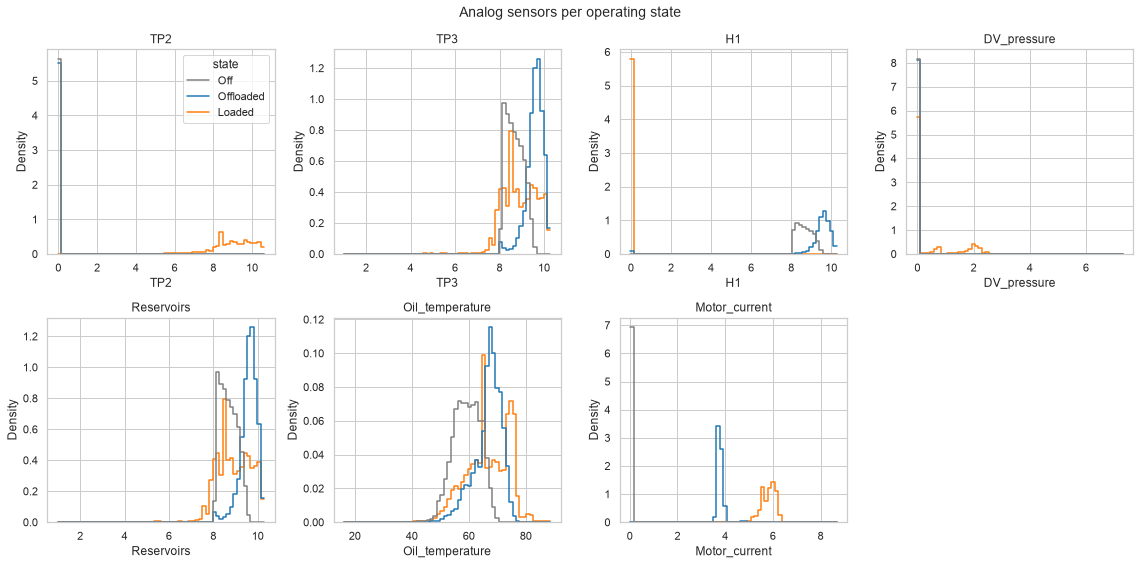

state,All data,Off,Offloaded,Loaded
TP2,1.99,132.65,9.11,-1.60
TP3,-0.88,-0.38,-5.98,-1.02
H1,-1.76,-8.33,-6.32,19.56
DV_pressure,5.72,21.14,20.04,1.60
Reservoirs,-0.89,-0.38,-6.01,-1.03
Oil_temperature,-0.05,-0.26,-1.23,-0.52
Motor_current,0.45,55.65,3.07,-0.26


In [46]:
# The same distributions split by operating state (each state scaled to its own area)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), analog_columns):
    sns.histplot(data=sample, x=col, hue='state', palette=state_colors, bins=60, stat='density',
                 common_norm=False, element='step', fill=False, ax=ax, legend=(col == analog_columns[0]))
    ax.set_title(col)
axes.flatten()[-1].axis('off')
plt.suptitle('Analog sensors per operating state')
plt.tight_layout()
plt.show()

# Skewness overall and within each operating state
skew_by_state = df[analog_columns].groupby(operating_state, observed=True).skew().T
skew_by_state.insert(0, 'All data', df[analog_columns].skew())
display(skew_by_state.round(2))

**Figure: distributions per operating state.** Within each operating state every sensor has a single, separate peak; for example, Motor_current lies at about 0 A, 3.8 A and 5.8 A. The multiple peaks in the overall histograms therefore come from mixing the states.

However, the skewness **within** a state is not smaller. It is often much larger (TP2 when the compressor is off: 132.7; Motor_current when off: 55.7). Within one state the values are almost constant, so the few readings that deviate, mostly during switching, dominate the statistic.

**Consequence for Data Preparation and Modeling:**

- Comparing readings **within an operating state** removes the mixing of levels (the `motor_state` column, 4.4.1).
- The remaining heavy tails call for **robust scaling** (median and IQR) instead of mean and standard deviation.
- A log transformation, as used for skewed sales data in the lecture example, is not possible here because the pressures contain zero and negative values.

#### 3.5.5 Sensor behaviour around a failure

What does an air leak look like in the sensor data? The first chart gives an overview of the three key sensors for the two days before and during Failure 2 (this chart is also used in the presentation). The second chart marks the readings that lie outside the normal range of their operating state (see 3.4.4).

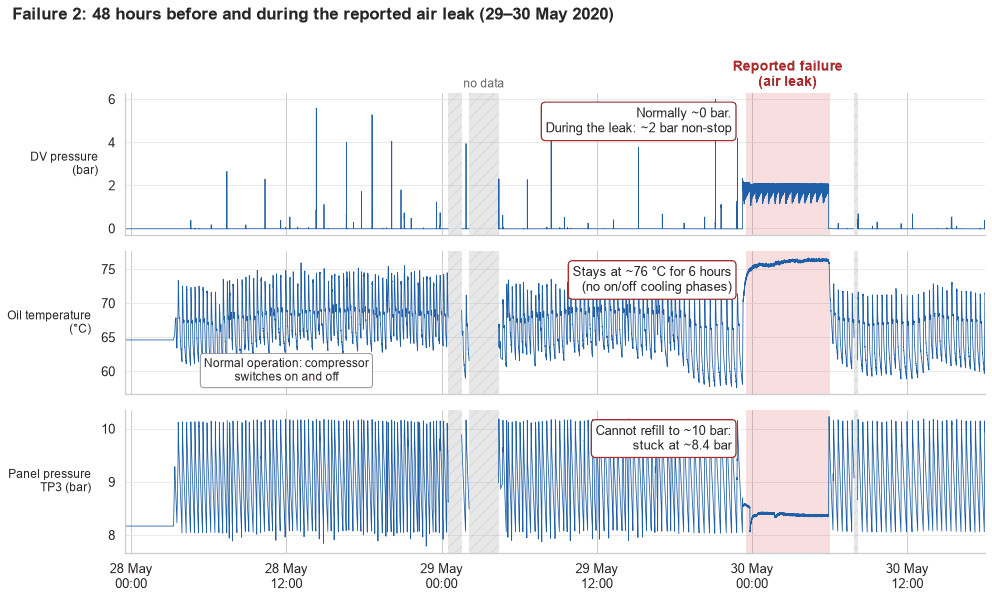

,Median 48 h before,Median during failure
DV_pressure,-0.02,2.05
Oil_temperature,66.58,76.08
TP3,8.93,8.38


In [47]:
# Overview of Failure 2: three key sensors, gaps shown as 'no data', plain-language labels.
# The figure is also saved to figures/ for the presentation.
from pathlib import Path
import matplotlib.dates as mdates

f2_start, f2_end = reported_failures.loc[reported_failures['failure_id'] == 2, ['start', 'end']].iloc[0]
view_start, view_end = f2_start - pd.Timedelta(hours=48), f2_end + pd.Timedelta(hours=12)
panels = {'DV_pressure': 'DV pressure\n(bar)',
          'Oil_temperature': 'Oil temperature\n(°C)',
          'TP3': 'Panel pressure\nTP3 (bar)'}

in_view = parsed_timestamps.between(view_start, view_end)
f2 = df.loc[in_view, list(panels)].assign(timestamp=parsed_timestamps[in_view]).sort_values('timestamp')

# Pauses longer than 10 minutes are shown as 'no data' instead of a line bridging the gap
gap_after = f2['timestamp'].diff().shift(-1) > pd.Timedelta(minutes=10)
f2_gaps = list(zip(f2.loc[gap_after, 'timestamp'], f2['timestamp'].shift(-1)[gap_after]))
breaks = pd.DataFrame({'timestamp': f2.loc[gap_after, 'timestamp'] + pd.Timedelta(seconds=1)})
f2 = pd.concat([f2, breaks]).sort_values('timestamp')

with plt.rc_context({'font.size': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13}):
    fig, axes = plt.subplots(len(panels), 1, figsize=(14, 8.5), sharex=True)
    for ax, (col, label) in zip(axes, panels.items()):
        ax.plot(f2['timestamp'], f2[col], linewidth=0.8, color='#1f5fa8')
        ax.axvspan(f2_start, f2_end, color='#d62728', alpha=0.15, linewidth=0)
        for gap_start, gap_end in f2_gaps:
            ax.axvspan(gap_start, gap_end, color='#bbbbbb', alpha=0.35, linewidth=0, hatch='//')
        ax.set_ylabel(label, rotation=0, ha='right', va='center', labelpad=10)
        ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
        ax.spines[['top', 'right']].set_visible(False)

    axes[0].annotate('Reported failure\n(air leak)', xy=(f2_start + (f2_end - f2_start) / 2, 1.02),
                     xycoords=('data', 'axes fraction'), ha='center', va='bottom', color='#b22222', fontweight='bold')
    longest_gap = max(f2_gaps, key=lambda g: g[1] - g[0])
    axes[0].annotate('no data', xy=(longest_gap[0] + (longest_gap[1] - longest_gap[0]) / 2, 1.02),
                     xycoords=('data', 'axes fraction'), ha='center', va='bottom', color='#666666', fontsize=12)

    # Explanatory labels next to the failure window
    label_box = dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='#b22222', linewidth=1.2)
    labels = ['Normally ~0 bar.\nDuring the leak: ~2 bar non-stop',
              'Stays at ~76 °C for 6 hours\n(no on/off cooling phases)',
              'Cannot refill to ~10 bar:\nstuck at ~8.4 bar']
    for ax, text in zip(axes, labels):
        ax.annotate(text, xy=(f2_start, 0.80), xycoords=('data', 'axes fraction'), xytext=(-14, 0),
                    textcoords='offset points', ha='right', va='center', fontsize=12.5, bbox=label_box)
    axes[1].annotate('Normal operation: compressor\nswitches on and off', xy=(pd.Timestamp('2020-05-28 12:00'), 0.07),
                     xycoords=('data', 'axes fraction'), ha='center', va='bottom', fontsize=12,
                     bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#999999'))

    axes[-1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))
    axes[-1].set_xlim(view_start, view_end)
    fig.suptitle('Failure 2: 48 hours before and during the reported air leak (29–30 May 2020)',
                 fontsize=17, fontweight='bold', x=0.02, ha='left')
    fig.tight_layout(rect=(0, 0, 1, 0.97))

    figures_dir = Path('figures')
    figures_dir.mkdir(exist_ok=True)
    fig.savefig(figures_dir / 'failure2_air_leak_annotated.png', dpi=200, facecolor='white')
    plt.show()

inside = f2['timestamp'].between(f2_start, f2_end)
display(pd.DataFrame({'Median 48 h before': f2.loc[f2['timestamp'] < f2_start, list(panels)].median(),
                      'Median during failure': f2.loc[inside, list(panels)].median()}).round(2))

**Figure: Failure 2 overview.**

- **Before the failure** the compressor switches on and off regularly: the panel pressure rises to about 10 bar and drops to about 8 bar, and the oil temperature follows each cycle. Grey hatched areas are periods without data.
- **During the reported window** (29 May 23:30 – 30 May 06:00) the compressor no longer switches off. DV pressure stays at about 2 bar, the oil temperature stays at about 76 °C, and the panel pressure stays at about 8.4 bar: air escapes as fast as it is produced, so the reservoirs cannot be refilled.
- **After the window** normal cycling resumes.
- **In the 48 hours before** the failure, no change is visible in these sensors. Detecting the leak while it happens is easy; warning before it is the challenge addressed in the Modeling phase.

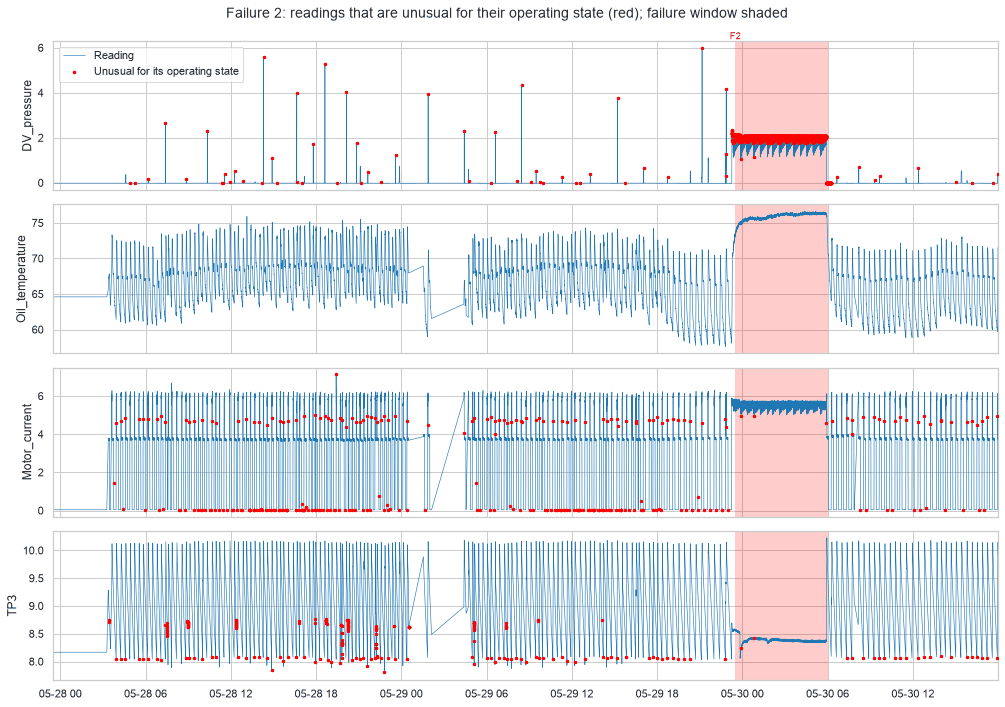

,Outliers in normal operation (%),Outliers in failure windows (%)
TP2,5.8,4.1
TP3,1.4,1.5
H1,2.4,0.8
DV_pressure,3.5,80.5
Reservoirs,1.4,1.5
Oil_temperature,1.4,0.1
Motor_current,5.4,0.6


In [48]:
# Readings that are unusual for their operating state, around Failure 2
failure = reported_failures.loc[reported_failures['failure_id'] == 2].iloc[0]
window = parsed_timestamps.between(failure['start'] - pd.Timedelta(hours=48),
                                   failure['end'] + pd.Timedelta(hours=12))
plot_sensors = ['DV_pressure', 'Oil_temperature', 'Motor_current', 'TP3']

fig, axes = plt.subplots(len(plot_sensors), 1, figsize=(14, 10), sharex=True)
for ax, col in zip(axes, plot_sensors):
    times, values, unusual = parsed_timestamps[window], df.loc[window, col], state_outliers.loc[window, col]
    ax.plot(times, values, linewidth=0.6, color='tab:blue', label='Reading')
    ax.scatter(times[unusual], values[unusual], s=6, color='red', zorder=3, label='Unusual for its operating state')
    shade_failures(ax, labels=(col == plot_sensors[0]))
    ax.set_ylabel(col)
axes[0].legend(loc='upper left')
axes[0].set_xlim(times.min(), times.max())
plt.suptitle('Failure 2: readings that are unusual for their operating state (red); failure window shaded')
plt.tight_layout()
plt.show()

# Where do the state-based outliers occur?
in_failure = pd.Series(False, index=df.index)
for _, f in reported_failures.iterrows():
    in_failure |= parsed_timestamps.between(f['start'], f['end'])
display(pd.DataFrame({
    'Outliers in normal operation (%)': 100 * state_outliers[~in_failure].mean(),
    'Outliers in failure windows (%)': 100 * state_outliers[in_failure].mean(),
}).round(1))

**Figure: unusual readings around Failure 2.** Red points are readings outside the normal range *of their operating state*.

- **DV_pressure** is flagged almost continuously during the failure window: **80.5%** of readings in the failure windows are outliers, compared with 3.5% in normal operation. It is the clearest single-reading signal of an air leak.
- **Oil_temperature** rises to about 76 °C during the failure, but **none** of these readings is flagged: each value on its own is still normal for loaded operation. The anomaly is that the temperature *stays* high for hours.
- The red points on **Motor_current** and **TP3** outside the failure are mostly readings taken while the compressor switches between states.
- Before the failure (28–29 May) the pattern of red points does not change noticeably.

**Conclusion for anomaly detection:** checking single readings against fixed limits is not enough. A model needs time context, such as how long the compressor has been loaded or rolling averages, to recognise sustained changes like the oil temperature.

#### 3.5.6 Activity of the digital signals

How often each digital signal switches between 0 and 1, and on which days.

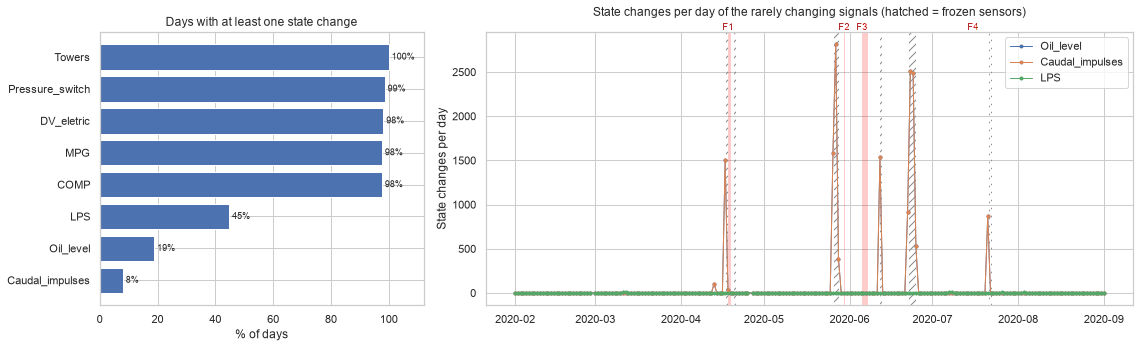

,Days without any change,Share of changes on the 10 busiest days (%)
Oil_level,172,98.8
Caudal_impulses,195,99.1
LPS,117,26.0


Busiest days for Oil_level:


,State changes
timestamp,
2020-05-27,2814
2020-06-23,2515
2020-06-24,2488
2020-05-26,1586
2020-06-12,1534
2020-04-17,1508


In [49]:
# How often does each digital signal change its state, and when?
state_changes = df[digital_columns].diff().abs().gt(0)
changes_per_day = state_changes.groupby(parsed_timestamps.dt.floor('D')).sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 2]})

# Left: on how many days does the signal change at least once?
active_days = (100 * (changes_per_day > 0).mean()).sort_values()
axes[0].barh(active_days.index, active_days)
for y, value in enumerate(active_days):
    axes[0].text(value + 1, y, f'{value:.0f}%', va='center', fontsize=9)
axes[0].set_xlim(0, 112)
axes[0].set_title('Days with at least one state change')
axes[0].set_xlabel('% of days')

# Right: when do the rarely changing signals change?
for col in ['Oil_level', 'Caudal_impulses', 'LPS']:
    axes[1].plot(changes_per_day.index, changes_per_day[col], marker='.', linewidth=1, label=col)
shade_failures(axes[1])
shade_frozen(axes[1])
axes[1].set_title('State changes per day of the rarely changing signals (hatched = frozen sensors)', pad=16)
axes[1].set_ylabel('State changes per day')
axes[1].legend()
plt.tight_layout()
plt.show()

rare = ['Oil_level', 'Caudal_impulses', 'LPS']
display(pd.DataFrame({
    'Days without any change': (changes_per_day[rare] == 0).sum(),
    'Share of changes on the 10 busiest days (%)': (100 * changes_per_day[rare].apply(lambda s: s.nlargest(10).sum() / s.sum())).round(1),
}))
print('Busiest days for Oil_level:')
display(changes_per_day['Oil_level'].nlargest(6).to_frame('State changes'))

**Figure: state changes of the digital signals.**

- `Towers`, `Pressure_switch`, `COMP`, `MPG` and `DV_eletric` change on 98–100% of days; they follow the normal compressor cycle.
- `LPS` (pressure below 7 bar) changes on 45% of days, about once or twice a day.
- `Oil_level` changes on only 19% of days and `Caudal_impulses` on 8%. Both stay constant for weeks, and **99% of their changes happen on just 10 days**, with up to 2,814 changes per day.

These days are exactly the **frozen sensor periods** (hatched; see 3.4.6): 17 April, 20–21 April, 26–28 May, 12 June, 22–25 June and 21–22 July. Outside these periods `Oil_level` and `Caudal_impulses` never change. Their activity is therefore a symptom of the logger fault, not of the compressor, even though some of these days lie shortly before F1 and F2. The two signals are not used as model features.

#### 3.5.7 Abnormal behaviour over time

An air leak forces the compressor to refill the reservoirs more often and to run longer under load. The daily **duty cycle** (share of running time spent under load) and the number of **load cycles** per day therefore show abnormal behaviour over the whole period, and whether it matches the reported failures.

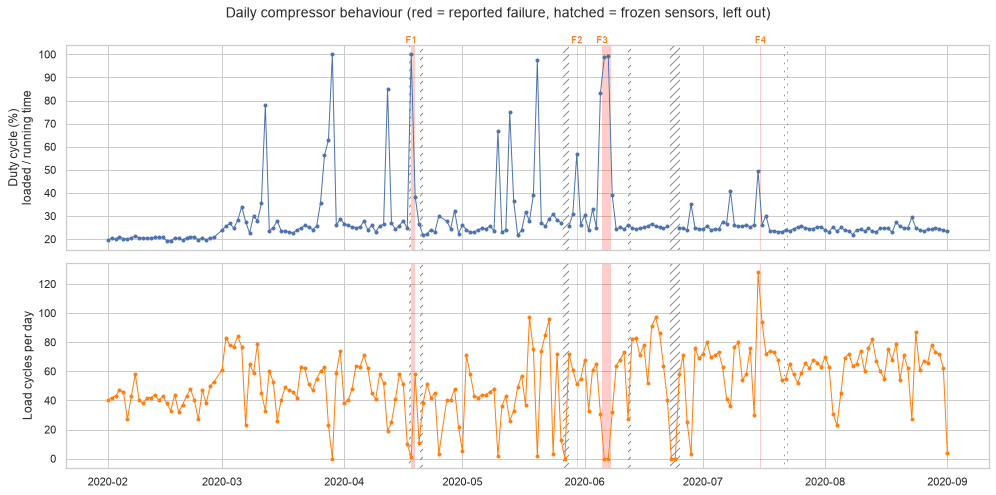

Typical day (10th-90th percentile): duty cycle 25%, 60 load cycles

Days with a duty cycle above 45% or more than 300 load cycles:


,duty_cycle_pct,load_starts
timestamp,,
2020-03-12,78.1,33
2020-03-27,56.3,63
2020-03-28,62.8,23
2020-03-29,100.0,0
2020-04-12,84.9,19
2020-04-18,100.0,1
2020-05-10,66.8,2
2020-05-13,74.9,26
2020-05-20,97.4,2


In [50]:
# Daily operating profile of the compressor
# Frozen readings (3.4.6) are left out: their constant motor current and switching digital signals are a logger fault
valid = ~frozen_rows
daily_profile = pd.DataFrame({
    'running': (operating_state != 'Off') & valid,
    'loaded': (operating_state == 'Loaded') & valid,
    'load_starts': (df['DV_eletric'].diff() == 1) & valid,
}).groupby(parsed_timestamps.dt.floor('D')).sum()
daily_profile['duty_cycle_pct'] = 100 * daily_profile['loaded'] / daily_profile['running'].replace(0, np.nan)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(daily_profile.index, daily_profile['duty_cycle_pct'], marker='.', linewidth=1)
axes[0].set_ylabel('Duty cycle (%)\nloaded / running time')
axes[1].plot(daily_profile.index, daily_profile['load_starts'], marker='.', linewidth=1, color='tab:orange')
axes[1].set_ylabel('Load cycles per day')
for ax in axes:
    shade_failures(ax, labels=(ax is axes[0]))
    shade_frozen(ax)
plt.suptitle('Daily compressor behaviour (red = reported failure, hatched = frozen sensors, left out)')
plt.tight_layout()
plt.show()

normal_days = daily_profile['duty_cycle_pct'].between(*daily_profile['duty_cycle_pct'].quantile([0.1, 0.9]))
print(f"Typical day (10th-90th percentile): duty cycle {daily_profile.loc[normal_days, 'duty_cycle_pct'].median():.0f}%, "
      f"{daily_profile.loc[normal_days, 'load_starts'].median():.0f} load cycles")
print('\nDays with a duty cycle above 45% or more than 300 load cycles:')
display(daily_profile.loc[(daily_profile['duty_cycle_pct'] > 45) | (daily_profile['load_starts'] > 300),
                          ['duty_cycle_pct', 'load_starts']].round(1))

**Figure: daily compressor behaviour.** On a typical day the compressor spends about **25%** of its running time under load and starts about **60** load cycles. Frozen sensor readings (hatched, 3.4.6) are left out.

- **Reported failures:** F1 (18 April, 100% loaded) and F3 (5–7 June, 83–99% loaded, almost no load cycles because the compressor never switches off) stand out clearly. F2 and F4 last only 4.5–6.5 hours, so their daily values are less extreme (57% and 50%). On the F4 day the compressor started 128 load cycles, the highest value of the whole period.
- **Abnormal days without a report:** 12 March (78%), 27–29 March (56–100%), 12 April (85%, six days before F1) and 10, 13 and 20 May (67–97%). On these days the compressor ran under load for long periods, as during a failure. They may be unreported leaks, unusual operation, or early stages of the reported failures; the data alone cannot tell.
- Before the frozen readings were removed, 22–25 June looked like the strongest abnormal period (100% loaded, about 1,250 load cycles per day). This was the logger fault, not the compressor.

**Consequence for the evaluation:** alarms on these eight days will be reported separately instead of being counted blindly as false alarms (see Risks and contingencies, 2.2.4).

## 4. Data Preparation and Exploratory Data Analysis

### 4.1 Select data: Removing unnecessary columns

In [51]:
# Remove the extra CSV index column
df = df.loc[:, ~df.columns.str.startswith('Unnamed:')]

### 4.2 Format data: Converting the timestamp and the digital signals

In [52]:
# timestamp is read from the CSV as text: convert it to datetime so it can be used for time calculations
df['timestamp'] = pd.to_datetime(df['timestamp'])

# The digital signals only take the values 0 and 1 (see Conformity), so store them as integers
df[digital_columns] = df[digital_columns].astype('int8')

df.dtypes

timestamp          datetime64[us]
TP2                       float64
TP3                       float64
H1                        float64
DV_pressure               float64
Reservoirs                float64
Oil_temperature           float64
Motor_current             float64
COMP                         int8
DV_eletric                   int8
Towers                       int8
MPG                          int8
LPS                          int8
Pressure_switch              int8
Oil_level                    int8
Caudal_impulses              int8
dtype: object

### 4.3 Clean data: Marking continuous recording segments and frozen sensor periods

The gaps found in the Completeness check are **not filled**. Interpolating across hours without data would invent sensor readings. Instead, every row gets a `segment_id` that changes after each pause longer than one minute. Later rolling-window features can then be calculated within one continuous segment, never across a gap.

The **frozen sensor periods** found in 3.4.6 are not deleted either, so that the time line stays complete. They are flagged with `sensors_frozen = 1` and left out of training and evaluation.

In [53]:
df = df.copy().sort_values('timestamp').reset_index(drop=True)

new_segment = df['timestamp'].diff() > pd.Timedelta(minutes=1)
df['segment_id'] = new_segment.cumsum()

segment_hours = df.groupby('segment_id')['timestamp'].agg(lambda s: (s.max() - s.min()).total_seconds() / 3600)
print('Continuous segments:', df['segment_id'].nunique())
display(segment_hours.describe().round(2).to_frame('Segment length (h)'))

# Flag frozen sensor readings (same rule as in 3.4.6)
analog_unchanged = df[analog_columns].diff().abs().sum(axis=1).eq(0)
run_id = (~analog_unchanged).cumsum()
df['sensors_frozen'] = (analog_unchanged & (analog_unchanged.groupby(run_id).transform('size') >= 30)).astype('int8')
print(f"Frozen readings flagged: {df['sensors_frozen'].sum():,} ({100 * df['sensors_frozen'].mean():.1f}% of rows)")

Continuous segments: 332


,Segment length (h)
count,332.00
mean,12.67
std,15.98
min,0.08
25%,0.41
50%,6.44
75%,19.90
max,100.78


Frozen readings flagged: 50,855 (3.4% of rows)


In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 18 columns):
 #   Column           Non-Null Count    Dtype         
---  ------           --------------    -----         
 0   timestamp        1516948 non-null  datetime64[us]
 1   TP2              1516948 non-null  float64       
 2   TP3              1516948 non-null  float64       
 3   H1               1516948 non-null  float64       
 4   DV_pressure      1516948 non-null  float64       
 5   Reservoirs       1516948 non-null  float64       
 6   Oil_temperature  1516948 non-null  float64       
 7   Motor_current    1516948 non-null  float64       
 8   COMP             1516948 non-null  int8          
 9   DV_eletric       1516948 non-null  int8          
 10  Towers           1516948 non-null  int8          
 11  MPG              1516948 non-null  int8          
 12  LPS              1516948 non-null  int8          
 13  Pressure_switch  1516948 non-null  int8          
 14  Oil_level    

In [55]:
df[["segment_id", "sensors_frozen"]].isnull().sum()

segment_id        0
sensors_frozen    0
dtype: int64

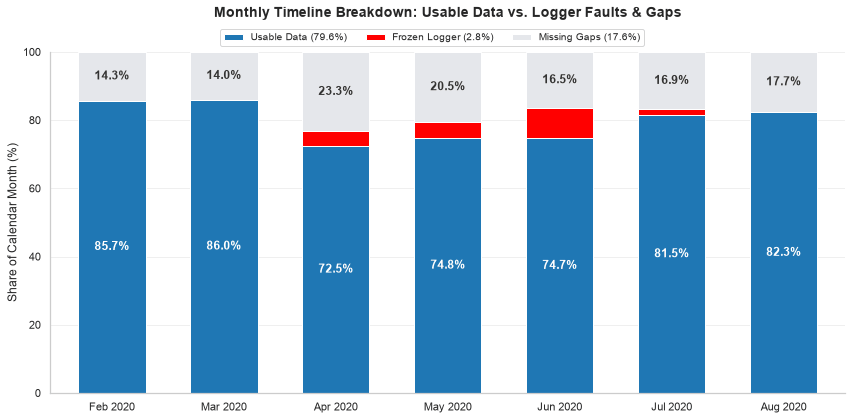

In [56]:
import matplotlib.pyplot as plt
import pandas as pd

ts = pd.to_datetime(df['timestamp'])
frozen = df['sensors_frozen'].astype(bool) if 'sensors_frozen' in df.columns else frozen_rows

months = pd.period_range('2020-02', '2020-08', freq='M')
total_h = pd.Series([m.days_in_month * 24 for m in months], index=months)

m_group = ts.dt.to_period('M')
usable_h = ((~frozen).groupby(m_group).sum() * 10 / 3600).reindex(months, fill_value=0)
frozen_h = (frozen.groupby(m_group).sum() * 10 / 3600).reindex(months, fill_value=0)
gap_h = (total_h - usable_h - frozen_h).clip(lower=0)

tot_all = total_h.sum()
u_pct, f_pct, g_pct = usable_h.sum()/tot_all*100, frozen_h.sum()/tot_all*100, gap_h.sum()/tot_all*100

monthly_pct = pd.DataFrame({
    f'Usable Data ({u_pct:.1f}%)': usable_h / total_h * 100,
    f'Frozen Logger ({f_pct:.1f}%)': frozen_h / total_h * 100,
    f'Missing Gaps ({g_pct:.1f}%)': gap_h / total_h * 100
}, index=months.strftime('%b %Y'))

fig, ax = plt.subplots(figsize=(12, 6))
monthly_pct.plot(kind='bar', stacked=True, ax=ax, width=0.6,
                 color=['#1f77b4', 'red', '#e5e7eb'], edgecolor='white')

ax.bar_label(ax.containers[0], label_type='center', fmt='%.1f%%', color='white', fontweight='bold', fontsize=12)
ax.bar_label(ax.containers[2], label_type='center', fmt='%.1f%%', color='#333333', fontweight='bold', fontsize=12)

ax.set_title('Monthly Timeline Breakdown: Usable Data vs. Logger Faults & Gaps', fontsize=14, fontweight='bold', pad=35)
ax.set_ylabel('Share of Calendar Month (%)')
ax.set_xlabel('')
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper center', bbox_to_anchor=(0.48, 1.08), ncol=3, fontsize=9.5)
plt.tight_layout()
plt.show()

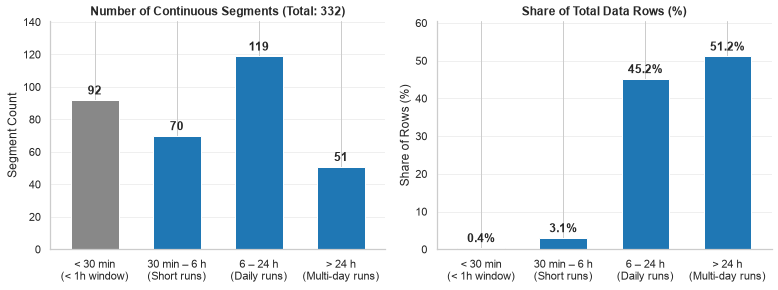

In [57]:
import matplotlib.pyplot as plt
import pandas as pd

ts = pd.to_datetime(df['timestamp'])
if 'segment_id' not in df.columns:
    df['segment_id'] = (ts.diff() > pd.Timedelta(minutes=1)).cumsum()

seg_stats = df.groupby('segment_id').agg(
    rows=('timestamp', 'size'),
    hours=('timestamp', lambda s: (pd.to_datetime(s).max() - pd.to_datetime(s).min()).total_seconds() / 3600)
)

bins = [-0.01, 0.5, 6, 24, 200]
labels = ['< 30 min\n(< 1h window)', '30 min – 6 h\n(Short runs)', '6 – 24 h\n(Daily runs)', '> 24 h\n(Multi-day runs)']
seg_stats['bucket'] = pd.cut(seg_stats['hours'], bins=bins, labels=labels)

summary = pd.DataFrame({
    'Segments': seg_stats.groupby('bucket', observed=False).size(),
    'Share of Rows (%)': seg_stats.groupby('bucket', observed=False)['rows'].sum() / len(df) * 100
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
colors = ['#888888', '#1f77b4', '#1f77b4', '#1f77b4']

summary['Segments'].plot(kind='bar', ax=ax1, color=colors, width=0.58)
ax1.bar_label(ax1.containers[0], padding=3, fontweight='bold')
ax1.set_title('Number of Continuous Segments (Total: 332)', fontweight='bold')
ax1.set_ylabel('Segment Count')
ax1.set_ylim(0, summary['Segments'].max() * 1.18)

summary['Share of Rows (%)'].plot(kind='bar', ax=ax2, color=colors, width=0.58)
ax2.bar_label(ax2.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')
ax2.set_title('Share of Total Data Rows (%)', fontweight='bold')
ax2.set_ylabel('Share of Rows (%)')
ax2.set_ylim(0, summary['Share of Rows (%)'].max() * 1.18)

for ax in (ax1, ax2):
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### 4.4 Construct data

#### 4.4.1 Creating a motor state column

In [58]:
current = df['Motor_current']

df['motor_state'] = np.select(
    [
        current.between(0, 1, inclusive='left'),
        current.between(1, 5, inclusive='left'),
        current.ge(5)
    ],
    [
        'Off / near zero',
        'Possible unloaded',
        'Possible loaded / startup'
    ],
    default='Unknown'
)

display(df['motor_state'].value_counts())

motor_state
Off / near zero              829000
Possible unloaded            457356
Possible loaded / startup    230592
Name: count, dtype: int64

#### 4.4.2 Creating the Air-leak failures dataframe

Since the dataset is unlabeled at the sensor-row level but accompanied by external failure-event ground truth provided in the UCI repository, the creation of a dataframe is needed. This dataframe will be useful later for comparing the anomaly alerts generates by our machine learning models against the actual failure periods.
Failure reports: Records of actual air leaks reported by the maintenance team, including their start and end times.

In [59]:
# Creating the dataframe: failure events documented in the MetroPT3 dataset
failure_events = pd.DataFrame({
    'failure_id': [1, 2, 3, 4],
    'start_time': [
        '2020-04-18 00:00:00',
        '2020-05-29 23:30:00',
        '2020-06-05 10:00:00',
        '2020-07-15 14:30:00'
    ],
    'end_time': [
        '2020-04-18 23:59:00',
        '2020-05-30 06:00:00',
        '2020-06-07 14:30:00',
        '2020-07-15 19:00:00'
    ],
    'failure_type': ['Air leak'] * 4,
    'severity': ['High stress'] * 4
})

In [60]:
print(failure_events)

   failure_id           start_time             end_time failure_type  \
0           1  2020-04-18 00:00:00  2020-04-18 23:59:00     Air leak   
1           2  2020-05-29 23:30:00  2020-05-30 06:00:00     Air leak   
2           3  2020-06-05 10:00:00  2020-06-07 14:30:00     Air leak   
3           4  2020-07-15 14:30:00  2020-07-15 19:00:00     Air leak   

      severity  
0  High stress  
1  High stress  
2  High stress  
3  High stress  


In [61]:
failure_events['start_time'] = pd.to_datetime(failure_events['start_time'])
failure_events['end_time'] = pd.to_datetime(failure_events['end_time'])

failure_events.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   failure_id    4 non-null      int64         
 1   start_time    4 non-null      datetime64[us]
 2   end_time      4 non-null      datetime64[us]
 3   failure_type  4 non-null      str           
 4   severity      4 non-null      str           
dtypes: datetime64[us](2), int64(1), str(2)
memory usage: 368.0 bytes


In [62]:
#Calculate failure duration

failure_events['duration_hours'] = (
    failure_events['end_time'] - failure_events['start_time']
).dt.total_seconds() / 3600

display(failure_events)


,failure_id,start_time,end_time,failure_type,severity,duration_hours
0,1,2020-04-18 00:00:00,2020-04-18 23:59:00,Air leak,High stress,23.983333
1,2,2020-05-29 23:30:00,2020-05-30 06:00:00,Air leak,High stress,6.500000
2,3,2020-06-05 10:00:00,2020-06-07 14:30:00,Air leak,High stress,52.500000
3,4,2020-07-15 14:30:00,2020-07-15 19:00:00,Air leak,High stress,4.500000


In [63]:
#Printing the sensor data period & failures period
print("Sensor data period:")
print(df['timestamp'].min(), "to", df['timestamp'].max())

print("\nFailure event period:")
print(
    failure_events['start_time'].min(),
    "to",
    failure_events['end_time'].max()
)


Sensor data period:
2020-02-01 00:00:00 to 2020-09-01 03:59:50

Failure event period:
2020-04-18 00:00:00 to 2020-07-15 19:00:00


### 4.5 Integrate data: Adding failure labels to the sensor readings

The failure reports are joined onto every sensor reading:

- `is_failure`: 1 if the reading falls inside a reported failure window, otherwise 0
- `failure_window_id`: number of that failure window (0 = no failure)
- `hours_to_next_failure`: time until the next failure starts (0 inside a window, empty after the last failure)

These columns are used **only for evaluation**. The anomaly-detection models must not see them during training.

In [64]:
df['is_failure'] = 0
df['failure_window_id'] = 0
for _, event in failure_events.iterrows():
    in_window = df['timestamp'].between(event['start_time'], event['end_time'])
    df.loc[in_window, 'is_failure'] = 1
    df.loc[in_window, 'failure_window_id'] = event['failure_id']

# Time until the next failure start
starts = failure_events[['start_time']].sort_values('start_time')
starts['start_time'] = starts['start_time'].astype(df['timestamp'].dtype)
next_start = pd.merge_asof(df[['timestamp']], starts, left_on='timestamp',
                           right_on='start_time', direction='forward')['start_time']
df['hours_to_next_failure'] = (next_start - df['timestamp']).dt.total_seconds() / 3600
df.loc[df['is_failure'] == 1, 'hours_to_next_failure'] = 0

display(df['is_failure'].value_counts().rename('rows').to_frame())
display(df.groupby('failure_window_id')['timestamp'].agg(['count', 'min', 'max']))

,rows
is_failure,
0,1486994
1,29954


,count,min,max
failure_window_id,,,
0,1486994,2020-02-01 00:00:00,2020-09-01 03:59:50
1,8657,2020-04-18 00:00:01,2020-04-18 23:58:56
2,2360,2020-05-29 23:30:08,2020-05-30 05:59:54
3,17315,2020-06-05 10:00:04,2020-06-07 14:19:39
4,1622,2020-07-15 14:30:00,2020-07-15 19:00:00


### 4.6 Summary of the model-ready data

Descriptive overview of the prepared dataset (lecture slides 68–70).

#### 4.6.1 Data overview

In [65]:
print('Shape:', df.shape)
df.info()

Shape: (1516948, 22)
<class 'pandas.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   timestamp              1516948 non-null  datetime64[us]
 1   TP2                    1516948 non-null  float64       
 2   TP3                    1516948 non-null  float64       
 3   H1                     1516948 non-null  float64       
 4   DV_pressure            1516948 non-null  float64       
 5   Reservoirs             1516948 non-null  float64       
 6   Oil_temperature        1516948 non-null  float64       
 7   Motor_current          1516948 non-null  float64       
 8   COMP                   1516948 non-null  int8          
 9   DV_eletric             1516948 non-null  int8          
 10  Towers                 1516948 non-null  int8          
 11  MPG                    1516948 non-null  int8          
 12  LPS               

In [66]:
display(df[analog_columns].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
TP2,1516948.0,1.37,3.25,-0.03,-0.01,-0.01,-0.01,10.68
TP3,1516948.0,8.98,0.64,0.73,8.49,8.96,9.49,10.30
H1,1516948.0,7.57,3.33,-0.04,8.25,8.78,9.37,10.29
DV_pressure,1516948.0,0.06,0.38,-0.03,-0.02,-0.02,-0.02,9.84
Reservoirs,1516948.0,8.99,0.64,0.71,8.49,8.96,9.49,10.30
Oil_temperature,1516948.0,62.64,6.52,15.40,57.78,62.70,67.25,89.05
Motor_current,1516948.0,2.05,2.30,0.02,0.04,0.04,3.81,9.30


#### 4.6.2 Data set description of the prepared data

In [67]:
# Data set description of the prepared data (same structure as the table in 3.3.1)
new_column_info = {
    'segment_id': ('Nominal', 'Number of the continuous recording segment; changes after every gap longer than 1 minute'),
    'sensors_frozen': ('Nominal', '1 = all analog sensors frozen at one value (logger fault, 3.4.6); excluded from training and evaluation'),
    'motor_state': ('Ordinal', 'Operating state derived from Motor_current: off < unloaded < loaded / startup'),
    'is_failure': ('Nominal', '1 = reading inside a reported failure window; evaluation only, not used for training'),
    'failure_window_id': ('Nominal', 'Number of the failure window (0 = no failure); evaluation only'),
    'hours_to_next_failure': ('Ratio', 'Hours until the next reported failure starts; empty after the last failure'),
}
operators_by_scale = {
    'Nominal': '=, !=',
    'Ordinal': '=, !=, <, <=, >, >=',
    'Interval': '=, !=, <, <=, >, >=, +, -',
    'Ratio': '=, !=, <, <=, >, >=, +, -, *, /',
}

rows = []
for col in df.columns:
    if col in new_column_info:
        scale, note = new_column_info[col]
    elif col in interval_columns:
        scale, note = 'Interval', descriptions[col]
    elif col in digital_columns:
        scale, note = 'Nominal', descriptions[col]
    else:
        scale, note = 'Ratio', descriptions[col]

    values = df[col]
    if pd.api.types.is_datetime64_any_dtype(values):
        value_range = f'{values.min()} to {values.max()}'
    elif values.nunique() <= 10:
        value_range = str(sorted(values.dropna().unique().tolist()))
    else:
        value_range = f'{values.min():.3f} to {values.max():.3f}'

    missing = values.isna().sum()
    rows.append({
        'Column Name': col, 'Scale': scale, 'Operators': operators_by_scale[scale],
        'Value Range': value_range, 'Null Values': f'Yes ({missing:,})' if missing else 'No',
        'Data Type': str(values.dtype), 'Note': note,
    })

print(f'Prepared data set: {df.shape[0]:,} rows, {df.shape[1]} columns')
display(pd.DataFrame(rows))

Prepared data set: 1,516,948 rows, 22 columns


,Column Name,Scale,Operators,Value Range,Null Values,Data Type,Note
0,timestamp,Interval,"=, !=, <, <=, >, >=, +, -",2020-02-01 00:00:00 to 2020-09-01 03:59:50,No,datetime64[us],Date and time of sensor measurement
1,TP2,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.032 to 10.676,No,float64,Pressure at the compressor (bar)
2,TP3,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.730 to 10.302,No,float64,Pressure generated at the pneumatic panel (bar)
3,H1,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.036 to 10.288,No,float64,Pressure resulting from cyclonic separator fil...
4,DV_pressure,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",-0.032 to 9.844,No,float64,Pressure drop during air dryer tower discharge...
5,Reservoirs,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.712 to 10.300,No,float64,Pressure downstream of the reservoirs (bar); n...
6,Oil_temperature,Interval,"=, !=, <, <=, >, >=, +, -",15.400 to 89.050,No,float64,Compressor oil temperature (°C)
7,Motor_current,Ratio,"=, !=, <, <=, >, >=, +, -, *, /",0.020 to 9.295,No,float64,"Motor current (A); approximately 0 A off, 4 A ..."
8,COMP,Nominal,"=, !=","[0, 1]",No,int8,Air intake valve signal; active when compresso...
9,DV_eletric,Nominal,"=, !=","[0, 1]",No,int8,Outlet valve signal; active during loaded comp...


#### 4.6.3 Missing data analysis

In [68]:
# Missing values in the prepared data
missing = df.isnull().sum()
missing = missing[missing > 0].to_frame('Missing values')
missing['% of rows'] = (100 * missing['Missing values'] / len(df)).round(1)
display(missing)

,Missing values,% of rows
hours_to_next_failure,344233,22.7


#### 4.6.4 Correlation and relationships

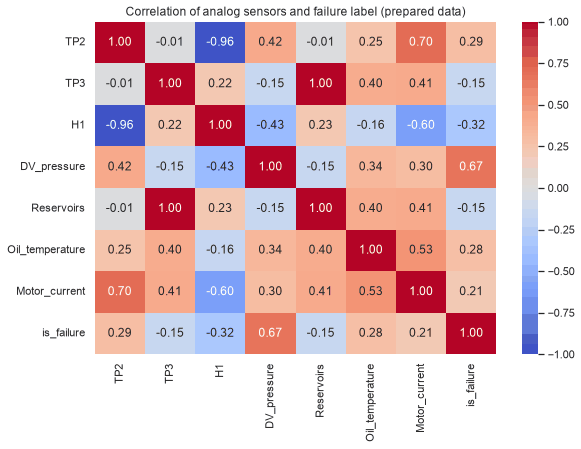

,Correlation with is_failure
H1,-0.32
TP3,-0.15
Reservoirs,-0.15
Motor_current,0.21
Oil_temperature,0.28
TP2,0.29
DV_pressure,0.67


In [69]:
# Correlation of the sensors with the failure label in the prepared data
corr_final = df[analog_columns + ['is_failure']].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_final, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation of analog sensors and failure label (prepared data)')
plt.show()

display(corr_final['is_failure'].drop('is_failure').sort_values().round(2).to_frame('Correlation with is_failure'))

#### 4.6.5 Data distribution inside and outside the failure windows

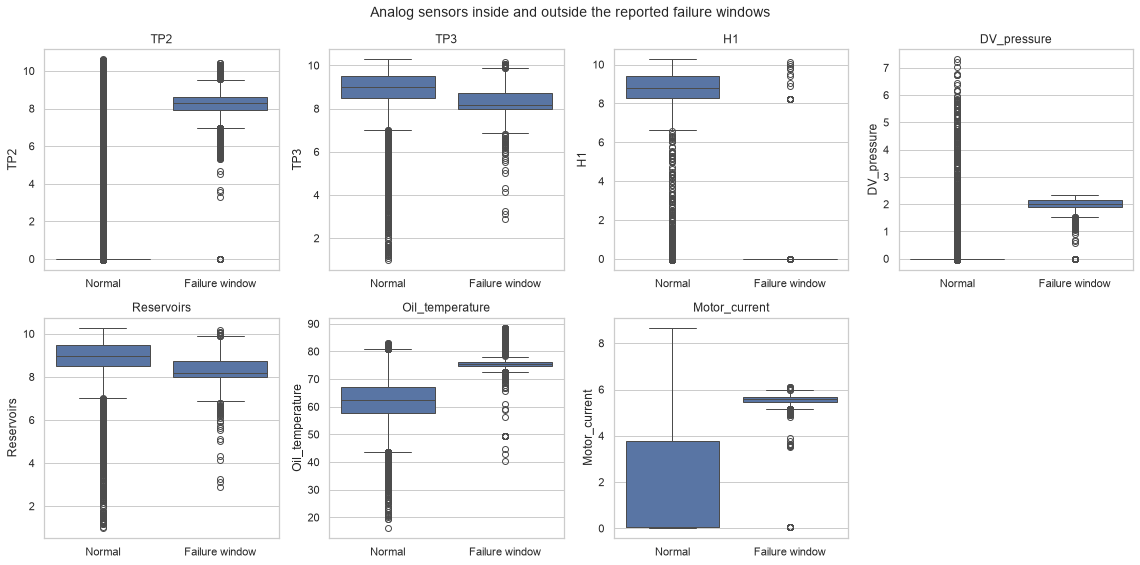

is_failure,Median normal,Median failure window
TP2,-0.01,8.27
TP3,8.98,8.17
H1,8.81,-0.01
DV_pressure,-0.02,2.01
Reservoirs,8.98,8.17
Oil_temperature,62.55,75.48
Motor_current,0.04,5.57


In [70]:
# Distribution of each analog sensor inside and outside the failure windows.
# A random sample keeps the plot fast; the fixed seed makes it reproducible.
sample = df.sample(200_000, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), analog_columns):
    sns.boxplot(data=sample, x='is_failure', y=col, ax=ax)
    ax.set_xticks([0, 1], ['Normal', 'Failure window'])
    ax.set_xlabel('')
    ax.set_title(col)
axes.flatten()[-1].axis('off')
plt.suptitle('Analog sensors inside and outside the reported failure windows')
plt.tight_layout()
plt.show()

display(df.groupby('is_failure')[analog_columns].median().T.round(2)
         .rename(columns={0: 'Median normal', 1: 'Median failure window'}))

In [71]:
# Operating states inside and outside the failure windows (% of rows per column)
pd.crosstab(df['motor_state'], df['is_failure'], normalize='columns').mul(100).round(1)

is_failure,0,1
motor_state,,
Off / near zero,55.7,0.3
Possible loaded / startup,13.5,98.9
Possible unloaded,30.7,0.8


**Summary:** The prepared dataset has **1,516,948 rows and 22 columns**: the timestamp, 7 analog sensors, 8 digital signals (`int8`) and 6 new columns (`segment_id`, `sensors_frozen`, `motor_state`, `is_failure`, `failure_window_id`, `hours_to_next_failure`). Each column is documented with its scale, value range and meaning in 4.6.2.

- **Missing data:** only `hours_to_next_failure` has empty values (344,233 rows, 22.7%). These are the readings after the last reported failure (15 July 2020), where no next failure exists. This is expected and is not filled.
- **Class balance:** only **2.0%** of the rows (29,954) fall inside a reported failure window, so the classes are strongly imbalanced.
- **Correlation with the failure label:** DV_pressure has the strongest relationship (0.67), followed by H1 (−0.32), TP2 (0.29) and Oil_temperature (0.28). The values are moderate because the same sensors also switch between levels during normal operation.
- **Distribution:** inside the failure windows the medians are completely different from normal operation:

| Sensor | Median normal | Median failure window |
|---|---|---|
| TP2 | −0.01 bar | 8.27 bar |
| H1 | 8.81 bar | −0.01 bar |
| DV_pressure | −0.02 bar | 2.01 bar |
| TP3 / Reservoirs | 8.98 bar | 8.17 bar |
| Oil_temperature | 62.6 °C | 75.5 °C |
| Motor_current | 0.04 A | 5.57 A |

- **Operating state:** inside the failure windows the compressor runs loaded or at start-up **98.9% of the time**, compared with 13.5% during normal operation.

**Conclusion:** a failure is easy to recognise *while* it is happening. The research question is whether these changes start early enough *before* a failure window to give a 2-hour warning; this is analysed in section 5. The failure columns are used only for evaluation, never for training.

### 4.7 Export the prepared dataset

The model-ready dataset is saved so that the Modeling phase can start from it without repeating Data Preparation.

- **Format: Parquet.** With 1,516,948 rows, a CSV file would be about 222 MB and lose the data types (the timestamp would be read back as text). Parquet keeps the types (datetime, `int8`) and is about 10 times smaller. A CSV would also not open completely in Excel, which is limited to 1,048,576 rows.
- **Location:** `data/processed/metropt3_prepared.parquet`. The file is not committed to GitHub (see `.gitignore`); it is recreated by running this notebook.
- **Loading it later:** `df = pd.read_parquet("data/processed/metropt3_prepared.parquet")`

In [72]:
# Export the prepared, model-ready dataset.
# Parquet keeps the data types (datetime, int8) and is about 10x smaller than CSV.
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)
output_file = output_dir / "metropt3_prepared.parquet"

df.to_parquet(output_file, index=False)
print(f"Exported {len(df):,} rows x {df.shape[1]} columns to {output_file} "
      f"({output_file.stat().st_size / 1e6:.1f} MB)")

# Check: reload the file and compare it with the data frame in memory
check = pd.read_parquet(output_file)
print("Export verified:", check.equals(df))

Exported 1,516,948 rows x 22 columns to data\processed\metropt3_prepared.parquet (28.4 MB)


Export verified: True


### 4.8 Exploratory Data Analysis

This section is a guided tour of the prepared dataset for a reader who sees it for the first time. Each chart answers one question, moving from the big picture to the details:

| # | Question | Chart |
|---|---|---|
| 4.8.1 | What happened over the seven months? | Hourly sensor values over the whole period |
| 4.8.2 | How does the compressor work in normal operation? | Zoom into two hours of a normal day |
| 4.8.3 | How does the compressor spend its time? | Operating states per month and per hour of the day |
| 4.8.4 | How are the sensors related? | Pair plot, coloured by operating state |
| 4.8.5 | What is different during a failure? | Sensors under load: normal vs failure |
| 4.8.6 | What happens in the hours before a failure? | The 72 hours before each failure, side by side |

Section 3.5 explored the raw data to judge its quality. This section uses the prepared columns (`motor_state`, `segment_id`, `is_failure`, `hours_to_next_failure`) to understand the behaviour of the compressor. Failure windows are shaded red in every time chart; dashed lines mark the reported maintenance. The frozen sensor readings (3.4.6) are left out.

In [73]:
# Settings shared by the EDA charts
import matplotlib.dates as mdates

state_names = {'Off / near zero': 'Off', 'Possible unloaded': 'Offloaded', 'Possible loaded / startup': 'Loaded'}
state = df['motor_state'].map(state_names)
state_order = ['Off', 'Offloaded', 'Loaded']
eda_state_colors = {'Off': '#9a9a94', 'Offloaded': '#2a78d6', 'Loaded': '#eb6834'}
failure_colors = {1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a', 4: '#eda100'}

# Maintenance times from the failure reports. F2's maintenance is printed as 30 Apr, before the failure, so it is not drawn.
maintenance_times = pd.to_datetime(['2020-06-08 16:00', '2020-07-16 00:00'])

def mark_events(ax, labels=False):
    """Shade the failure windows and draw the maintenance times on a time axis."""
    shade_failures(ax, labels=labels)
    for t in maintenance_times:
        ax.axvline(t, color='#555555', linestyle='--', linewidth=1)

def tidy(ax):
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)

# Hourly table used by several charts: hours without data stay empty (NaN), so lines break at gaps
# Frozen sensor readings (4.3) are left out of all EDA charts.
usable = df['sensors_frozen'] == 0
hourly = df[usable].set_index('timestamp')
hourly = pd.concat([hourly[analog_columns].resample('h').mean(),
                    (hourly['motor_state'] == 'Possible loaded / startup').resample('h').mean().mul(100).rename('loaded_pct'),
                    hourly['is_failure'].resample('h').max()], axis=1)
print('Readings used:', f'{usable.sum():,}', '| hours in the period:', len(hourly), '| hours with data:', hourly['TP3'].notna().sum())

Readings used: 1,466,093 | hours in the period: 5116 | hours with data: 4251


#### 4.8.1 The seven months at a glance

Four views of the whole period, one point per hour: the pressure that the compressor has to keep up, the oil temperature, the pressure drop at the air dryer, and how much of each hour the compressor ran under load.

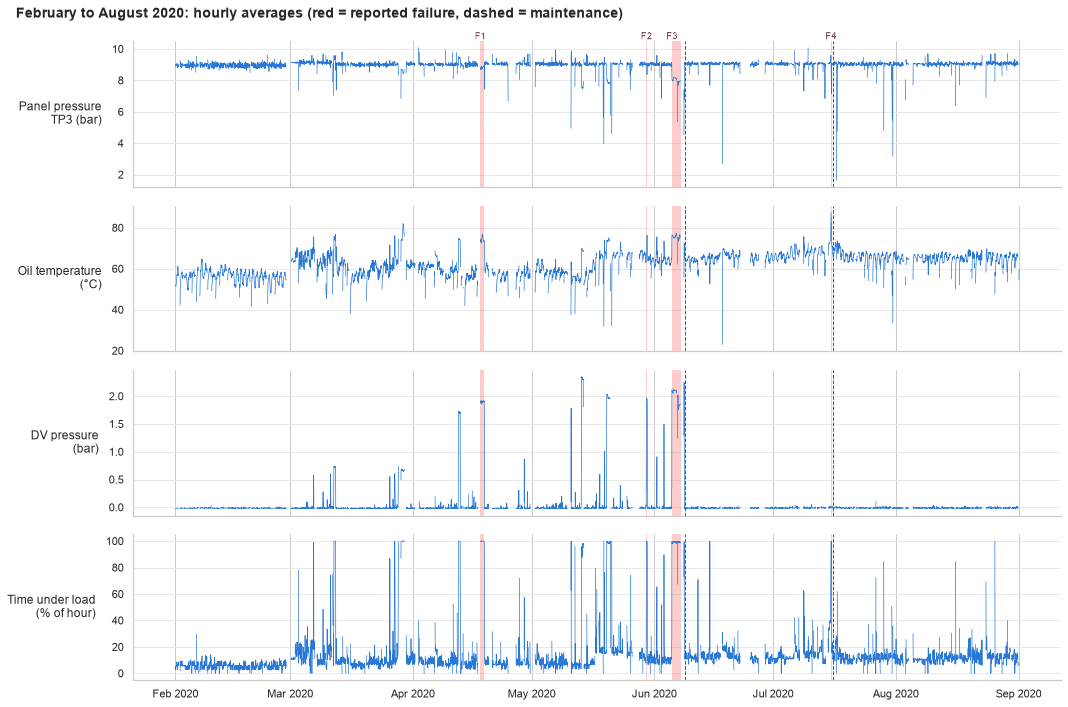

,TP3,Oil_temperature,DV_pressure,loaded_pct
timestamp,,,,
Feb,8.97,56.12,-0.02,5.75
Mar,9.02,62.00,0.03,16.70
Apr,9.01,59.23,0.12,15.40
May,8.91,61.69,0.14,18.33
Jun,8.91,65.85,0.18,21.00
Jul,8.97,66.69,-0.01,14.92
Aug,9.04,64.95,-0.01,12.28


In [74]:
panels = [('TP3', 'Panel pressure\nTP3 (bar)'), ('Oil_temperature', 'Oil temperature\n(°C)'),
          ('DV_pressure', 'DV pressure\n(bar)'), ('loaded_pct', 'Time under load\n(% of hour)')]

fig, axes = plt.subplots(len(panels), 1, figsize=(15, 10), sharex=True)
for ax, (col, label) in zip(axes, panels):
    ax.plot(hourly.index, hourly[col], linewidth=0.7, color='#2a78d6')
    mark_events(ax, labels=(ax is axes[0]))
    ax.set_ylabel(label, rotation=0, ha='right', va='center', labelpad=10)
    tidy(ax)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.suptitle('February to August 2020: hourly averages (red = reported failure, dashed = maintenance)', x=0.02, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

monthly = hourly.resample('MS').mean()[['TP3', 'Oil_temperature', 'DV_pressure', 'loaded_pct']]
monthly = monthly.loc[:'2020-08']   # September has only 4 hours
monthly.index = monthly.index.strftime('%b')
display(monthly.round(2))

**Figure: the seven months at a glance.**

- **Panel pressure (TP3)** stays at about 9 bar almost all the time (monthly average 8.9–9.0 bar): the compressor keeps the pressure stable. Short downward spikes occur throughout the period, also far from any failure.
- **Oil temperature** rises with the season, from about 56 °C in February to 66–67 °C in June and July. A model trained only on the cooler months could mistake normal summer temperatures for an anomaly.
- **DV pressure** is close to 0 bar almost always. It jumps to about 2 bar in every failure window, but also in several short episodes without a failure report (March to May).
- **Time under load** is about 6% in February and 15–21% from March onwards. Hours with 100% load appear in every failure window and in a few unreported episodes.

The failure windows are easy to see as sudden blocks of continuous load and high DV pressure. February is quieter than the other months, which matters because it is part of the healthy training period.

#### 4.8.2 How the compressor works: two hours of normal operation

To read the other charts it helps to see one normal operating cycle in detail. The chart zooms into two hours of a healthy day in March, far away from any failure. Orange areas are the periods in which the compressor runs under load.

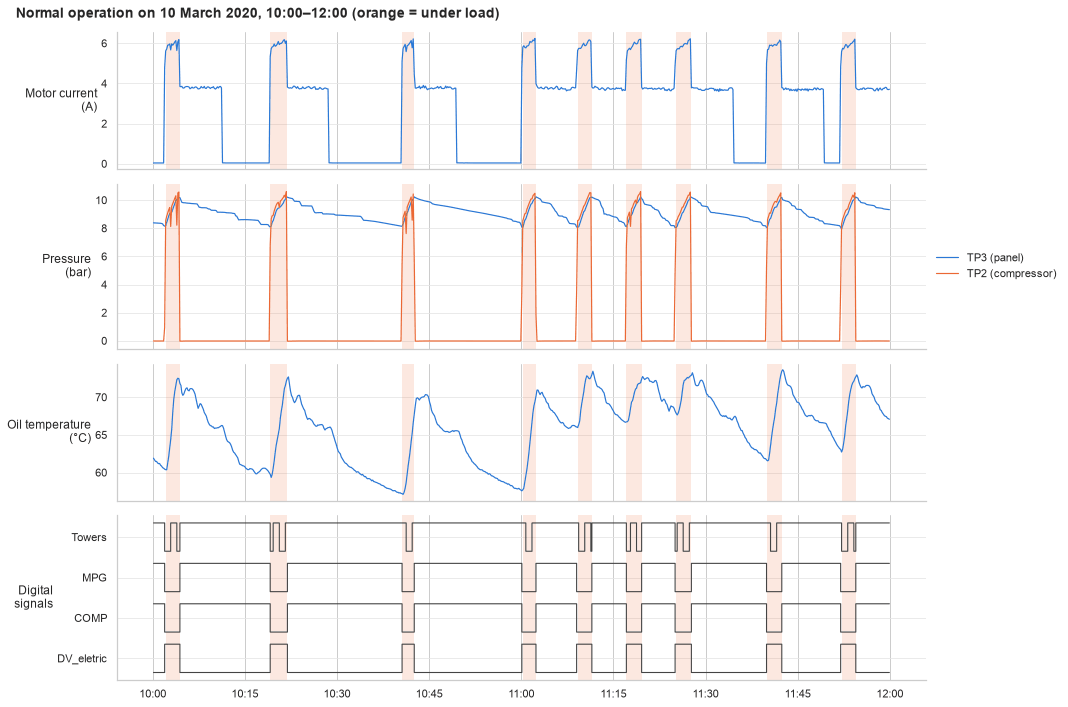

Load phases in these two hours: 9, lasting 2.0–2.8 min


,Motor_current,TP2,TP3,Oil_temperature
motor_state,,,,
Off,0.04,-0.01,8.62,60.78
Offloaded,3.75,-0.01,9.46,68.82
Loaded,5.92,9.64,9.28,67.88


In [75]:
zoom_start = pd.Timestamp('2020-03-10 10:00')
zoom = df[df['timestamp'].between(zoom_start, zoom_start + pd.Timedelta(hours=2))].copy()
zoom_loaded = (zoom['motor_state'] == 'Possible loaded / startup')
# Start and end of each loaded period, for the orange shading
edges = zoom_loaded.astype(int).diff().fillna(zoom_loaded.iloc[0].astype(int))
load_starts = zoom.loc[edges == 1, 'timestamp'].tolist()
load_ends = zoom.loc[edges == -1, 'timestamp'].tolist() + ([zoom['timestamp'].iloc[-1]] if zoom_loaded.iloc[-1] else [])

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True, gridspec_kw={'height_ratios': [1, 1.2, 1, 1.2]})
axes[0].plot(zoom['timestamp'], zoom['Motor_current'], color='#2a78d6', linewidth=1.2)
axes[0].set_ylabel('Motor current\n(A)', rotation=0, ha='right', va='center')
axes[1].plot(zoom['timestamp'], zoom['TP3'], color='#2a78d6', linewidth=1.2, label='TP3 (panel)')
axes[1].plot(zoom['timestamp'], zoom['TP2'], color='#eb6834', linewidth=1.2, label='TP2 (compressor)')
axes[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
axes[1].set_ylabel('Pressure\n(bar)', rotation=0, ha='right', va='center')
axes[2].plot(zoom['timestamp'], zoom['Oil_temperature'], color='#2a78d6', linewidth=1.2)
axes[2].set_ylabel('Oil temperature\n(°C)', rotation=0, ha='right', va='center')
# Digital signals as stacked on/off lanes
lanes = ['DV_eletric', 'COMP', 'MPG', 'Towers']
for k, col in enumerate(lanes):
    axes[3].step(zoom['timestamp'], zoom[col] * 0.7 + k, where='post', color='#444444', linewidth=1.1)
axes[3].set_yticks([k + 0.35 for k in range(len(lanes))], lanes)
axes[3].set_ylabel('Digital\nsignals', rotation=0, ha='right', va='center')
for ax in axes:
    for a, b in zip(load_starts, load_ends):
        ax.axvspan(a, b, color='#eb6834', alpha=0.15, linewidth=0)
    tidy(ax)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.suptitle(f'Normal operation on {zoom_start:%d %B %Y}, {zoom_start:%H:%M}–{zoom_start + pd.Timedelta(hours=2):%H:%M} (orange = under load)',
             x=0.02, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

durations = [(b - a).total_seconds() / 60 for a, b in zip(load_starts, load_ends)]
print(f'Load phases in these two hours: {len(durations)}, lasting {min(durations):.1f}–{max(durations):.1f} min')
display(zoom.groupby(state.loc[zoom.index])[['Motor_current', 'TP2', 'TP3', 'Oil_temperature']].median().reindex(state_order).round(2))

**Figure: two hours of normal operation.** The compressor works in short, regular cycles:

1. When the panel pressure TP3 has fallen to about 8.2 bar, the compressor starts **under load** (orange): the motor current jumps to about 6 A, `DV_eletric` switches to 1 and `COMP` and `MPG` switch to 0.
2. The compressor pressure TP2 rises to about 10 bar and refills the panel (TP3 rises from about 8.2 to 10 bar). Each load phase lasts only **2–3 minutes**; there are 9 in these two hours.
3. The compressor then runs **offloaded** (about 3.8 A, TP2 back to 0 bar) and either switches **off** (0 A) or waits for the next start. TP3 slowly falls as the train uses air.
4. The oil temperature rises by about 10 °C in every load phase and cools slowly afterwards, a saw-tooth pattern. `Towers` switches the drying tower in every load phase.

This cycle is the "normal" that the anomaly detection has to learn. During an air leak the cycle disappears: the compressor stays loaded, TP3 cannot be refilled and the oil stays hot (see 3.5.5 and 4.8.5).

#### 4.8.3 How the compressor spends its time

Share of readings in each operating state, per month and per hour of the day. Only hours with data are counted.

In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   timestamp              1516948 non-null  datetime64[us]
 1   TP2                    1516948 non-null  float64       
 2   TP3                    1516948 non-null  float64       
 3   H1                     1516948 non-null  float64       
 4   DV_pressure            1516948 non-null  float64       
 5   Reservoirs             1516948 non-null  float64       
 6   Oil_temperature        1516948 non-null  float64       
 7   Motor_current          1516948 non-null  float64       
 8   COMP                   1516948 non-null  int8          
 9   DV_eletric             1516948 non-null  int8          
 10  Towers                 1516948 non-null  int8          
 11  MPG                    1516948 non-null  int8          
 12  LPS                    1516948 non-null

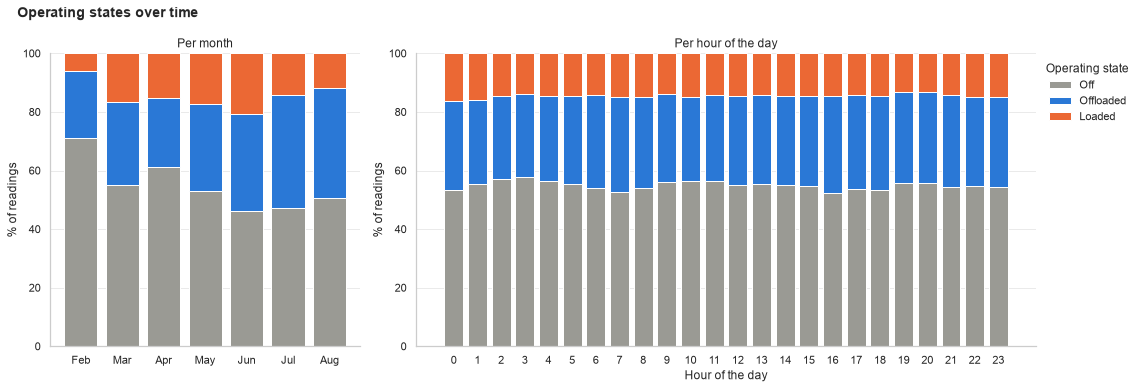

motor_state,Off,Offloaded,Loaded
timestamp,,,
Feb,71.3,22.9,5.9
Mar,55.0,28.5,16.6
Apr,61.1,23.6,15.3
May,53.0,29.7,17.4
Jun,46.0,33.4,20.6
Jul,47.3,38.3,14.4
Aug,50.8,37.2,12.0


Loaded share per hour of the day: 13.2% to 16.1%
Readings per hour of the day: 47,344 (hour 1) to 68,436 (hour 6)


In [77]:
by_month = pd.crosstab(df.loc[usable, 'timestamp'].dt.to_period('M'), state[usable], normalize='index').mul(100)[state_order]
by_month = by_month.loc[by_month.index < pd.Period('2020-09', 'M')]   # September has only 4 hours
by_hour = pd.crosstab(df.loc[usable, 'timestamp'].dt.hour, state[usable], normalize='index').mul(100)[state_order]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1, 2]})
for ax, table, xlabels in [(axes[0], by_month, by_month.index.strftime('%b')), (axes[1], by_hour, by_hour.index)]:
    bottom = np.zeros(len(table))
    for s in state_order:
        ax.bar(range(len(table)), table[s], bottom=bottom, color=eda_state_colors[s], label=s,
               width=0.8, edgecolor='white', linewidth=1)
        bottom += table[s].values
    ax.set_xticks(range(len(table)), xlabels)
    ax.set_ylim(0, 100)
    ax.set_ylabel('% of readings')
    tidy(ax)
axes[0].set_title('Per month')
axes[1].set_title('Per hour of the day')
axes[1].set_xlabel('Hour of the day')
axes[1].legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False, title='Operating state')
fig.suptitle('Operating states over time', x=0.02, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

display(by_month.round(1).rename(index=lambda m: m.strftime('%b')))
print(f"Loaded share per hour of the day: {by_hour['Loaded'].min():.1f}% to {by_hour['Loaded'].max():.1f}%")
readings_per_hour = df.loc[usable, 'timestamp'].dt.hour.value_counts().sort_index()
print(f'Readings per hour of the day: {readings_per_hour.min():,} (hour {readings_per_hour.idxmin()}) to {readings_per_hour.max():,} (hour {readings_per_hour.idxmax()})')

**Figure: operating states over time.**

- Overall the compressor is **off about half the time**, offloaded about 30% and loaded about 15%.
- **Per month:** February stands out with only 6% loaded and 71% off. From March the loaded share is 14–21%, highest in June (21%, including F3). In July and August the compressor runs offloaded more often (37–38%).
- **Per hour of the day:** the loaded share is almost constant (13.2–16.1%). The time of day does not change *how* the compressor works, only *how much* data exists (about 47,000 readings at 1 a.m. compared with 68,000 at 6 a.m.).

**Consequence for Modeling:** the hour of the day is not needed as a feature. February has a lower load than the later months; if it is used for training, the model may treat the normal higher load of later months as unusual. The month-to-month level must be checked when the training period is chosen.

#### 4.8.4 How the sensors are related

Each small chart plots two sensors against each other; the diagonal shows each sensor's distribution. The points are a random sample of 15,000 readings, coloured by operating state.

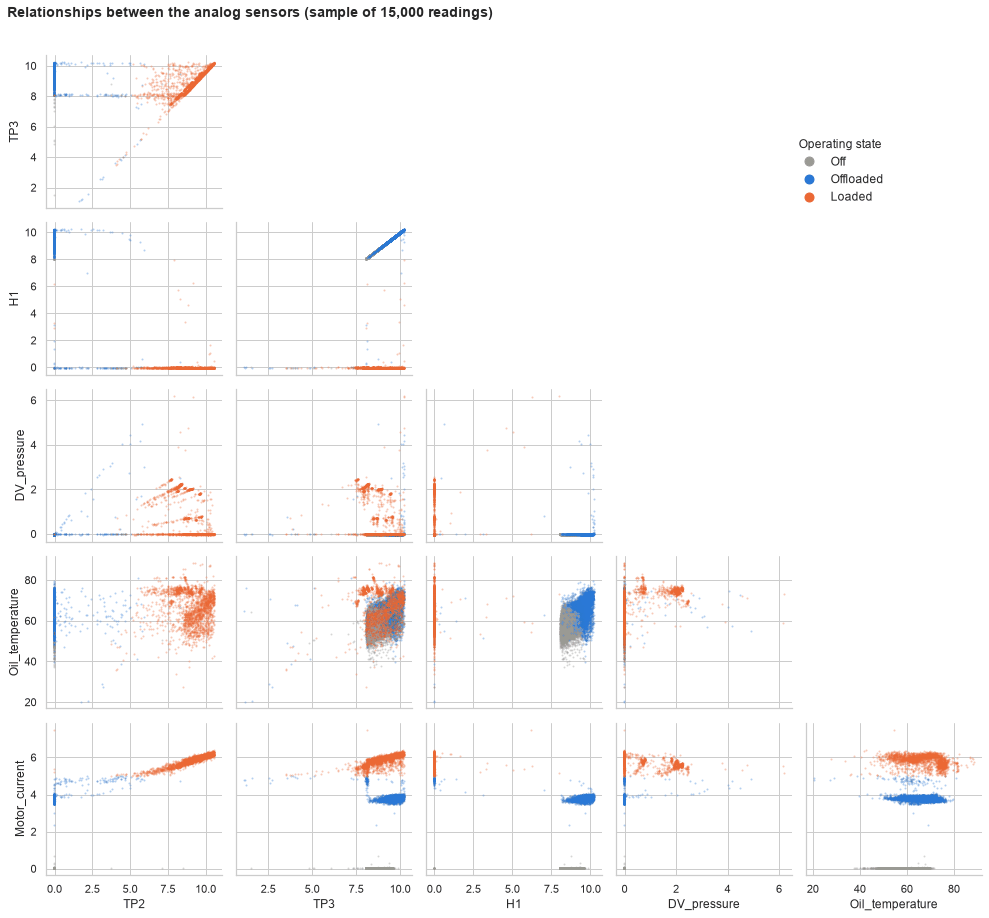

Correlation within the loaded state:


,TP2,TP3,H1,DV_pressure,Oil_temperature,Motor_current
TP2,1.00,0.74,-0.19,-0.34,-0.01,0.85
TP3,0.74,1.00,0.03,-0.37,0.06,0.71
H1,-0.19,0.03,1.00,0.18,-0.01,0.02
DV_pressure,-0.34,-0.37,0.18,1.00,0.55,-0.51
Oil_temperature,-0.01,0.06,-0.01,0.55,1.00,-0.25
Motor_current,0.85,0.71,0.02,-0.51,-0.25,1.00


In [78]:
# Lower triangle of scatter plots: each panel compares two sensors (no diagonal; the distributions are shown in 3.5.4)
from matplotlib.lines import Line2D

pair_cols = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Oil_temperature', 'Motor_current']
pair_sample = df.loc[usable, pair_cols].assign(state=state[usable]).sample(15_000, random_state=42)
n = len(pair_cols) - 1
fig, axes = plt.subplots(n, n, figsize=(14, 13), sharex='col', sharey='row')
for r in range(n):
    for c in range(n):
        ax = axes[r, c]
        if c > r:
            ax.set_visible(False)
            continue
        x, y = pair_cols[c], pair_cols[r + 1]
        for s in state_order:
            part = pair_sample[pair_sample['state'] == s]
            ax.scatter(part[x], part[y], s=4, alpha=0.35, color=eda_state_colors[s], linewidths=0, rasterized=True)
        ax.spines[['top', 'right']].set_visible(False)
        if c == 0:
            ax.set_ylabel(y)
        if r == n - 1:
            ax.set_xlabel(x)
handles = [Line2D([], [], marker='o', linestyle='', markersize=9, color=eda_state_colors[s], label=s) for s in state_order]
fig.legend(handles=handles, title='Operating state', loc='upper right', bbox_to_anchor=(0.9, 0.85), frameon=False, fontsize=12)
fig.suptitle('Relationships between the analog sensors (sample of 15,000 readings)', x=0.02, ha='left', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

print('Correlation within the loaded state:')
display(df.loc[usable & (state == 'Loaded'), pair_cols].corr().round(2))

**Figure: relationships between the sensors.**

- **The operating states form separate clusters.** Motor current alone separates them (bands at 0, about 3.8 and about 6 A), and H1 is about 8–10 bar when the compressor is off or offloaded and 0 bar under load.
- **Under load, TP2 and Motor_current rise together** (r = 0.85 within the loaded state): the higher the pressure the compressor works against, the more current the motor draws. TP2 and TP3 are also closely linked (r = 0.74).
- **The air-leak signature is visible as its own cluster:** loaded readings with DV pressure about 2 bar and oil temperature about 75 °C (top-left of the DV_pressure/Oil_temperature panel). Within the loaded state these two sensors correlate with r = 0.55, mainly because of these failure readings.

**Consequence for Modeling:** the relationships between sensors depend on the operating state, and the leak shows up as a *combination* of sensors (high DV pressure, high oil temperature, low panel pressure). A multivariate model can catch such combinations better than limits on single sensors.

#### 4.8.5 What is different during a failure?

98.9% of the readings inside the failure windows are taken under load (4.6.5). Comparing failure readings with *all* normal readings would therefore mostly show the difference between loaded and not loaded. Here both groups contain **only loaded readings**, so the remaining difference is caused by the air leak.

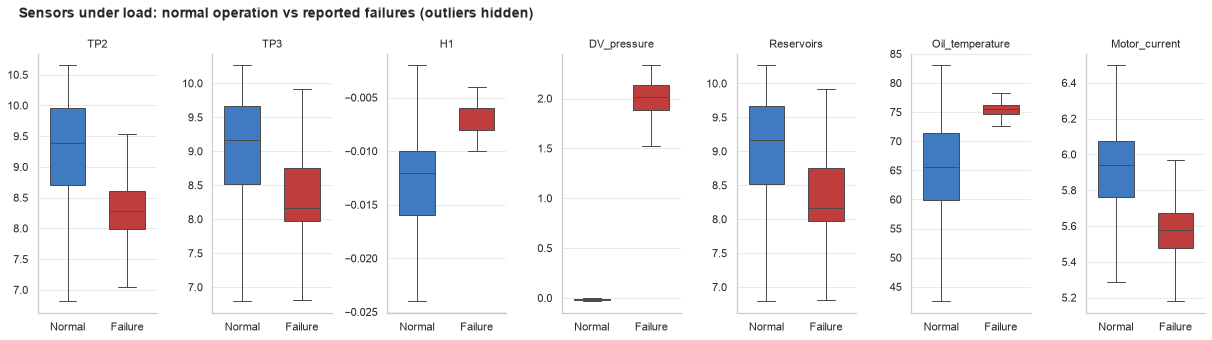

,Normal (loaded),Failure (loaded),Difference
TP2,9.38,8.28,-1.10
TP3,9.17,8.17,-1.00
H1,-0.01,-0.01,0.00
DV_pressure,-0.02,2.01,2.03
Reservoirs,9.17,8.17,-1.00
Oil_temperature,65.62,75.48,9.85
Motor_current,5.94,5.58,-0.37


In [79]:
loaded = df.loc[usable & (state == 'Loaded'), analog_columns + ['is_failure']]
loaded_sample = pd.concat([loaded[loaded['is_failure'] == 0].sample(100_000, random_state=42),
                           loaded[loaded['is_failure'] == 1]])
loaded_sample['group'] = loaded_sample['is_failure'].map({0: 'Normal', 1: 'Failure'})

fig, axes = plt.subplots(1, len(analog_columns), figsize=(17, 4.8))
for ax, col in zip(axes, analog_columns):
    sns.boxplot(data=loaded_sample, x='group', y=col, hue='group', order=['Normal', 'Failure'],
                palette={'Normal': '#2a78d6', 'Failure': '#d62728'}, ax=ax, showfliers=False, width=0.6, legend=False)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('')
    tidy(ax)
fig.suptitle('Sensors under load: normal operation vs reported failures (outliers hidden)', x=0.02, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

medians = loaded.groupby('is_failure')[analog_columns].median().T
medians.columns = ['Normal (loaded)', 'Failure (loaded)']
medians['Difference'] = medians['Failure (loaded)'] - medians['Normal (loaded)']
display(medians.round(2))

**Figure: normal vs failure, both under load.** Even when only loaded readings are compared, the failure readings are clearly different:

| Sensor | Normal (loaded) | Failure (loaded) | Difference | Physical explanation |
|---|---|---|---|---|
| DV_pressure | −0.02 bar | 2.01 bar | +2.0 bar | The air dryer discharges continuously |
| Oil_temperature | 65.6 °C | 75.5 °C | +9.9 °C | The compressor runs without cooling pauses |
| TP3 / Reservoirs | 9.17 bar | 8.17 bar | −1.0 bar | Air escapes as fast as it is produced; the panel cannot be refilled |
| TP2 | 9.38 bar | 8.28 bar | −1.1 bar | Lower back-pressure on the compressor |
| Motor_current | 5.94 A | 5.58 A | −0.4 A | Less effort against the lower pressure |
| H1 | −0.01 bar | −0.01 bar | none | H1 is 0 under load in both cases |

The failure readings also have a much **narrower** spread than normal loaded operation: during an air leak the compressor is in one stable "leak mode". This makes the failure easy to detect *while it happens*. The next chart asks whether anything changes *before*.

#### 4.8.6 What happens in the hours before a failure?

The research question asks whether a model can warn *before* a failure. This chart puts the four failures side by side: the x-axis is the time relative to the start of each failure window (0 = start, negative = before). If a sensor changed consistently in the hours before, the four lines would move together left of zero.

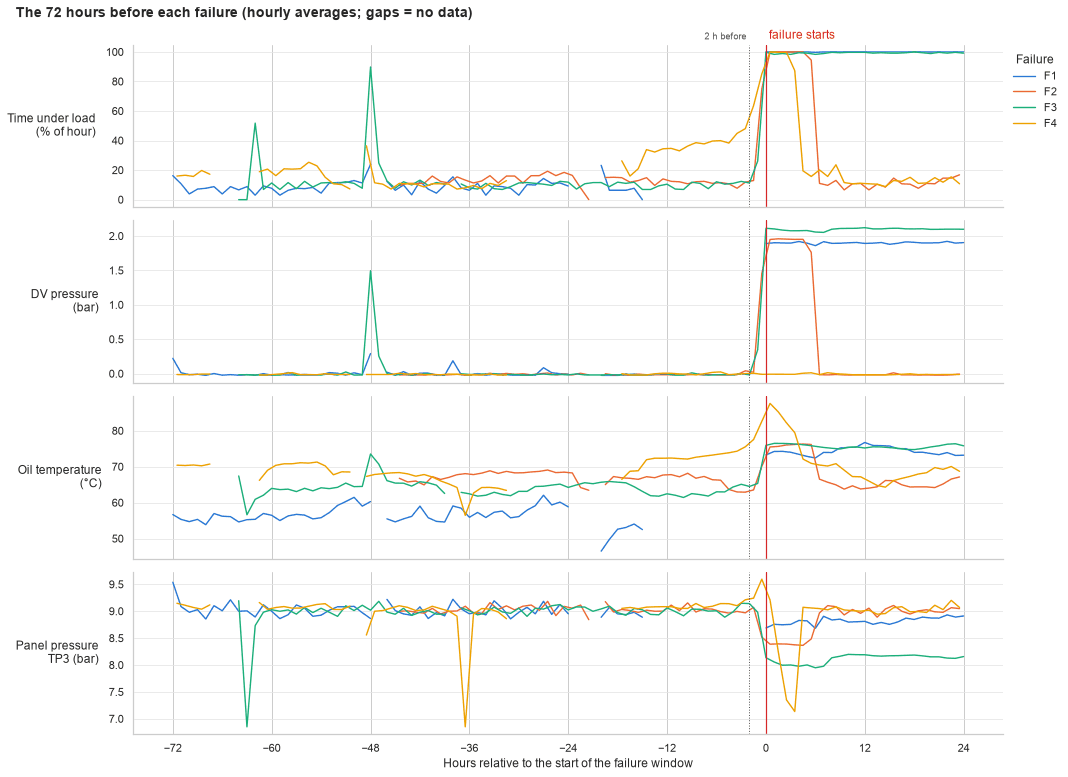

,loaded_pct,DV_pressure,Oil_temperature,TP3
Healthy reference (median hour),7.16,-0.02,58.82,9.01
F1: 48–24 h before,9.64,-0.01,57.28,8.98
F1: last 24 h before,6.34,-0.02,52.61,8.95
F2: 48–24 h before,13.22,-0.01,68.13,9.02
F2: last 24 h before,12.12,-0.02,66.80,9.01
F3: 48–24 h before,10.62,-0.01,64.57,9.01
F3: last 24 h before,11.02,-0.02,64.30,9.02
F4: 48–24 h before,10.47,-0.01,66.06,9.01
F4: last 24 h before,37.00,-0.00,72.53,9.08


Hours with data in the 24 h before each failure: {1: 7, 2: 23, 3: 24, 4: 18}


In [80]:
before_hours, after_hours = 72, 24
aligned = []
for _, event in failure_events.iterrows():
    part = hourly.loc[event['start_time'] - pd.Timedelta(hours=before_hours): event['start_time'] + pd.Timedelta(hours=after_hours)].copy()
    part['hours_rel'] = (part.index - event['start_time']).total_seconds() / 3600
    part['failure_id'] = event['failure_id']
    part['duration_h'] = event['duration_hours']
    aligned.append(part)
aligned = pd.concat(aligned)

panels = [('loaded_pct', 'Time under load\n(% of hour)'), ('DV_pressure', 'DV pressure\n(bar)'),
          ('Oil_temperature', 'Oil temperature\n(°C)'), ('TP3', 'Panel pressure\nTP3 (bar)')]
fig, axes = plt.subplots(len(panels), 1, figsize=(15, 11), sharex=True)
for ax, (col, label) in zip(axes, panels):
    for fid, part in aligned.groupby('failure_id'):
        ax.plot(part['hours_rel'], part[col], color=failure_colors[fid], linewidth=1.4, label=f'F{fid}')
    ax.axvline(0, color='#d62728', linewidth=1.2)
    ax.axvline(-2, color='#555555', linestyle=':', linewidth=1)
    ax.set_ylabel(label, rotation=0, ha='right', va='center', labelpad=10)
    tidy(ax)
axes[0].annotate('failure starts', (0, 1.02), xycoords=('data', 'axes fraction'), ha='left', va='bottom', color='#d62728',
                 xytext=(3, 0), textcoords='offset points')
axes[0].annotate('2 h before', (-2, 1.02), xycoords=('data', 'axes fraction'), ha='right', va='bottom', color='#555555', fontsize=9,
                 xytext=(-3, 0), textcoords='offset points')
axes[0].legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False, title='Failure')
axes[-1].set_xlabel('Hours relative to the start of the failure window')
axes[-1].set_xticks(range(-before_hours, after_hours + 1, 12))
fig.suptitle('The 72 hours before each failure (hourly averages; gaps = no data)', x=0.02, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

# Compare the last 24 h and the 24 h before that with the healthy reference period (1 Feb – 11 Apr)
healthy = hourly.loc[:'2020-04-11', ['loaded_pct', 'DV_pressure', 'Oil_temperature', 'TP3']]
rows = {'Healthy reference (median hour)': healthy.median()}
for fid, part in aligned.groupby('failure_id'):
    rows[f'F{fid}: 48–24 h before'] = part.loc[part['hours_rel'].between(-48, -24, inclusive='left'), healthy.columns].median()
    rows[f'F{fid}: last 24 h before'] = part.loc[part['hours_rel'].between(-24, 0, inclusive='left'), healthy.columns].median()
display(pd.DataFrame(rows).T.round(2))
print('Hours with data in the 24 h before each failure:',
      aligned[aligned['hours_rel'].between(-24, 0, inclusive='left')].groupby('failure_id')['TP3'].count().to_dict())

**Figure: the 72 hours before each failure.** The four failures behave differently:

- **F1 and F3:** no visible change until the start of the window. Load share and DV pressure jump within the last hour. Before F1 the frozen period on 17 April (3.4.6) leaves only 7 hours of usable data in the last 24 hours, so a warning would have been hard to give anyway. F3 has one short episode 48 hours before (90% load and 1.5 bar DV pressure for about one hour), which may be an early sign but could also be normal operation.
- **F2:** no visible change at all in the 72 hours before.
- **F4: the clearest precursor.** From about **14 hours before** the window, the load share rises from about 10% to 35–45% and the oil temperature from about 66 °C to 73–77 °C, while DV pressure stays at 0. The compressor already works harder before the leak is reported.

| | Load share | DV pressure | Oil temperature | TP3 |
|---|---|---|---|---|
| Healthy reference (median hour) | 7% | −0.02 bar | 58.8 °C | 9.01 bar |
| F4, 48–24 h before | 10% | −0.01 bar | 66.1 °C | 9.01 bar |
| F4, last 24 h before | **37%** | −0.00 bar | **72.5 °C** | 9.08 bar |

**Consequence for the research question:** with hourly averages, only one of four failures (F4) shows a change long enough before the failure for a 2-hour warning. For the others, a model will have to find subtler signs, for example longer load phases or faster pressure drops between cycles (see the normal cycle in 4.8.2). The results will be reported per failure, and a missing early warning is a valid, honest result.

#### 4.8.7 Summary of the Exploratory Data Analysis

| # | Finding | Consequence for Modeling |
|---|---|---|
| 1 | Normal operation is a regular cycle of 2–3-minute load phases; an air leak breaks it (continuous load) | Use features that describe the cycle (load share, duration of load phases, time since the last stop) and not only single readings |
| 2 | Every sensor behaves differently in each operating state | State-aware features or scaling (`motor_state`) |
| 3 | Oil temperature rises with the season (+10 °C from February to July); February has less load | Check the training period carefully; a model trained only on cool months may give false alarms in summer |
| 4 | The air leak has a clear signature: DV pressure about 2 bar, oil about 75 °C, panel pressure −1 bar, continuous load | Detecting the failure *during* the window is easy; a multivariate model can use the combination |
| 5 | Only F4 shows a visible precursor (about 14 hours of rising load and oil temperature); F1–F3 do not at hourly level | Expect early warning to be hard; report lead time per failure |
| 6 | 3.4% of the readings are frozen (logger fault); 17 April leaves only 7 usable hours before F1 | Exclude `sensors_frozen = 1`; report where missing data limits the warning time |
| 7 | Eight abnormal days without a failure report (March to May) | Report alarms on these days separately instead of counting them blindly as false alarms |

The prepared dataset is ready for the Modeling phase: unsupervised anomaly detection trained on the healthy period, evaluated against the four reported failures with warning lead time as the main metric.

## 5. Sensor Behavior and Failure Analysis

### 5.1 Visualizing sensor behavior over time

In [81]:
#Preparing time-series data
# Work with a copy of the original dataset
ts_df = df.copy()


# Sort chronologically
ts_df = ts_df.sort_values('timestamp')

# Use timestamp as index
ts_df = ts_df.set_index('timestamp')

print("Dataset period:", ts_df.index.min(), "to", ts_df.index.max())
print("Number of observations:", len(ts_df))

display(ts_df.head())

Dataset period: 2020-02-01 00:00:00 to 2020-09-01 03:59:50
Number of observations: 1516948


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,...,LPS,Pressure_switch,Oil_level,Caudal_impulses,segment_id,sensors_frozen,motor_state,is_failure,failure_window_id,hours_to_next_failure
timestamp,,,,,,,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1,0,1,...,0,1,1,1,0,0,Off / near zero,0,0,1848.000000
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1,0,1,...,0,1,1,1,0,0,Off / near zero,0,0,1847.997222
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1,0,1,...,0,1,1,1,0,0,Off / near zero,0,0,1847.994722
2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1,0,1,...,0,1,1,1,0,0,Off / near zero,0,0,1847.991944
2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1,0,1,...,0,1,1,1,0,0,Off / near zero,0,0,1847.989167


In [82]:
signal_cols = analog_columns + digital_columns
ts_clean = ts_df.copy()
ts_clean[signal_cols] = ts_clean[signal_cols].astype("float64").mask(ts_clean["sensors_frozen"].eq(1), axis=0)

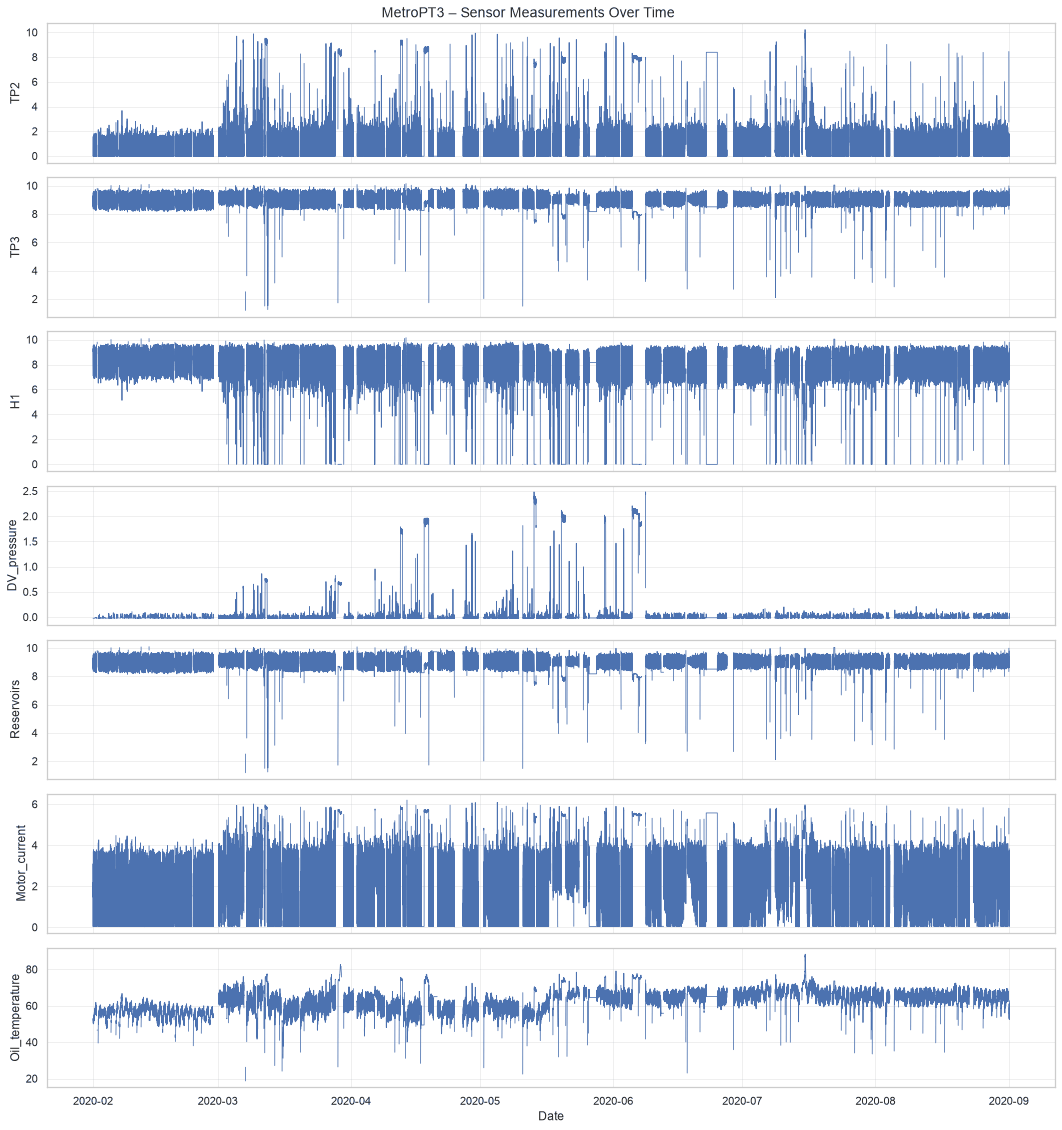

In [83]:

sensor_columns = [
    'TP2',
    'TP3',
    'H1',
    'DV_pressure',
    'Reservoirs',
    'Motor_current',
    'Oil_temperature'
]

# Aggregate sensor readings into 10-minute intervals
ts_10min = ts_df[sensor_columns].resample('10min').mean()

fig, axes = plt.subplots(
    len(sensor_columns), 1,
    figsize=(15, 16),
    sharex=True
)

for ax, sensor in zip(axes, sensor_columns):
    ax.plot(ts_10min.index, ts_10min[sensor], linewidth=0.8)
    ax.set_ylabel(sensor)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Date')
fig.suptitle('MetroPT3 – Sensor Measurements Over Time')

plt.tight_layout()
plt.show()

### 5.2 Analyzing the periods before a documented failure

In order to investigate the sensor behavior within the sensor signals, the investigation was divided between three groups:

- Group 1: Pressure and airflow
- Group 2: Compressor Operation
- Group 3: Temperature, Dryers and Safety



In [84]:
sensor_groups = {
    'Pressure and Airflow': [
        'TP2', 'TP3', 'H1', 'DV_pressure',
        'Reservoirs', 'Caudal_impulses'
    ],

    'Compressor Operation': [
        'Motor_current', 'COMP', 'DV_eletric', 'MPG'
    ],

    'Temperature, Dryers and Safety': [
        'Oil_temperature', 'Towers', 'LPS',
        'Pressure_switch', 'Oil_level'
    ]
}

print(sensor_groups)

{'Pressure and Airflow': ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Caudal_impulses'], 'Compressor Operation': ['Motor_current', 'COMP', 'DV_eletric', 'MPG'], 'Temperature, Dryers and Safety': ['Oil_temperature', 'Towers', 'LPS', 'Pressure_switch', 'Oil_level']}


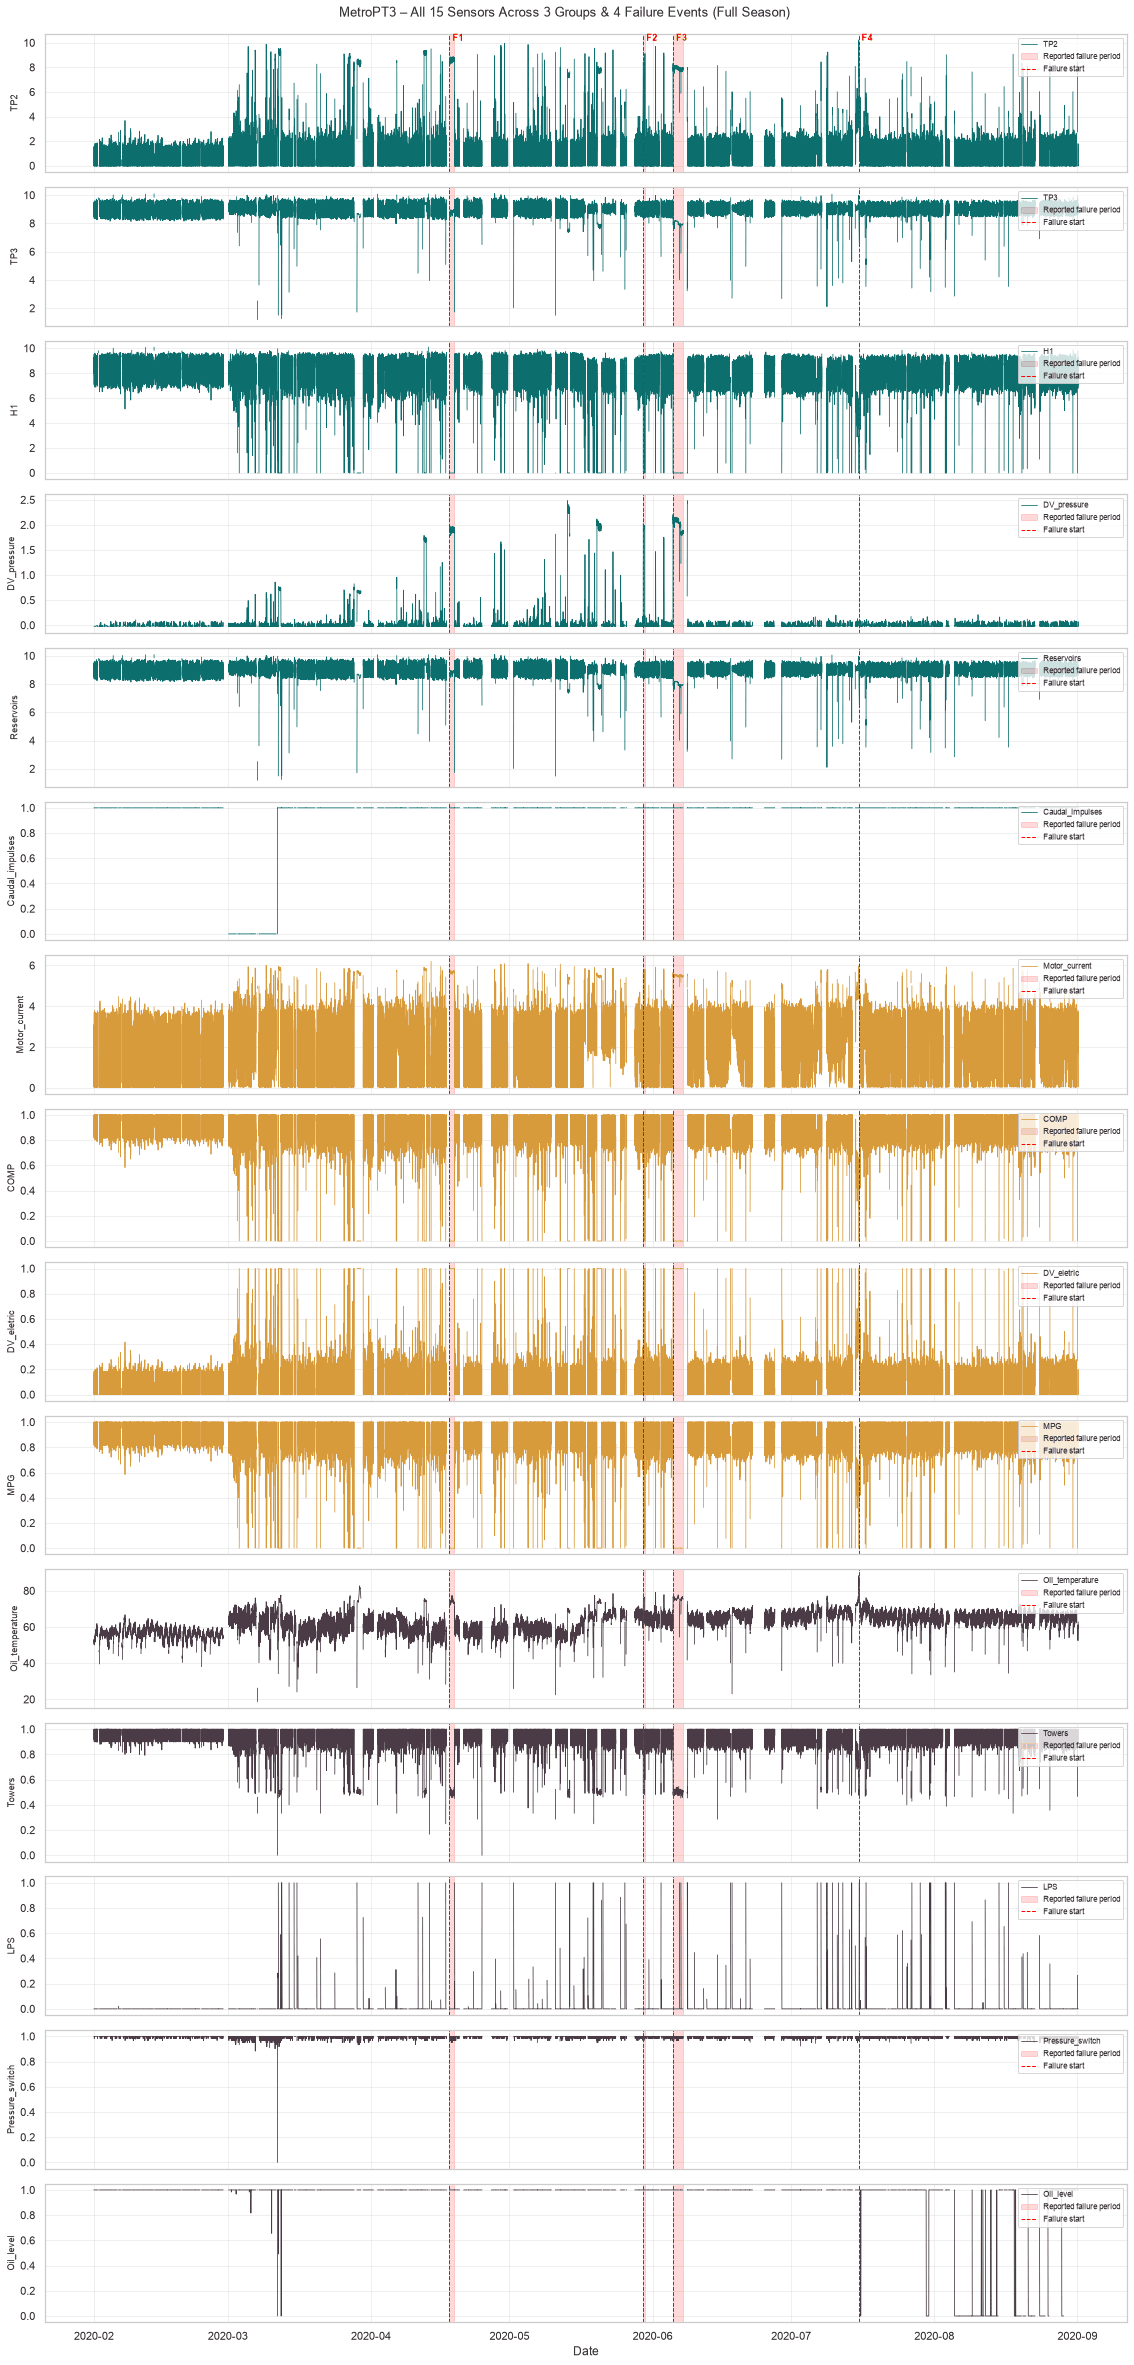

In [85]:
# Flatten all 3 sensor groups into a single ordered list (15 sensors total)
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Resample across the entire dataset (10-minute intervals for clean full-season rendering)
ts_10min = ts_clean[all_sensors].resample('10min').mean()

fig, axes = plt.subplots(
    len(all_sensors), 1,
    figsize=(16, 2.2 * len(all_sensors)),
    sharex=True,
    squeeze=False
)

# Color-code each sensor line by its physical group
group_colors = {
    'Pressure and Airflow': '#0d6e6e',
    'Compressor Operation': '#d89b3c',
    'Temperature, Dryers and Safety': '#4a3b47'
}
sensor_to_color = {
    sensor: group_colors[group]
    for group, sensors in sensor_groups.items()
    for sensor in sensors
}

for idx, (ax, sensor) in enumerate(zip(axes.flat, all_sensors)):
    ax.plot(
        ts_10min.index,
        ts_10min[sensor],
        linewidth=0.8,
        color=sensor_to_color[sensor],
        label=sensor
    )

    # Shade and mark all 4 documented failure periods
    for f_idx, event in failure_events.iterrows():
        ax.axvspan(
            event['start_time'],
            event['end_time'],
            color='red',
            alpha=0.15,
            label='Reported failure period' if f_idx == 0 else None
        )
        ax.axvline(
            event['start_time'],
            color='red',
            linestyle='--',
            linewidth=1.0,
            label='Failure start' if f_idx == 0 else None
        )
        # Label F1–F4 at the top subplot
        if idx == 0:
            ax.text(
                event['start_time'],
                ax.get_ylim()[1],
                f" F{int(event['failure_id'])}",
                color='red',
                fontweight='bold',
                va='top',
                ha='left',
                fontsize=9
            )

    ax.set_ylabel(sensor, fontsize=9)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(alpha=0.3)

axes[-1, 0].set_xlabel('Date')
fig.suptitle('MetroPT3 – All 15 Sensors Across 3 Groups & 4 Failure Events (Full Season)', y=0.995, fontsize=13)
plt.tight_layout()
plt.show()

In [86]:
import matplotlib.dates as mdates

def plot_kpi_diagnostic(ts_df, failure_events, failure_id, sensors, title, hours_before=36, hours_after=4):
    event = failure_events.loc[failure_events['failure_id'] == failure_id].iloc[0]
    f_start, f_end = event['start_time'], event['end_time']
    kpi_deadline = f_start - pd.Timedelta(hours=2)
    
    subset = ts_df.loc[f_start - pd.Timedelta(hours=hours_before) : f_end + pd.Timedelta(hours=hours_after), sensors]
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(len(sensors), 1, figsize=(13, 2.3 * len(sensors)), sharex=True, squeeze=False)
    
    for idx, (ax, sensor) in enumerate(zip(axes.flat, sensors)):
        ax.plot(subset_plot.index, subset_plot[sensor], color='#162432', linewidth=1.0, label='1-min median signal')
        
        # 1. Shade the critical 2-hour KPI window before failure
        ax.axvspan(kpi_deadline, f_start, color='#d89b3c', alpha=0.22, label='2h Business KPI Window')
        ax.axvline(kpi_deadline, color='#d89b3c', linestyle='-.', linewidth=1.4, label='-2h KPI Deadline')
        
        # 2. Shade the reported failure window
        ax.axvspan(f_start, f_end, color='#c94a4a', alpha=0.16, label='Reported Failure')
        ax.axvline(f_start, color='#c94a4a', linestyle='--', linewidth=1.4, label='Failure Start')
        
        ax.set_ylabel(sensor, fontsize=10, fontweight='bold', color='#162432')
        ax.grid(alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)

    # Single clean legend at the top of the figure
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.96), ncol=5, frameon=False, fontsize=9)
    
    axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%b %d\n%H:%M'))
    axes[-1, 0].set_xlabel('Timestamp (UTC)', fontsize=10)
    fig.suptitle(title, y=0.995, fontsize=12, fontweight='bold', color='#162432')
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

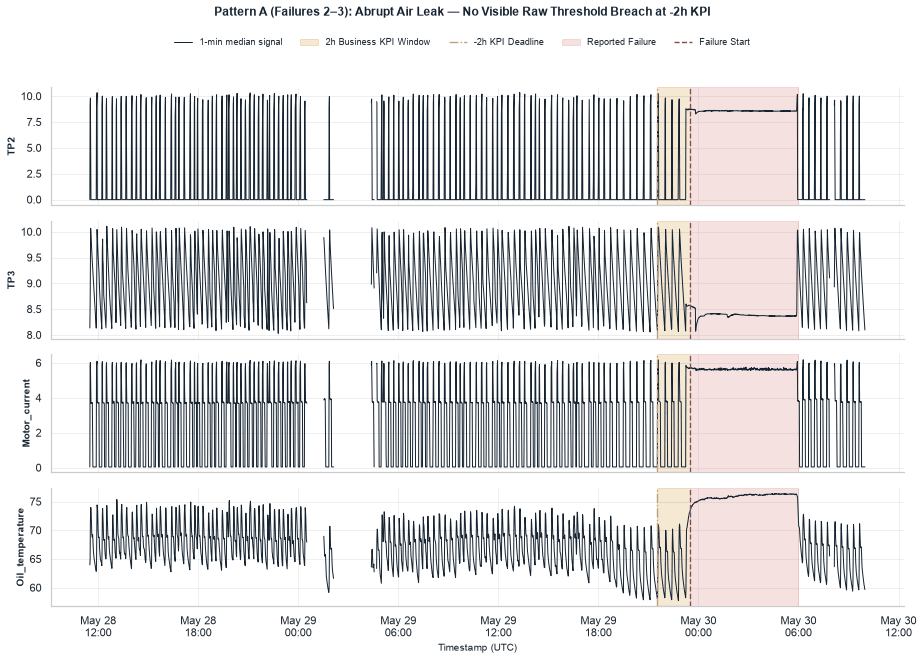

In [87]:
# Representative Abrupt Air Leak (Failure 2: May 29–30)
abrupt_sensors = ['TP2', 'TP3', 'Motor_current', 'Oil_temperature']

plot_kpi_diagnostic(
    ts_clean,
    failure_events,
    failure_id=2,
    sensors=abrupt_sensors,
    title= 'Pattern A (Failures 2–3): Abrupt Air Leak — No Visible Raw Threshold Breach at -2h KPI')

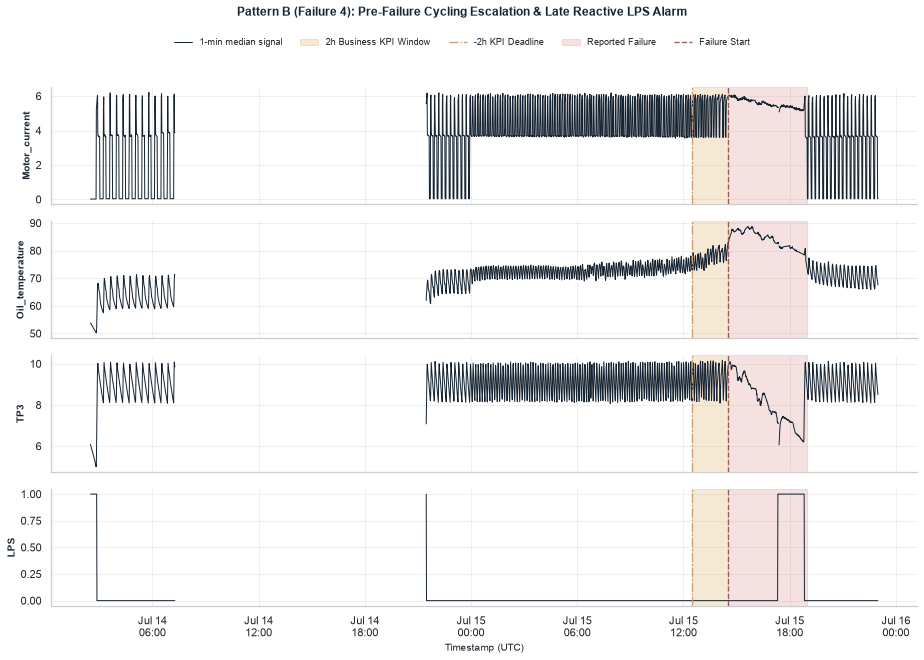

In [88]:
# Gradual Escalation Air Leak (Failure 4: July 15)
gradual_sensors = ['Motor_current', 'Oil_temperature', 'TP3', 'LPS']

plot_kpi_diagnostic(
    ts_clean,
    failure_events,
    failure_id=4,
    sensors=gradual_sensors,
    title='Pattern B (Failure 4): Pre-Failure Cycling Escalation & Late Reactive LPS Alarm'
)

#### 5.2.1 Identifying pattern Failure 1

##### 5.2.1.1 Sensor analysis group 1: Pressure and Airflow

In [89]:

def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Pressure and Airflow']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

        

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()


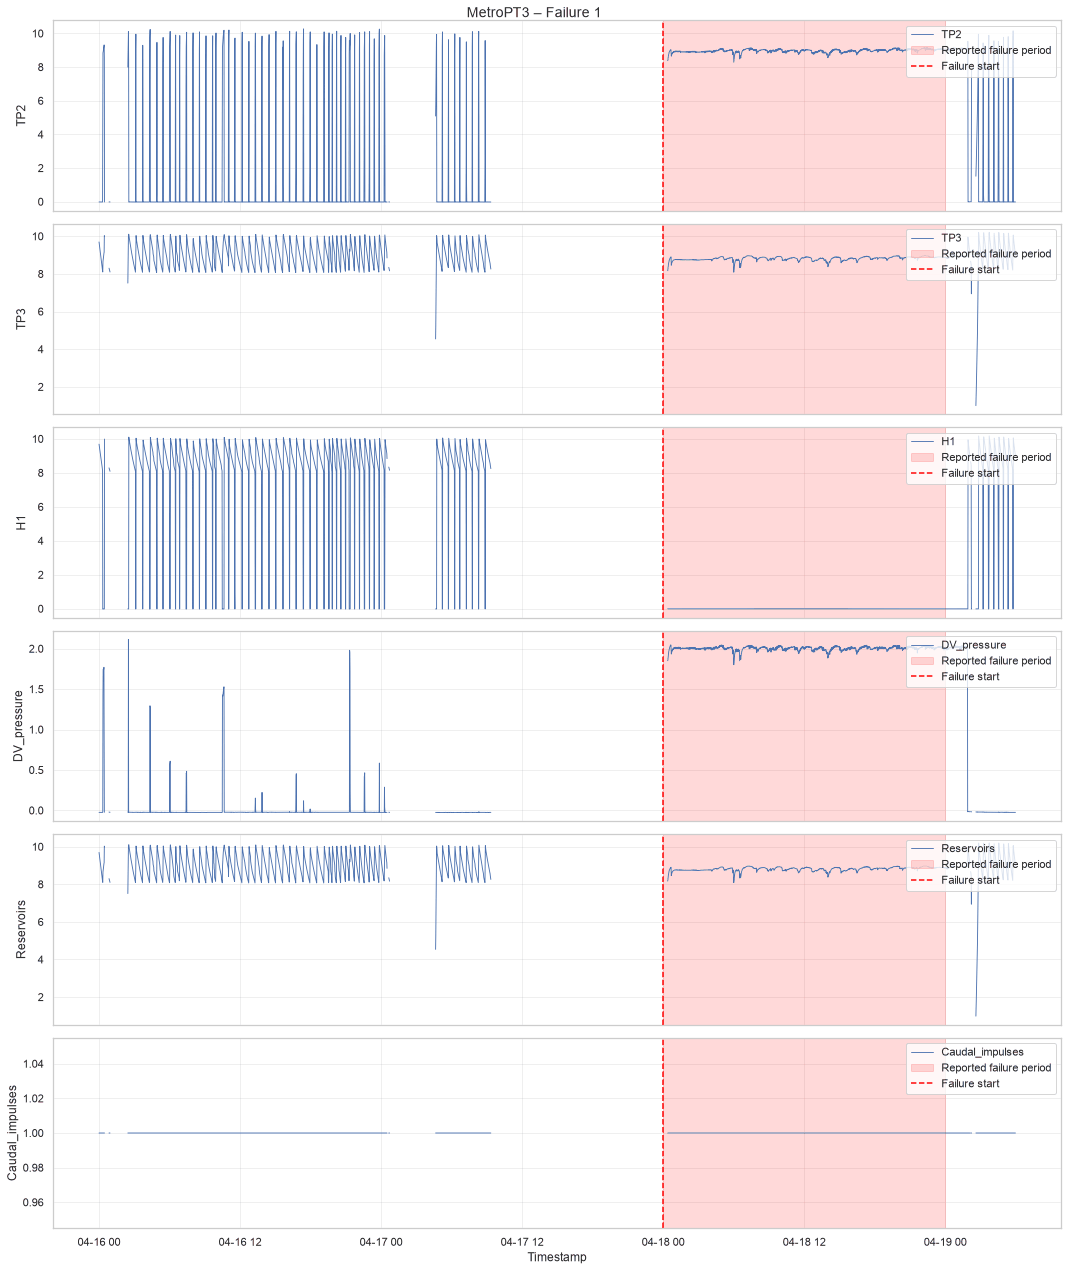

In [90]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=1,
    hours_before=48,
    hours_after=6
)

##### 5.2.1.2 Sensor analysis group 2: Compressor Operation

In [91]:

def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Compressor Operation']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()


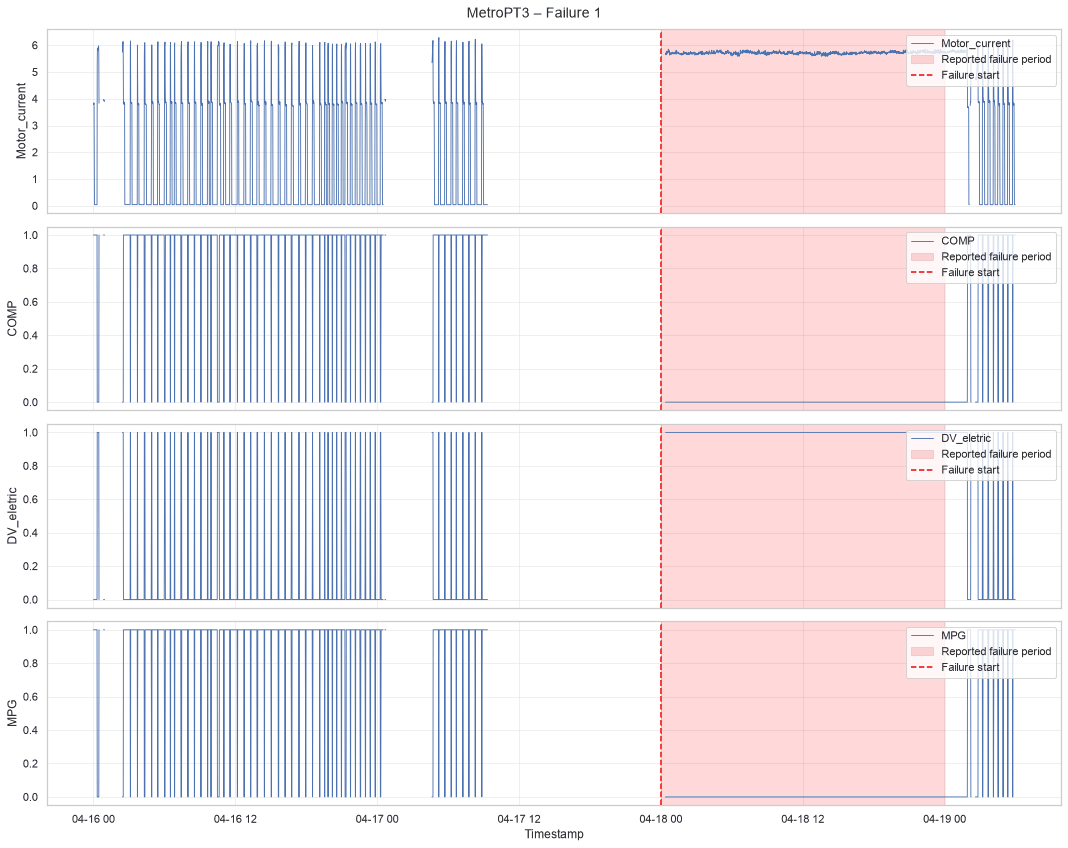

In [92]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=1,
    hours_before=48,
    hours_after=6
)

##### 5.2.1.3 Sensor analysis group 3: Temperature, Dryers and Safety

In [93]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Temperature, Dryers and Safety']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()


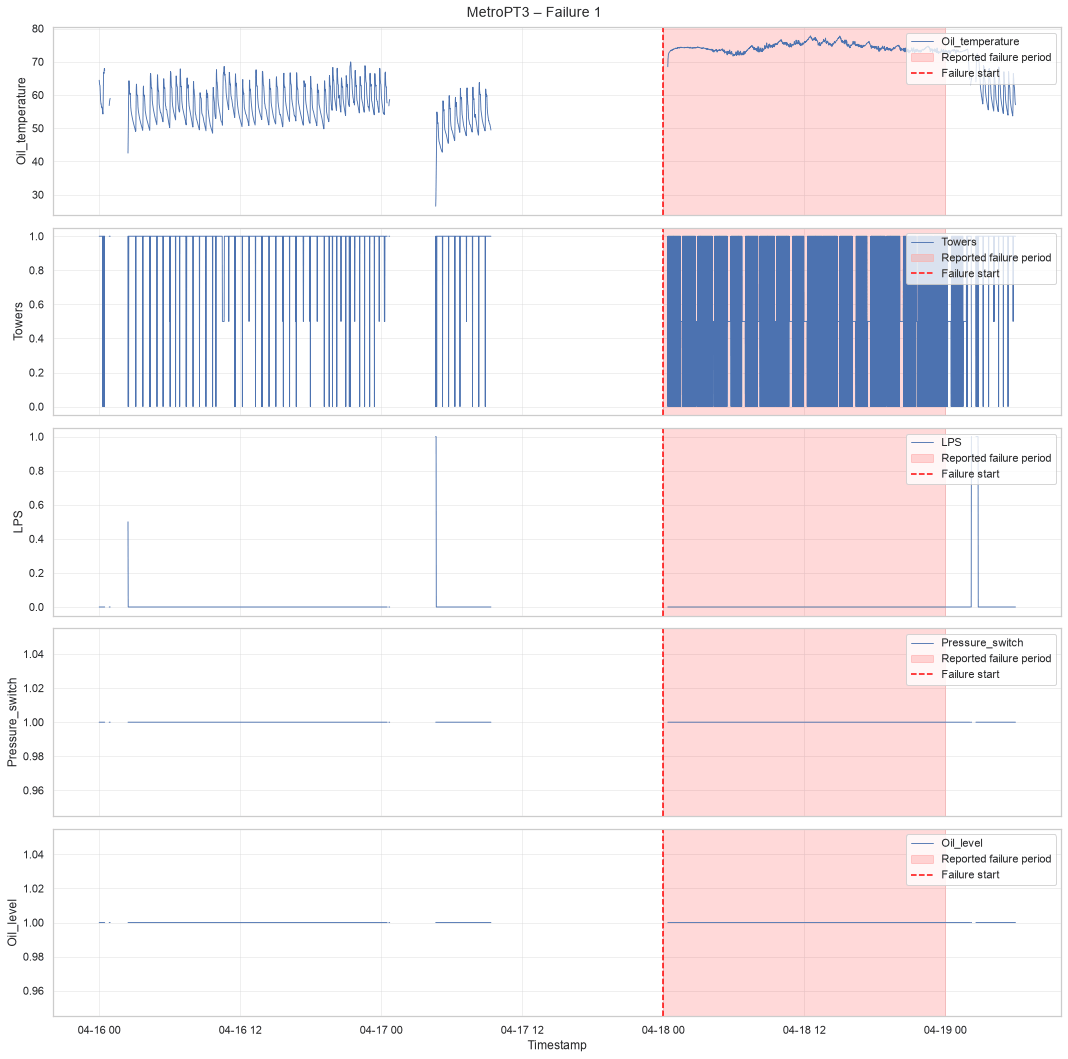

In [94]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=1,
    hours_before=48,
    hours_after=6
)

##### 5.2.1.4 Examining sensor behavior across three periods

In [95]:

event = failure_events.loc[
    failure_events['failure_id'] == 1
].iloc[0]

t = event['start_time']

# Define periods without overlapping timestamps
periods = {
    '48–24h before': ts_clean.loc[
        (ts_clean.index >= t - pd.Timedelta(hours=48)) &
        (ts_clean.index < t - pd.Timedelta(hours=24))
    ],
    '24–0h before': ts_clean.loc[
        (ts_clean.index >= t - pd.Timedelta(hours=24)) &
        (ts_clean.index < t)
    ],
    'During failure': ts_clean.loc[
        (ts_clean.index >= t) &
        (ts_clean.index <= event['end_time'])
    ]
}

# Get all sensors from the existing sensor_groups dictionary
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Calculate mean for each sensor in each period
results = []

for name, data in periods.items():
    row = {'Period': name}

    for sensor in all_sensors:
        row[sensor] = data[sensor].mean()

    results.append(row)

comparison = pd.DataFrame(results).set_index('Period')

display(comparison.round(2))

,TP2,TP3,H1,DV_pressure,Reservoirs,Caudal_impulses,Motor_current,COMP,DV_eletric,MPG,Oil_temperature,Towers,LPS,Pressure_switch,Oil_level
Period,,,,,,,,,,,,,,,
48–24h before,0.85,9.01,8.11,0.01,9.01,1.0,1.49,0.90,0.10,0.90,57.31,0.95,0.00,1.00,1.0
24–0h before,0.68,8.97,8.27,-0.02,8.97,1.0,1.39,0.92,0.08,0.92,52.73,0.96,0.01,1.00,1.0
During failure,8.61,8.82,-0.01,1.90,8.82,1.0,5.66,0.00,1.00,0.00,74.39,0.50,0.00,0.99,1.0


##### 5.2.1.5 Conclusion Failure 1

- **During the failure** the compressor stays in continuous loaded operation for the whole reported window: Motor_current is flat at about 5.7 A, COMP and MPG drop to 0, DV_eletric stays at 1, TP2 rises to about 8.6 bar, H1 falls to about 0 and Oil_temperature rises to about 74 °C. Towers averages 0.5, meaning both drying towers alternate.
- **Before the failure** no gradual degradation is visible. The compressor cycles normally on 16 April. From 09:20 on 17 April until the failure starts at 00:00 on 18 April the sensors are frozen (logger fault, see 3.4.6): they repeat Motor_current ≈ 0.04 A and Oil_temperature ≈ 49 °C, which looks like an idle compressor but is not real data. With these readings excluded, the remaining 24–0h means are close to the 48–24h period (Motor_current 1.39 vs 1.49 A); Oil_temperature is somewhat lower (52.7 vs 57.3 °C).
- There is a data gap in the early hours of 17 April.
- **Early-warning potential:** low at this resolution. The failure appears as a sudden switch to continuous load, and the frozen period leaves no usable data in the last 15 hours before it.

#### 5.2.2 Identifying pattern Failure 2

##### 5.2.2.1 Sensor analysis group 1: Pressure and Airflow

In [96]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Pressure and Airflow']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

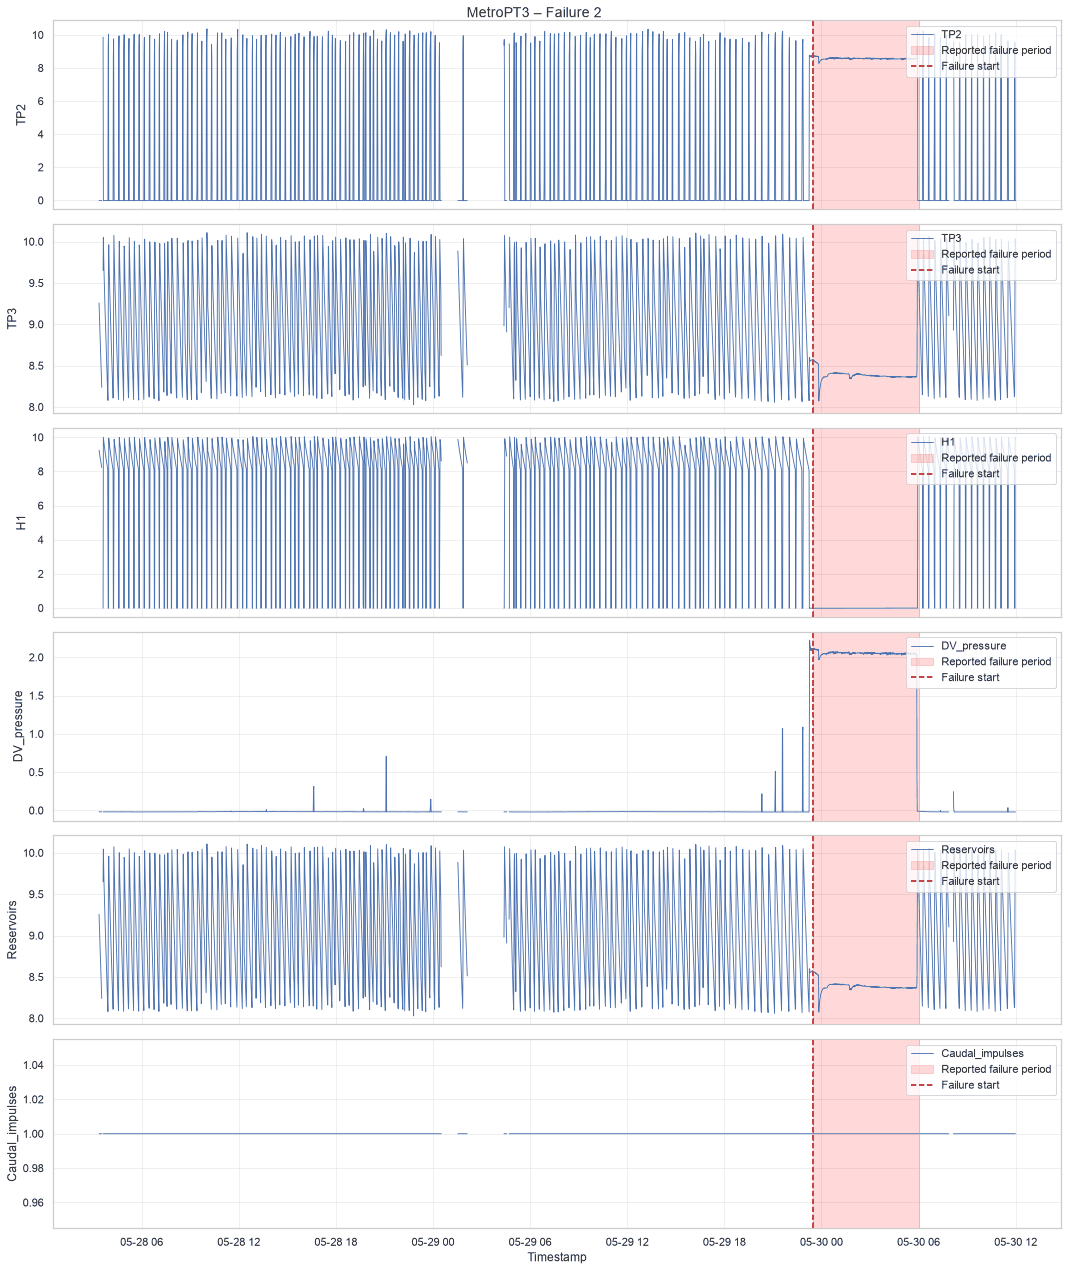

In [97]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=2,
    hours_before=48,
    hours_after=6
)

##### 5.2.2.2 Sensor analysis group 2: Compressor Operation

In [98]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Compressor Operation']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

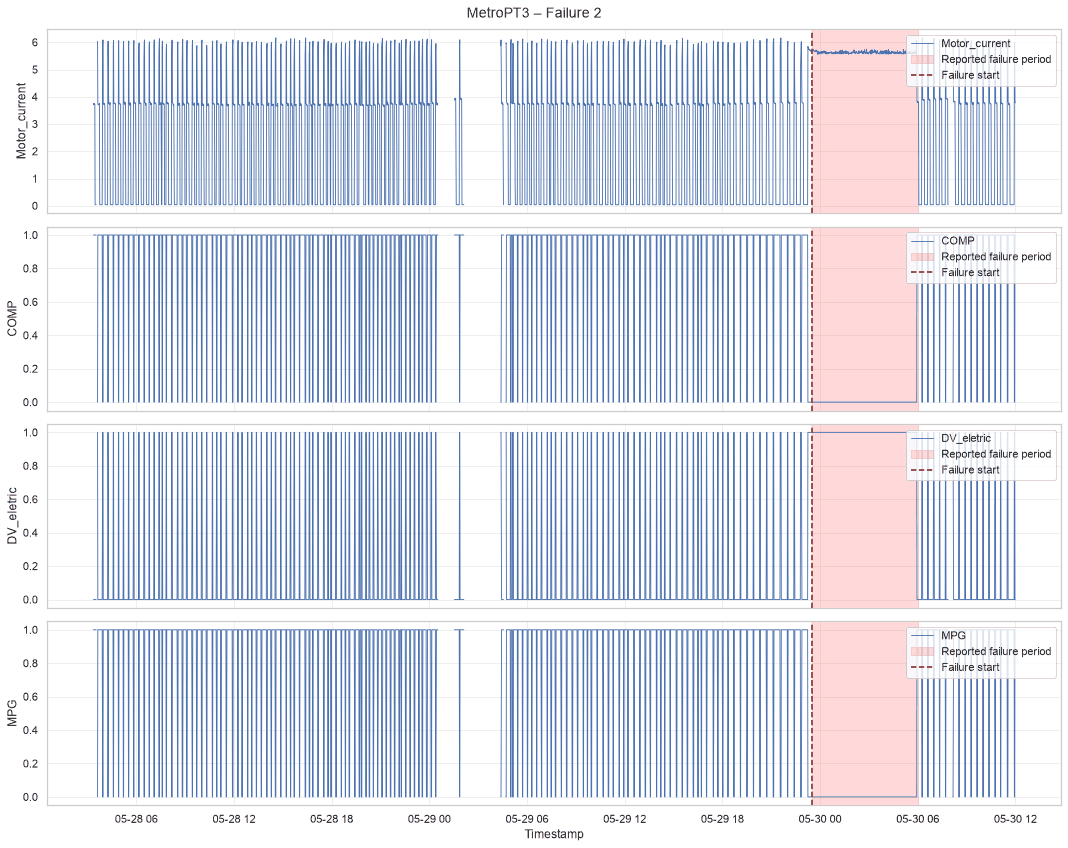

In [99]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=2,
    hours_before=48,
    hours_after=6
)

##### 5.2.2.3 Sensor analysis group 3: Temperature, Dryers and Safety

In [100]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Temperature, Dryers and Safety']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

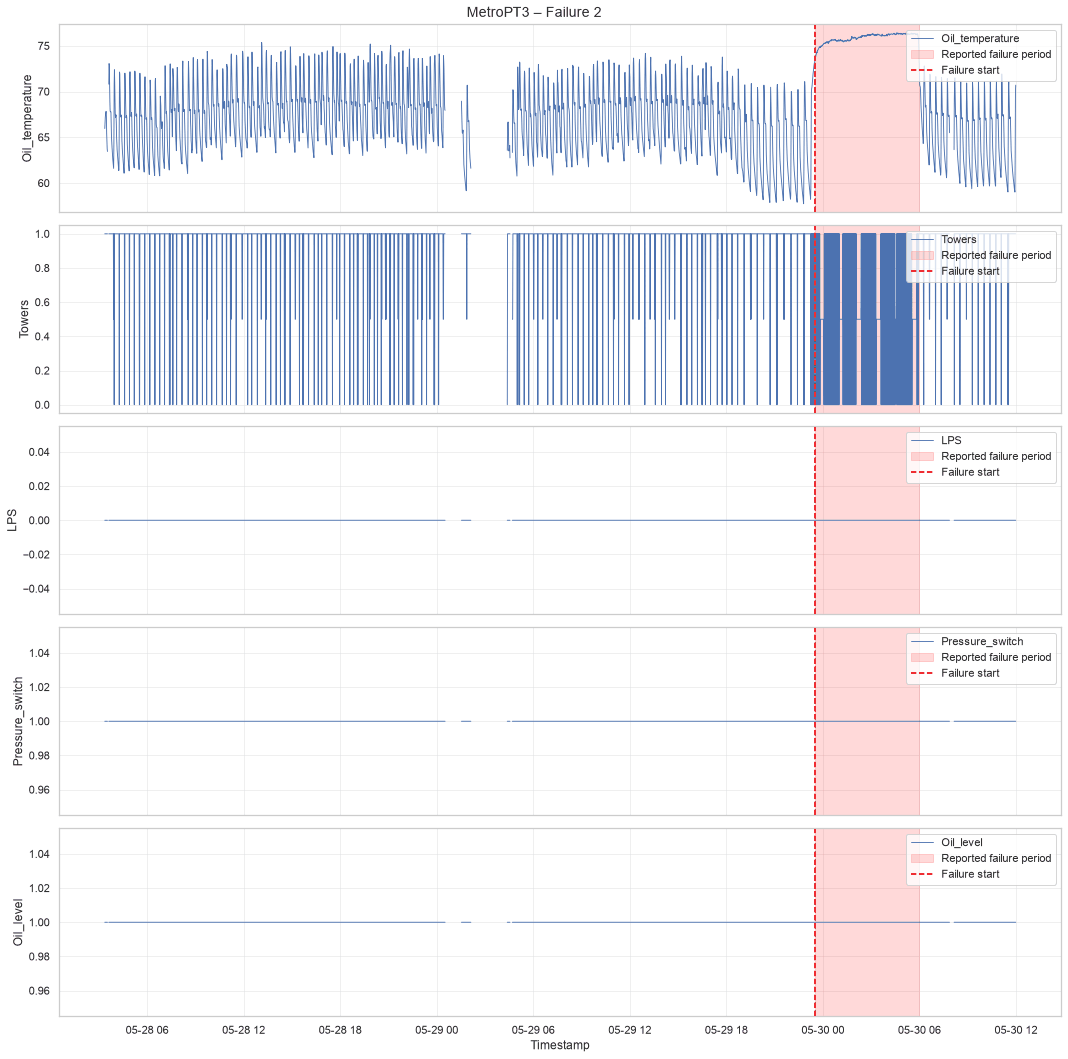

In [101]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=2,
    hours_before=48,
    hours_after=6
)

##### 5.2.2.4 Examining sensor behavior across three periods

In [102]:
event = failure_events.loc[
    failure_events['failure_id'] == 2
].iloc[0]

t = event['start_time']

# Define periods without overlapping timestamps
periods = {
    '48–24h before': ts_clean.loc[
        (ts_clean.index >= t - pd.Timedelta(hours=48)) &
        (ts_clean.index < t - pd.Timedelta(hours=24))
    ],
    '24–0h before': ts_clean.loc[
        (ts_clean.index >= t - pd.Timedelta(hours=24)) &
        (ts_clean.index < t)
    ],
    'During failure': ts_clean.loc[
        (ts_clean.index >= t) &
        (ts_clean.index <= event['end_time'])
    ]
}

# Get all sensors from the existing sensor_groups dictionary
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Calculate mean for each sensor in each period
results = []

for name, data in periods.items():
    row = {'Period': name}

    for sensor in all_sensors:
        row[sensor] = data[sensor].mean()

    results.append(row)

comparison = pd.DataFrame(results).set_index('Period')

display(comparison.round(2))

,TP2,TP3,H1,DV_pressure,Reservoirs,Caudal_impulses,Motor_current,COMP,DV_eletric,MPG,Oil_temperature,Towers,LPS,Pressure_switch,Oil_level
Period,,,,,,,,,,,,,,,
48–24h before,1.30,9.03,7.71,-0.01,9.03,1.0,2.35,0.86,0.14,0.86,67.68,0.93,0.0,1.0,1.0
24–0h before,1.24,9.02,7.75,0.01,9.02,1.0,2.13,0.86,0.14,0.86,66.25,0.93,0.0,1.0,1.0
During failure,8.18,8.40,0.07,1.92,8.40,1.0,5.57,0.01,0.99,0.01,75.87,0.50,0.0,1.0,1.0


##### 5.2.2.5 Conclusion Failure 2

- **During the failure** the same signature as in Failure 1 appears: continuous loaded operation (Motor_current about 5.6 A, COMP/MPG = 0, DV_eletric = 1), TP2 about 8.2 bar, H1 about 0, Oil_temperature about 76 °C. TP3 and Reservoirs drop to about 8.4 bar on average.
- **Before the failure** the compressor cycles normally right up to the failure start. The 48–24h and 24–0h periods are almost identical (Motor_current 2.35 vs 2.13 A, Oil_temperature 67.7 vs 66.3 °C).
- There is a data gap in the early hours of 29 May.
- **Early-warning potential:** low at this resolution. No shift is visible in the 24-hour means or in the plots.

#### 5.2.3 Identifying pattern Failure 3

##### 5.2.3.1 Sensor analysis group 1: Pressure and Airflow

In [103]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Pressure and Airflow']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

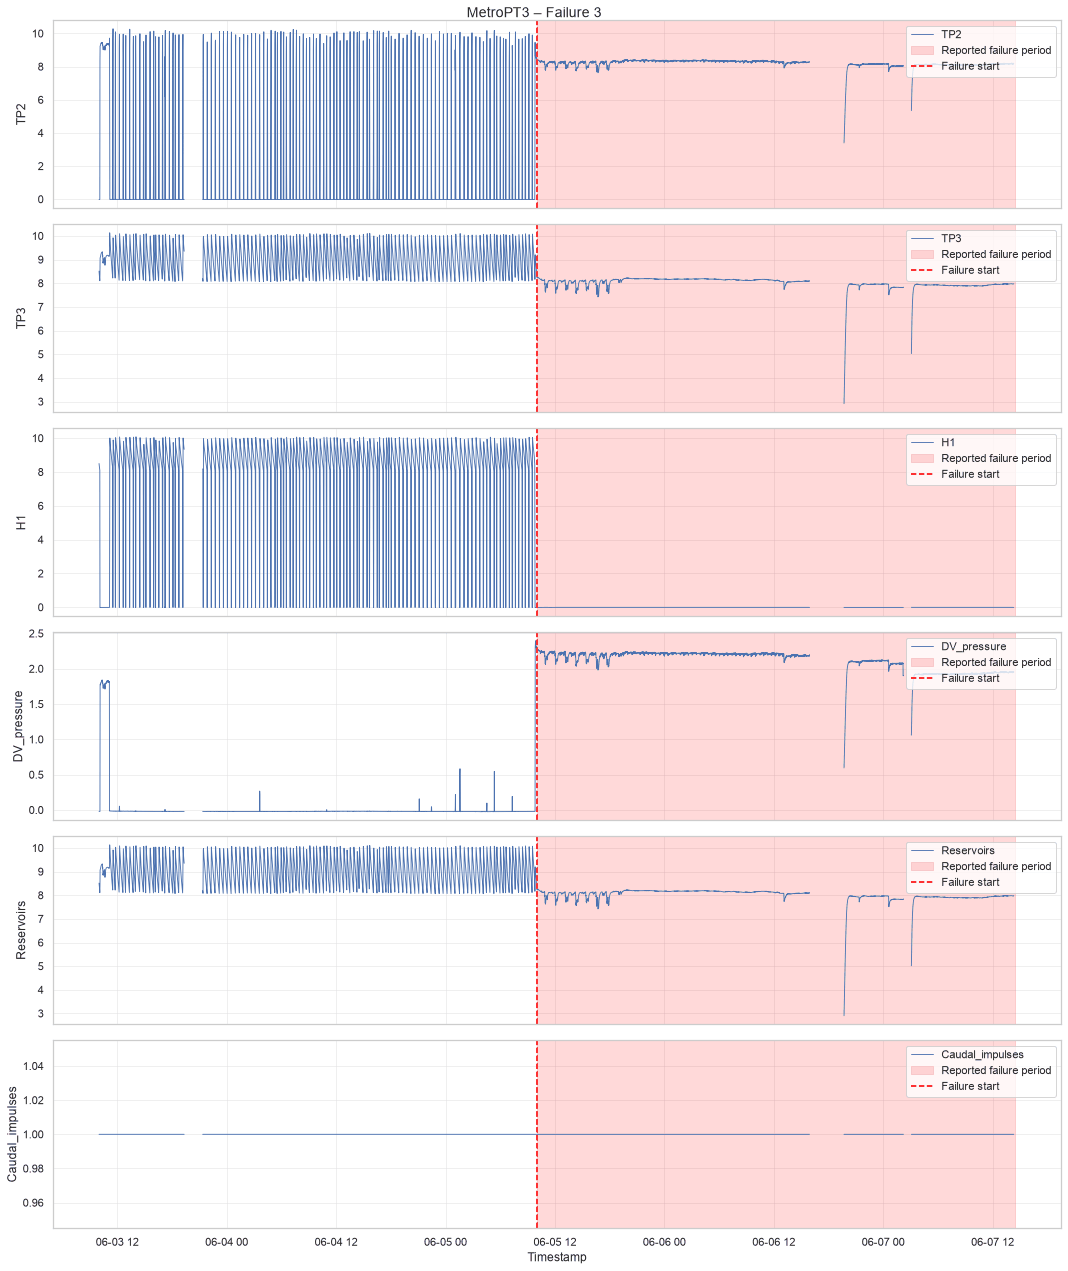

In [104]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=3,
    hours_before=48,
    hours_after=6
)

##### 5.2.3.2 Sensor analysis group 2: Compressor Operation

In [105]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Compressor Operation']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

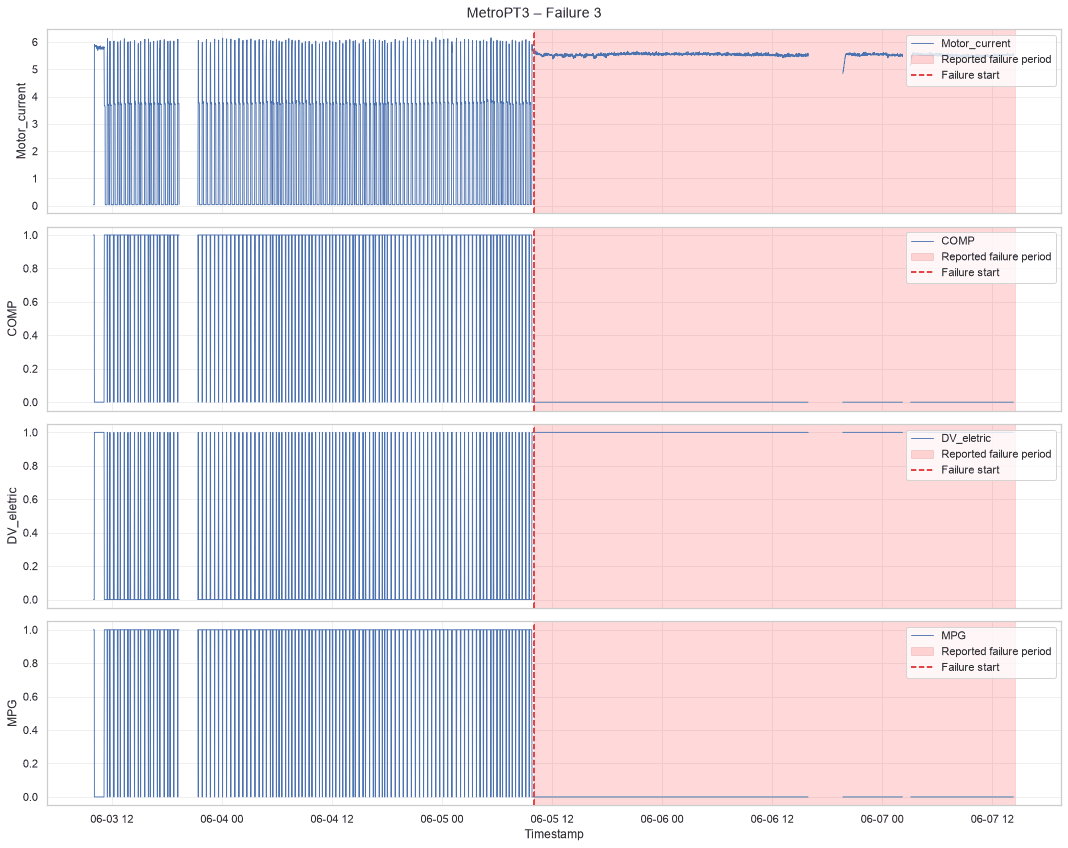

In [106]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=3,
    hours_before=48,
    hours_after=6
)

##### 5.2.3.3 Sensor analysis group 3: Temperature, Dryers and Safety

In [107]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Temperature, Dryers and Safety']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

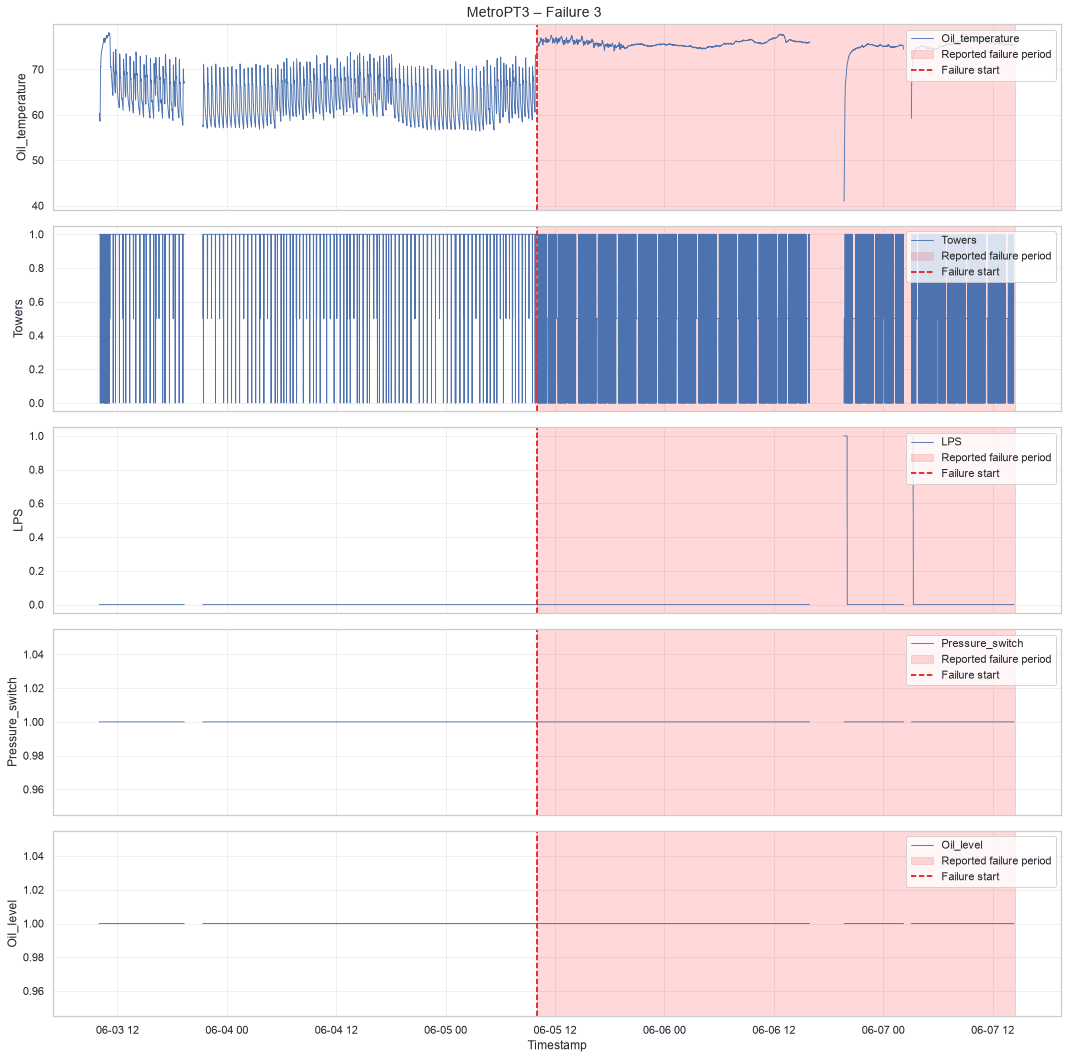

In [108]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=3,
    hours_before=48,
    hours_after=6
)

##### 5.2.3.4 Examining sensor behavior across three periods

In [109]:
event = failure_events.loc[
    failure_events['failure_id'] == 3
].iloc[0]

t = event['start_time']

# Define periods without overlapping timestamps
periods = {
    '48–24h before': ts_clean.loc[
        (ts_clean.index >= t - pd.Timedelta(hours=48)) &
        (ts_clean.index < t - pd.Timedelta(hours=24))
    ],
    '24–0h before': ts_clean.loc[
        (ts_clean.index >= t - pd.Timedelta(hours=24)) &
        (ts_clean.index < t)
    ],
    'During failure': ts_clean.loc[
        (ts_clean.index >= t) &
        (ts_clean.index <= event['end_time'])
    ]
}

# Get all sensors from the existing sensor_groups dictionary
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Calculate mean for each sensor in each period
results = []

for name, data in periods.items():
    row = {'Period': name}

    for sensor in all_sensors:
        row[sensor] = data[sensor].mean()

    results.append(row)

comparison = pd.DataFrame(results).set_index('Period')

display(comparison.round(2))

,TP2,TP3,H1,DV_pressure,Reservoirs,Caudal_impulses,Motor_current,COMP,DV_eletric,MPG,Oil_temperature,Towers,LPS,Pressure_switch,Oil_level
Period,,,,,,,,,,,,,,,
48–24h before,1.33,9.01,7.64,0.07,9.01,1.0,1.97,0.85,0.15,0.85,64.71,0.93,0.00,1.0,1.0
24–0h before,0.99,9.02,7.97,0.00,9.02,1.0,1.78,0.89,0.11,0.89,63.83,0.94,0.00,1.0,1.0
During failure,7.89,8.02,-0.01,2.02,8.02,1.0,5.49,0.00,1.00,0.00,75.52,0.50,0.01,1.0,1.0


##### 5.2.3.5 Conclusion Failure 3

- **During the failure** the compressor again runs continuously under load, this time for the longest window (52.5 h): Motor_current about 5.5 A, COMP/MPG = 0, DV_eletric = 1, TP2 about 7.9 bar, H1 about 0, Oil_temperature about 75.5 °C. TP3 and Reservoirs show the largest average drop of Failures 1–3 (about 9.0 → 8.0 bar).
- **Before the failure** the compressor cycles normally until about 10:00 on 5 June. The differences between the two pre-failure periods are small (Motor_current 1.97 vs 1.78 A, Oil_temperature 64.7 vs 63.8 °C).
- There is a data gap inside the failure window, on the afternoon and evening of 6 June.
- **Early-warning potential:** low at this resolution. The onset is abrupt.

#### 5.2.4 Identifying pattern Failure 4

##### 5.2.4.1 Sensor analysis group 1: Pressure and Airflow

In [110]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Pressure and Airflow']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

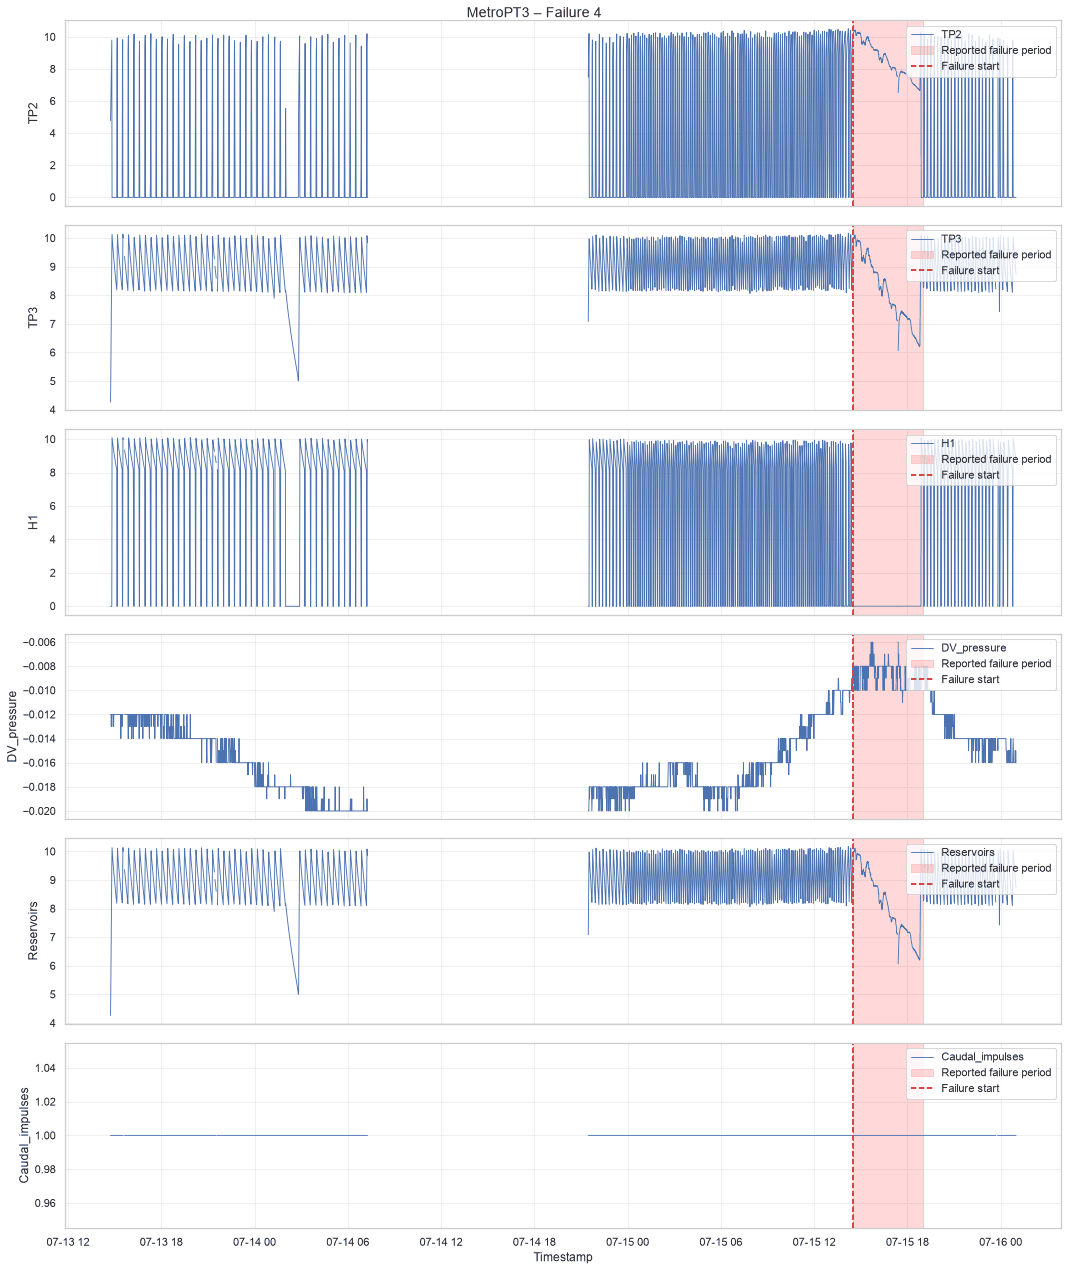

In [111]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=4,
    hours_before=48,
    hours_after=6
)

##### 5.2.4.2 Sensor analysis group 2: Compressor Operation

In [112]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Compressor Operation']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

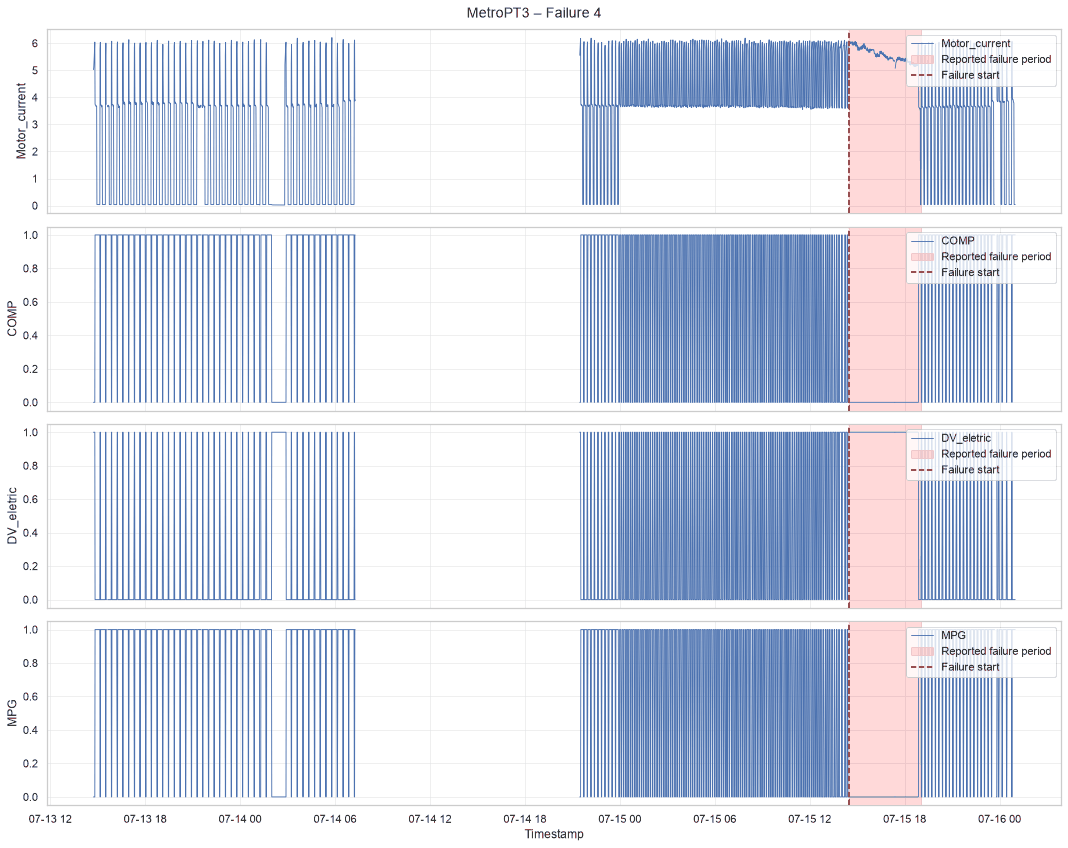

In [113]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=4,
    hours_before=48,
    hours_after=6
)

##### 5.2.4.3 Sensor analysis group 3: Temperature, Dryers and Safety

In [114]:
def plot_failure_window(
    ts_df,
    failure_events,
    failure_id,
    hours_before=48,
    hours_after=6,
    sensors=None
):
    if sensors is None:
        sensors = sensor_groups['Temperature, Dryers and Safety']

    event = failure_events.loc[
        failure_events['failure_id'] == failure_id
    ].iloc[0]

    failure_start = event['start_time']
    failure_end = event['end_time']

    window_start = failure_start - pd.Timedelta(hours=hours_before)
    window_end = failure_end + pd.Timedelta(hours=hours_after)

    subset = ts_df.loc[window_start:window_end, sensors]

    # 1-minute medians for a readable overview
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(
        len(sensors), 1,
        figsize=(15, 3 * len(sensors)),
        sharex=True,
        squeeze=False
    )

    for ax, sensor in zip(axes.flat, sensors):
        ax.plot(
            subset_plot.index,
            subset_plot[sensor],
            linewidth=0.9,
            label=sensor
        )

        ax.axvspan(
            failure_start,
            failure_end,
            color='red',
            alpha=0.15,
            label='Reported failure period'
        )

        ax.axvline(
            failure_start,
            color='red',
            linestyle='--',
            label='Failure start'
        )

        ax.set_ylabel(sensor)
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel('Timestamp')
    fig.suptitle(f'MetroPT3 – Failure {failure_id}')
    plt.tight_layout()
    plt.show()

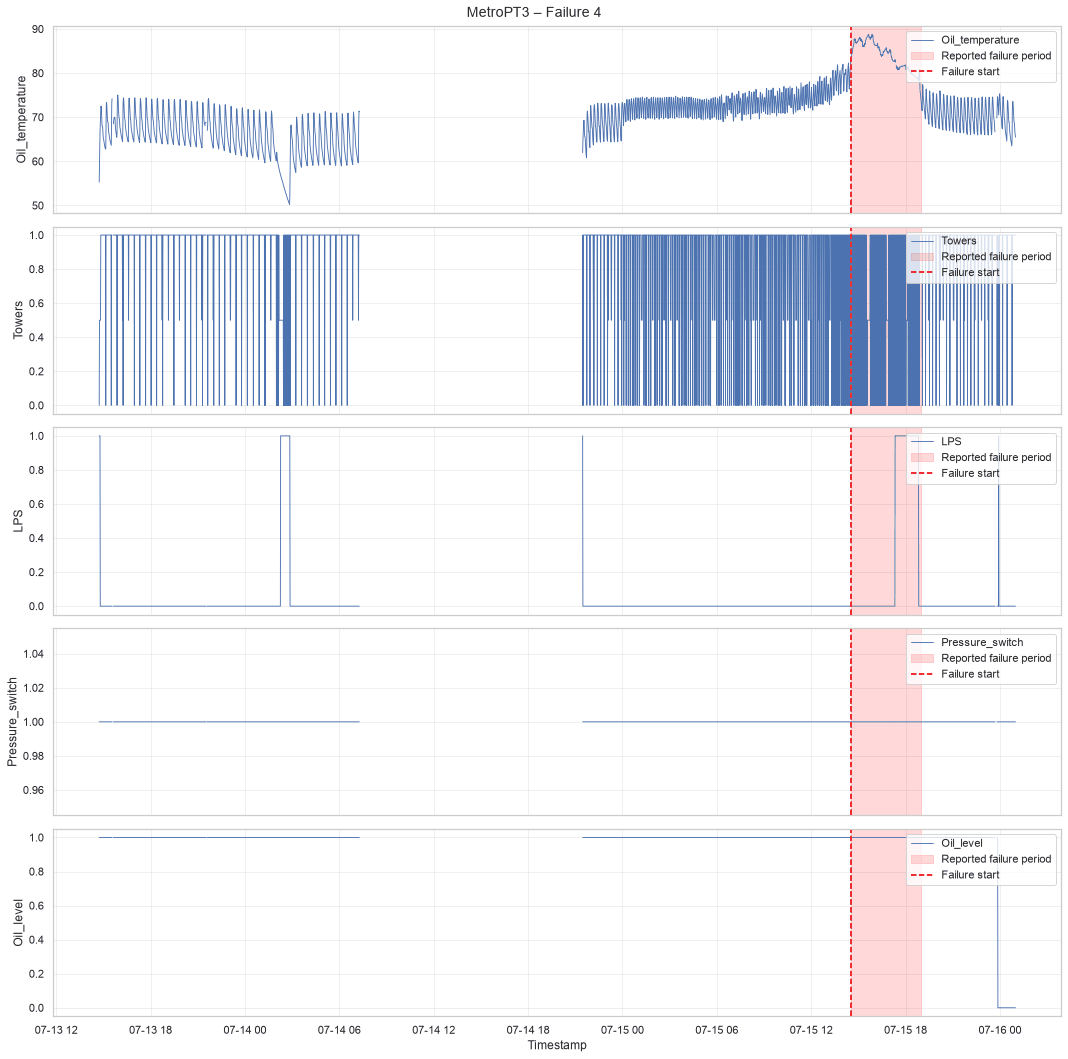

In [115]:
plot_failure_window(
    ts_clean,
    failure_events,
    failure_id=4,
    hours_before=48,
    hours_after=6
)

##### 5.2.4.4 Examining sensor behavior across three periods

In [116]:
event = failure_events.loc[
    failure_events['failure_id'] == 4
].iloc[0]

t = event['start_time']

# Define periods without overlapping timestamps
periods = {
    '48–24h before': ts_clean.loc[
        (ts_clean.index >= t - pd.Timedelta(hours=48)) &
        (ts_clean.index < t - pd.Timedelta(hours=24))
    ],
    '24–0h before': ts_clean.loc[
        (ts_clean.index >= t - pd.Timedelta(hours=24)) &
        (ts_clean.index < t)
    ],
    'During failure': ts_clean.loc[
        (ts_clean.index >= t) &
        (ts_clean.index <= event['end_time'])
    ]
}

# Get all sensors from the existing sensor_groups dictionary
all_sensors = [
    sensor
    for sensors in sensor_groups.values()
    for sensor in sensors
]

# Calculate mean for each sensor in each period
results = []

for name, data in periods.items():
    row = {'Period': name}

    for sensor in all_sensors:
        row[sensor] = data[sensor].mean()

    results.append(row)

comparison = pd.DataFrame(results).set_index('Period')

display(comparison.round(2))

,TP2,TP3,H1,DV_pressure,Reservoirs,Caudal_impulses,Motor_current,COMP,DV_eletric,MPG,Oil_temperature,Towers,LPS,Pressure_switch,Oil_level
Period,,,,,,,,,,,,,,,
48–24h before,0.95,8.88,7.57,-0.01,8.88,1.0,1.80,0.84,0.16,0.84,65.59,0.92,0.04,1.0,1.0
24–0h before,3.62,9.11,5.49,-0.00,9.11,1.0,4.37,0.61,0.39,0.61,72.79,0.80,0.00,1.0,1.0
During failure,8.27,8.21,0.25,-0.01,8.21,1.0,5.51,0.03,0.97,0.03,83.91,0.51,0.33,1.0,1.0


##### 5.2.4.5 Conclusion Failure 4

- **During the failure** the compressor runs continuously under load (Motor_current about 5.5 A, COMP/MPG close to 0, DV_eletric close to 1), and the pressure cannot be maintained: TP3 and Reservoirs fall steadily from about 10 to about 6.2 bar, and LPS (pressure < 7 bar) is active 33 % of the time. Oil_temperature reaches about 84 °C, the highest of all four failures. Failure 4 is therefore the most severe event.
- **Before the failure**, unlike Failures 1–3, there is a clear precursor. In the 24 h before the failure the compressor switches on much more often than in the 48–24h period: Motor_current 1.80 → 4.37 A, DV_eletric 0.16 → 0.39, TP2 0.95 → 3.62 bar, Oil_temperature 65.6 → 72.8 °C. This fits an air leak: the pressure drops faster, so the compressor has to reload more frequently. The plots show that from about 00:00 on 15 July (around 14 h before the failure) the motor no longer switches off between load cycles (it stays offloaded at about 3.7 A), and Oil_temperature rises steadily from about 72 to about 80 °C.
- There is a long data gap on 14 July (about 07:00 to 22:00) and a sharp pressure drop in the early hours of 14 July.
- **Early-warning potential:** high. The rising load-cycle frequency is visible many hours before the reported failure start.

### 5.3 Overall conclusion: sensor behavior around the failures

- **Common failure signature:** in all four failures the compressor leaves its normal on/off cycling and stays in continuous loaded operation (Motor_current about 5.5 A, COMP = MPG = 0, DV_eletric = 1, H1 about 0, TP2 about 8 bar, Oil_temperature 74–84 °C), while TP3/Reservoirs pressure drops. This fits an air leak: the compressor runs constantly but cannot hold the pressure.
- **Precursors:** only Failure 4 shows a clear change before the failure window (more frequent load cycles, higher mean Motor_current and Oil_temperature in the 24 h before). Failures 1–3 start abruptly when viewed with 24-hour means and 1-minute plots.
- **Implication for early warning:** detecting the failure window itself is easy, but this is detection, not early warning. For early warning, the next step is to derive features that describe the duty cycle, such as load cycles per hour, share of time under load, and pressure-decay rate during off phases. These may reveal slower degradation that 24-hour means average out.
- **Data gaps** occur shortly before several failures and must be handled when lead times are evaluated.

In [117]:
signal_cols = analog_columns + digital_columns
ts_clean_no_frozen = ts_df.copy()
ts_clean_no_frozen[signal_cols] = ts_clean_no_frozen[signal_cols].astype("float64").mask(ts_clean_no_frozen["sensors_frozen"].eq(1), axis=0)

# exlcude all frozen rows from original df to get the analysis of only the data that will be used for feature engineering
# and model training

**Failure Event Pattern analysis - after data cleaning (excluding frozen rows)**

- **Only filters for frozen rows. In the following failure pattern analysis, the frozen rows are removed, leaving blank gaps in the timeline.**
- **The recording gaps are not accounted for yet using segmentation.**
- **This means any broken lines in the plot could be from either the removed frozen sensor readings or the recording gaps**
- **In the plot below, blank = frozen sensors or recording gap**

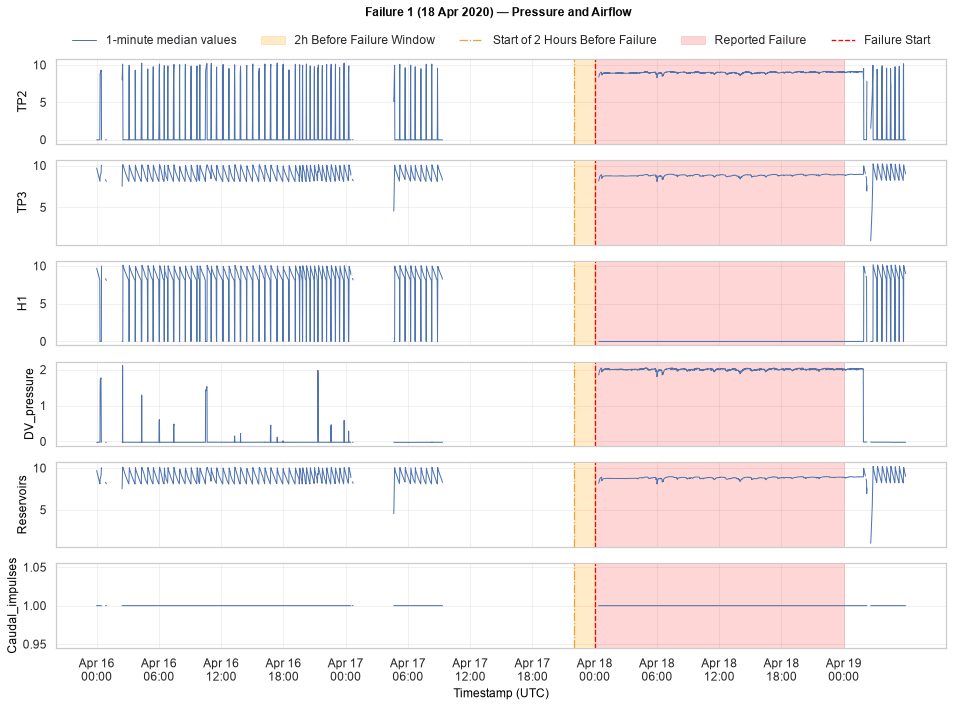

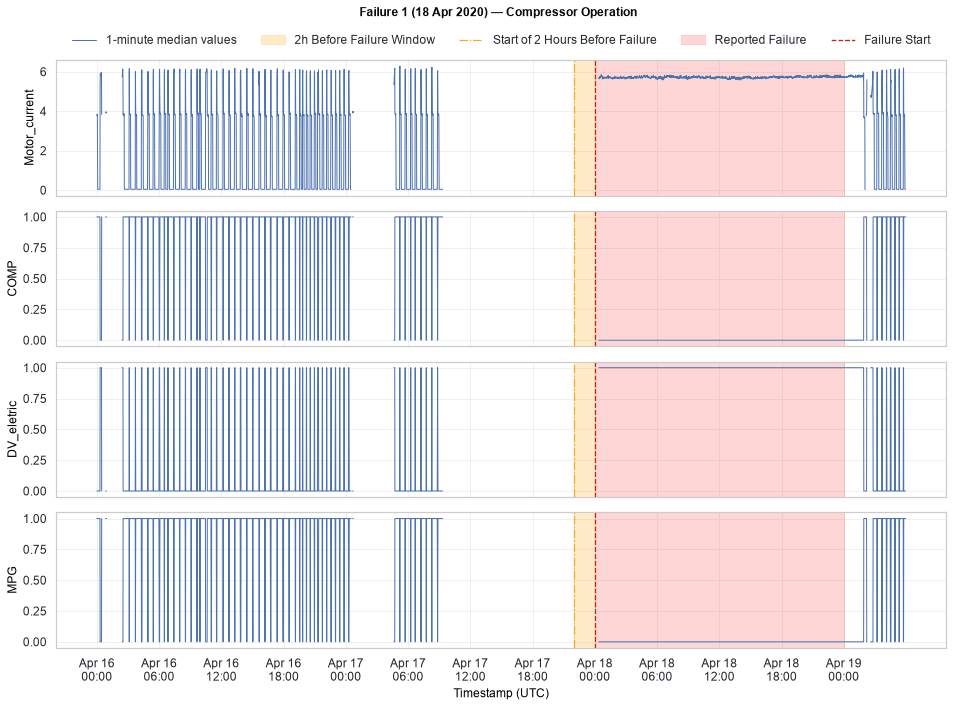

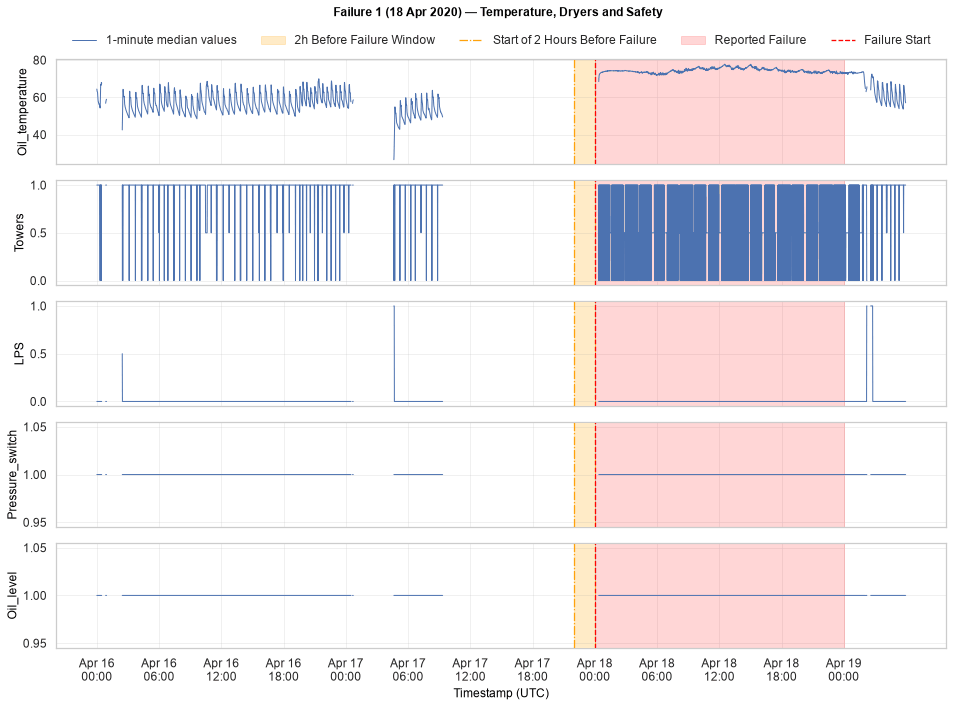

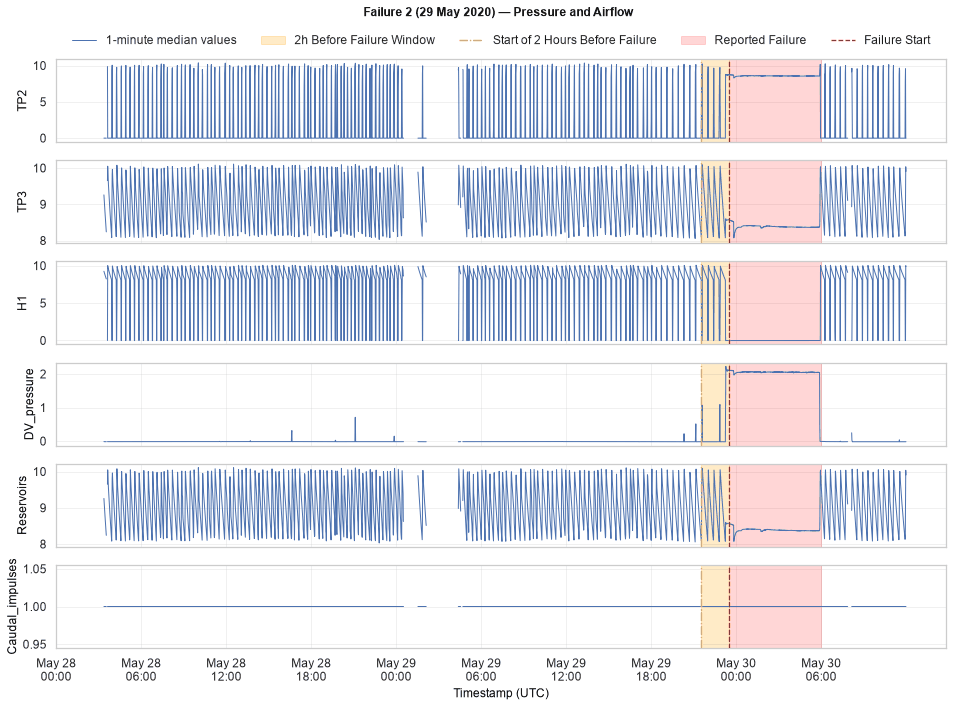

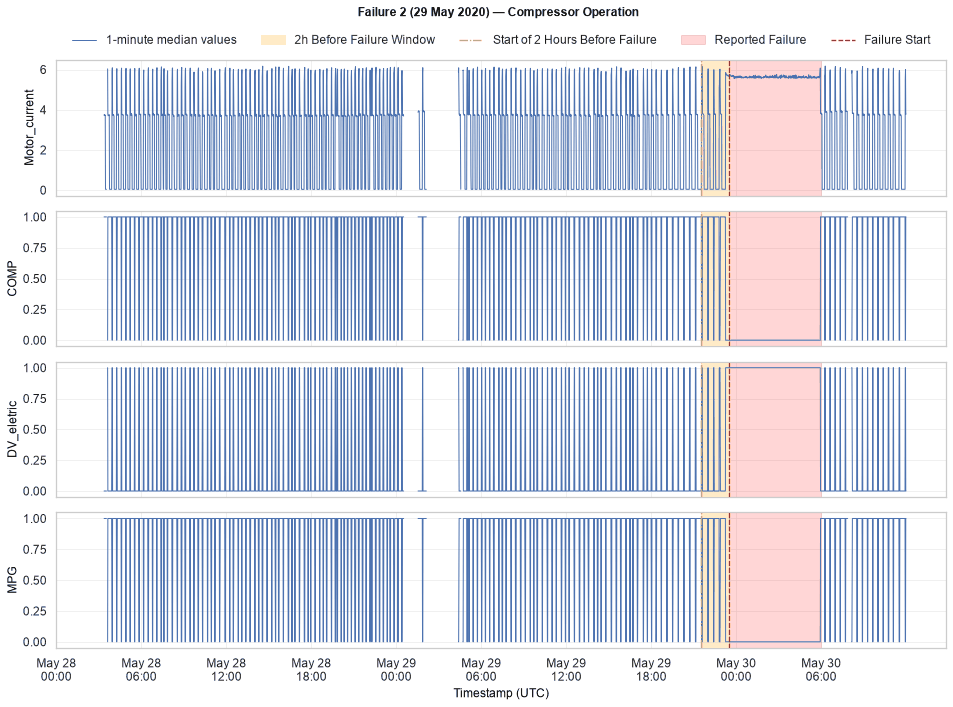

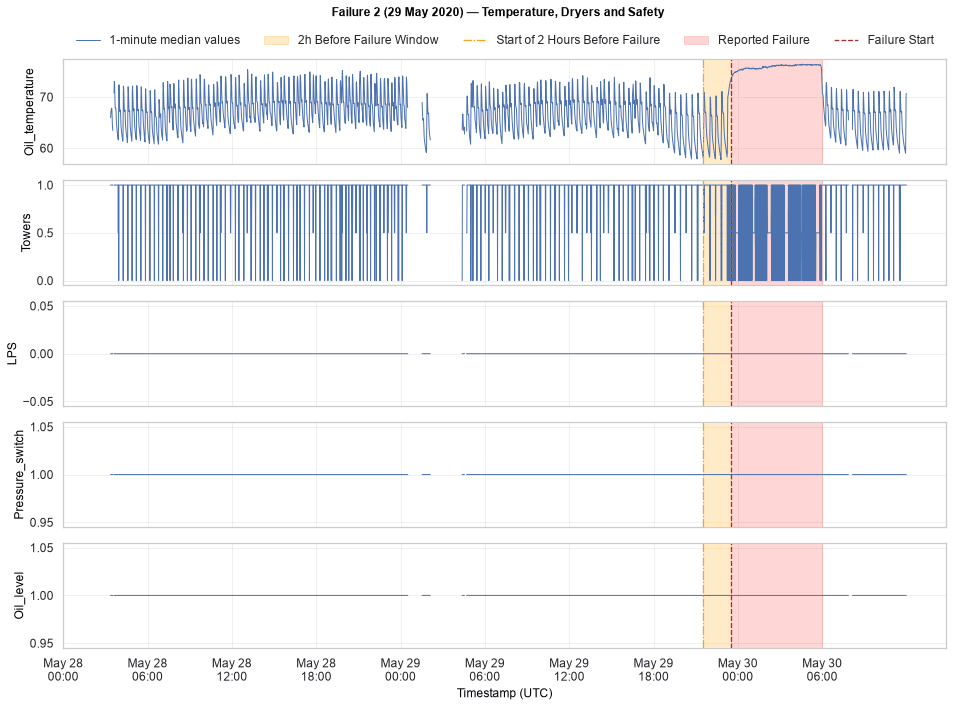

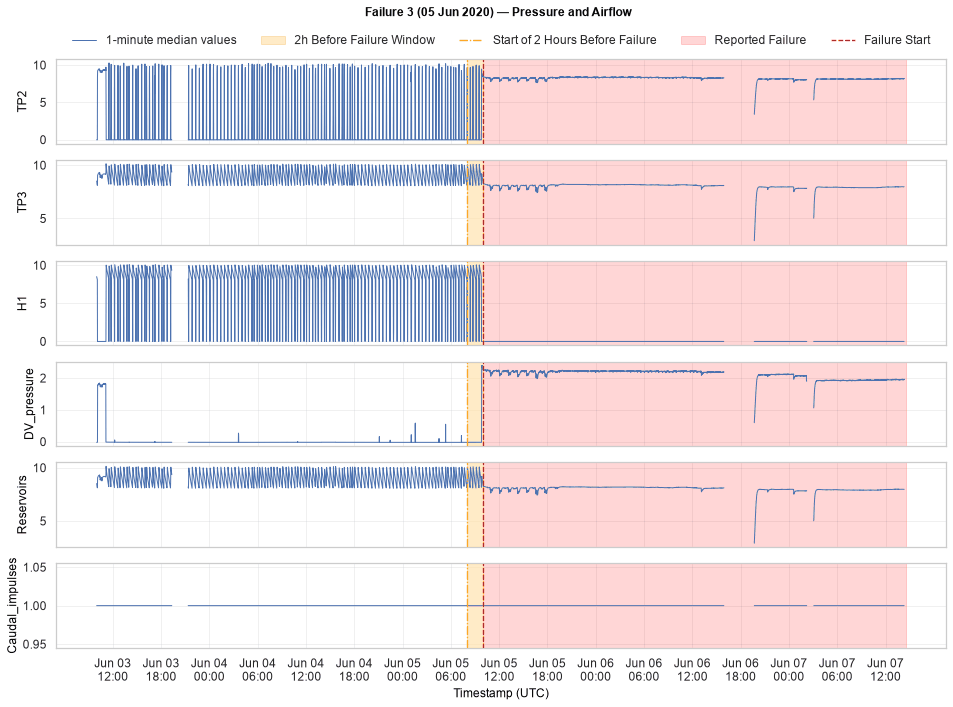

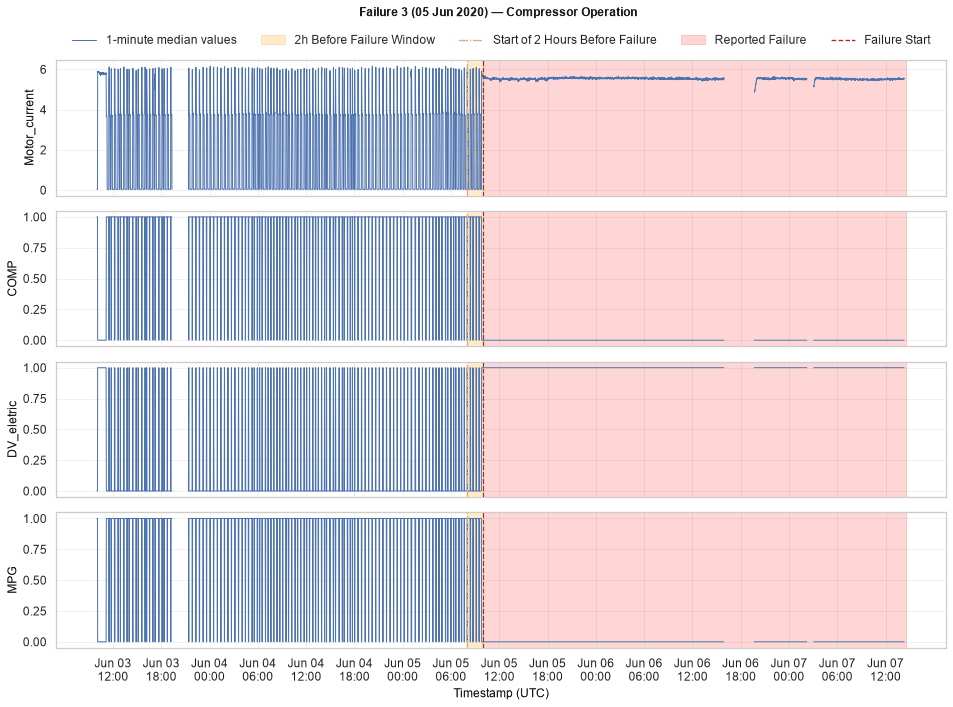

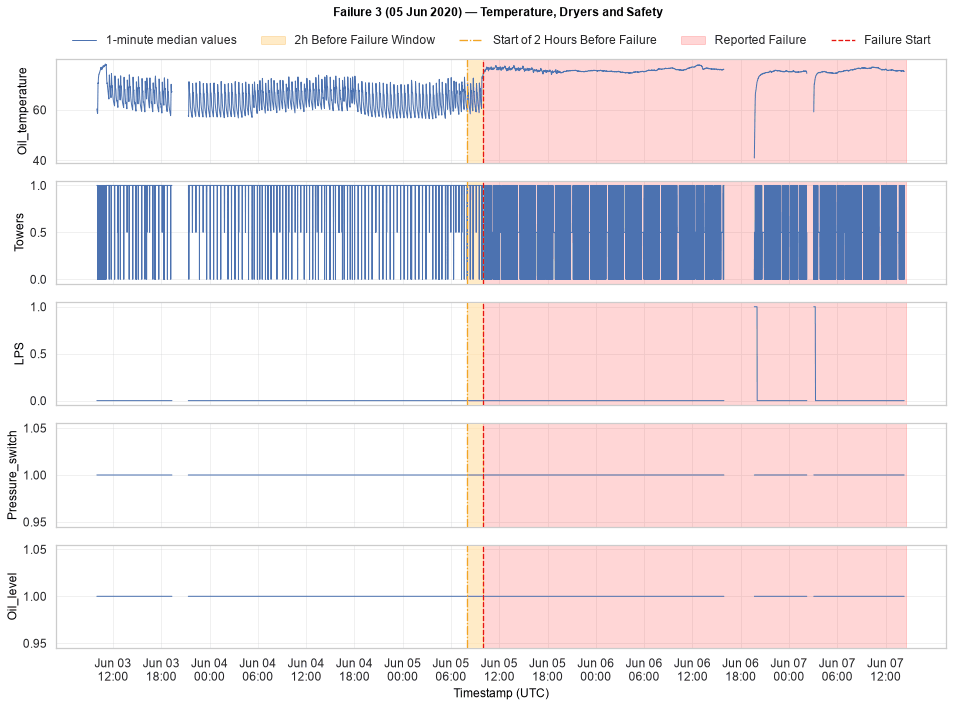

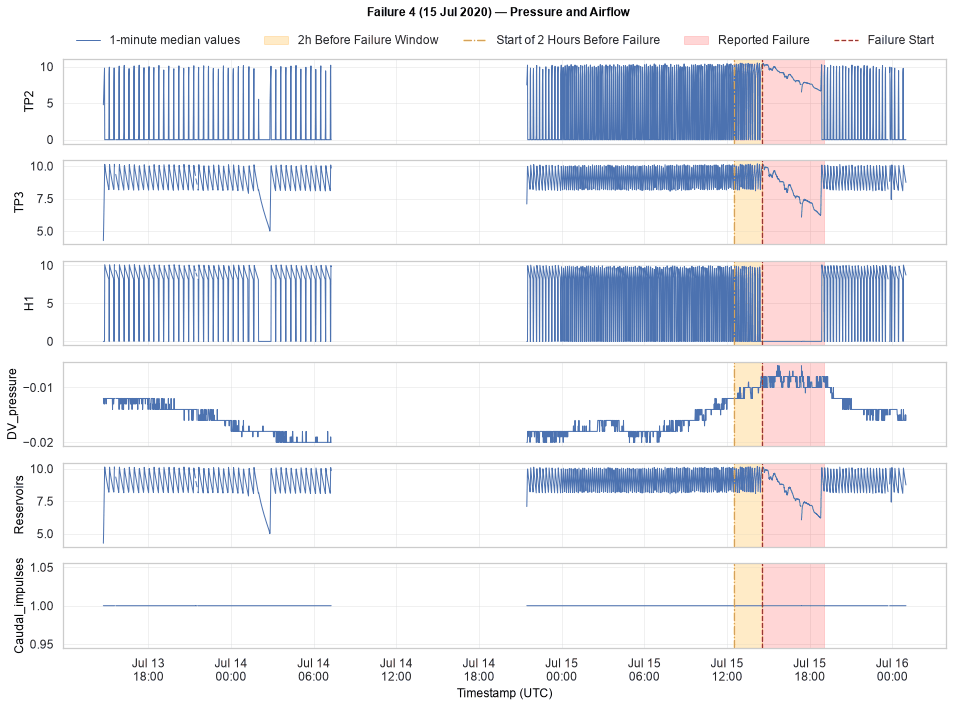

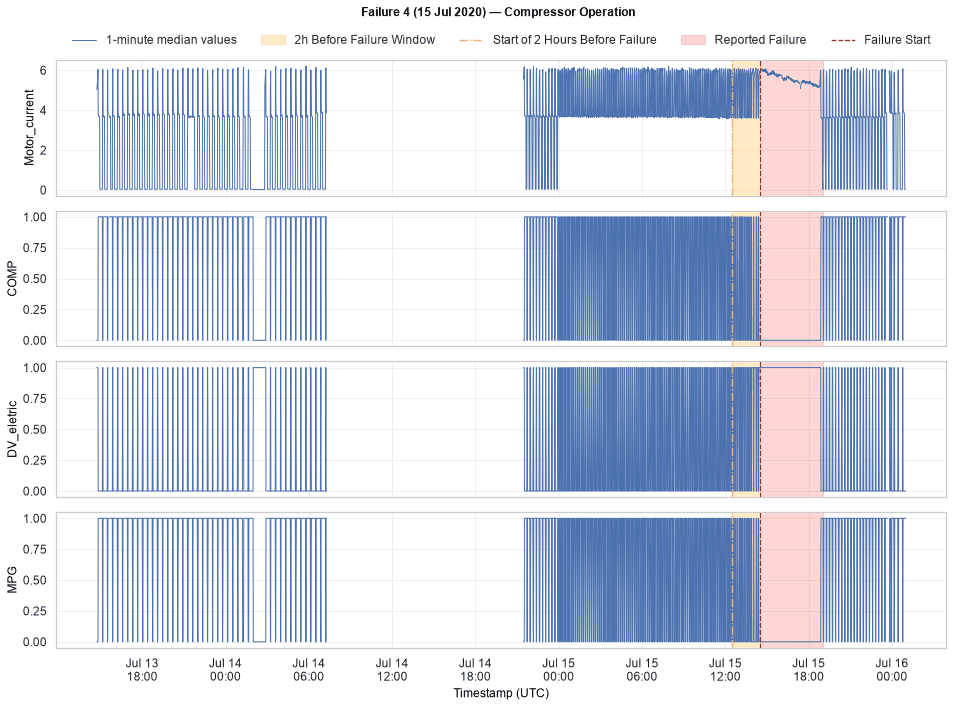

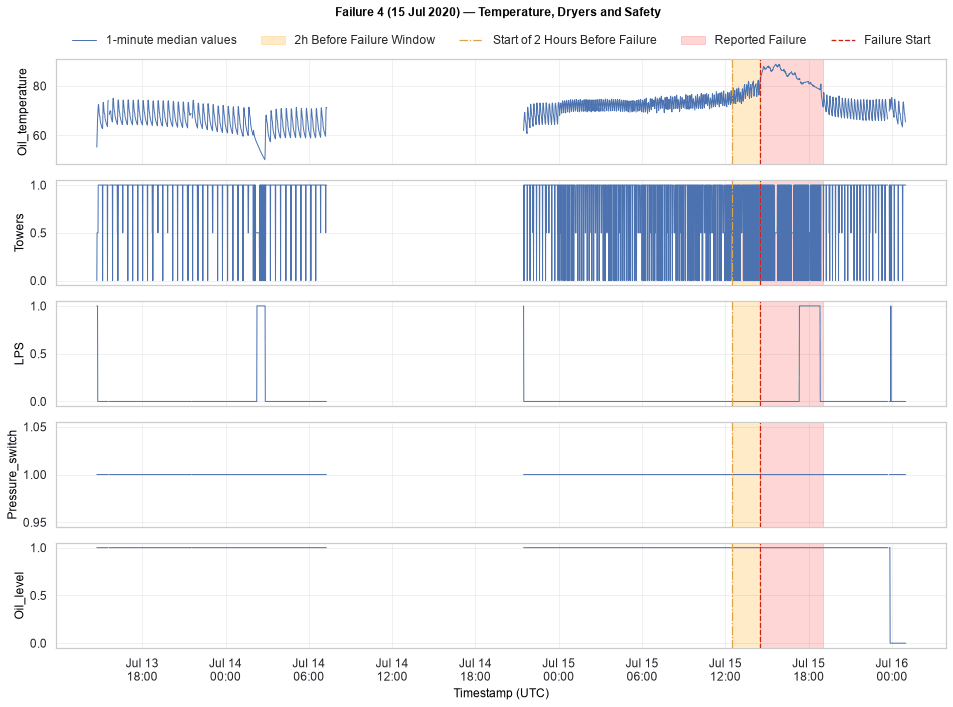

In [118]:
def plot_slide_failure_group(ts_df, failure_events, failure_id, group_name, hours_before=48, hours_after=6):
    
    sensors = sensor_groups[group_name]
    event = failure_events.loc[failure_events['failure_id'] == failure_id].iloc[0]
    f_start = event['start_time']
    f_end = event['end_time']
    early_prediction_target = f_start - pd.Timedelta(hours=2)

    # Select data n hours before and m hours after the failure
    # Plotting 1-minute (minutely) median values; taking the median of 6 samples
    window = slice(f_start - pd.Timedelta(hours=hours_before), f_end + pd.Timedelta(hours=hours_after))
    subset = ts_df.loc[window, sensors]
    subset_plot = subset.resample('1min').median()

    fig, axes = plt.subplots(len(sensors), 1, figsize=(14, 10), sharex=True)

    for i, sensor in enumerate(sensors):
        ax = axes[i]
        ax.plot(subset_plot.index, subset_plot[sensor], linewidth=1.0, label='1-minute median values')

        # Mark the 2-hour window (light orange) & reported failure period (light red)
        ax.axvspan(early_prediction_target, f_start, color='orange', alpha=0.22, label='2h Before Failure Window')
        ax.axvline(early_prediction_target, color='orange', linestyle='-.', linewidth=1.3, label='Start of 2 Hours Before Failure')
        ax.axvspan(f_start, f_end, color='red', alpha=0.16, label='Reported Failure')
        ax.axvline(f_start, color='red', linestyle='--', linewidth=1.3, label='Failure Start')

        ax.set_ylabel(sensor, fontsize=12, color='black')
        ax.tick_params(axis='y', labelsize=12)
        ax.grid(alpha=0.28)

        # Put one shared legend on the top subplot
        if i == 0:
            ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=5, frameon=False, fontsize=12)

    # Keep the clean two-line date & time labels on the bottom x-axis
    ticks = pd.date_range(subset_plot.index.min().ceil('6h'), subset_plot.index.max(), freq='6h')
    plt.xticks(ticks, [t.strftime('%b %d\n%H:%M') for t in ticks], fontsize=12)
    axes[-1].set_xlabel('Timestamp (UTC)', fontsize=12, color='black')

    # Main title for the whole figure
    fig.suptitle(
        f"Failure {failure_id} ({f_start.strftime('%d %b %Y')}) — {group_name}",
        y=0.98, fontsize=12, fontweight='bold', color='black'
    )

    plt.tight_layout()
    plt.show()


# 12 plots (4 Failures x 3 Sensor Groups)
for fid in [1, 2, 3, 4]:
    for grp_name in sensor_groups.keys():
        plot_slide_failure_group(ts_clean_no_frozen, failure_events, failure_id=fid, group_name=grp_name)

## 6. Feature Engineering

## 6.1 Domain Feature Engineering (Segment-Aware 60-Minute Rolling Features)

As shown in Section 5, wide 24-hour averages smooth out short-term degradation, while instantaneous 10-second readings (or 1-minute medians) only capture single-moment states rather than how frequently the compressor cycles or how fast pressure bleeds off between refills. Furthermore, because a normal charge–discharge cycle takes a median of 20.6 minutes (~2.9 cycles/hour), shorter 10–15 minute windows frequently fall inside a single rest or pump phase and produce noisy or missing estimates. To capture early air-leak symptoms without crossing recording gaps or including logger faults, all rolling features below are computed **strictly inside each continuous segment_id** using **60-minute trailing clock-time windows** and masking rows where **sensors_frozen** == 1:

#### 1. **loaded_time_share_60m** *(Ratio, 0–1)*

Rolling 60-minute share of valid time the compressor operates under load (**DV_eletric** == 1). Captures sustained overload when an air leak prevents the reservoirs from reaching the 10.2 bar shutoff threshold, measuring what fraction of the past 60 minutes the compressor spent actively pumping.

* **Normal:** 0.00 when parked, or **~0.11 – 0.16 (11%–16%)** during normal service — consistent with the dataset **DV_eletric** mean (0.161) and healthy pre-failure means (0.11–0.16 in Failures 2–4). (Section 3.5.7 flags daily duty cycles > 45% as abnormal.)


* **Early detection:** Rises above the ~0.16 service baseline when a developing leak forces longer and more frequent loaded pumping cycles, climbing to **0.39 (39%)** in the 24–0h window before Failure 4.


* **During failure:** Locks at **0.97 – 1.00 (97%–100%)** across all four failures (0.99 in Failure 2, 1.00 in Failure 3, 0.97 in Failure 4) as the compressor runs continuously under load.



#### 2. **compressor_starts_60m** *(Count/hour)*

Rolling 60-minute count of loaded pumping starts (**DV_eletric** flipping 0 → 1 inside the same continuous segment). Captures early short-cycling when a minor leak forces the compressor to restart more frequently, counting how many times the compressor switches into active load over the past hour.

* **Normal:** 0 when parked, or roughly **~3 – 8 starts/hr** in normal service — aligned with the median 20.6-minute cycle period (~2.9 cycles/hr) and Section 3.5.7's daily **load_starts** analysis (which flags > 300 cycles/day, or ~12.5–17 starts/hr, as abnormal).


* **Early detection:** **Spikes above normal** due to short-cycling, as seen in Failure 4's 24–0h pre-failure window where load-cycle frequency increased sharply while the compressor was still shutting off between refills.


* **During failure:** **Collapses back to 0 or 1** because the compressor never reaches the 10.2 bar shutoff limit and stays locked continuously under load (**DV_eletric** ≈ 1.00).



#### 3. **oil_temp_mean_60m** *(Interval, °C)*

Rolling 60-minute average of **Oil_temperature**. Smooths 10-second noise to capture gradual motor overheating as resting intervals shrink.

* **Normal:** **~50 – 70 °C** — based on the failure-window baseline (50–70 °C), dataset median (62.7 °C), and healthy 48–24h pre-failure means (64.7 °C in Failure 3, 65.6 °C in Failure 4, 67.7 °C in Failure 2).


* **Early detection:** Climbs above the 70 °C baseline in the 24–0h window before Failure 4 (rising from 65.6 °C to 72.8 °C, and reaching ~80 °C in the final 14 hours) as shorter offloaded intervals reduce motor cooling time.


* **During failure:** Sustained **74 – 84 °C** across all four failures (75.5 °C in Failure 3, 75.9 °C in Failure 2, 83.9 °C in Failure 4; dataset max 89.05 °C).



#### 4. **tp3_min_60m** *(Ratio, bar)*

Rolling 60-minute minimum of **TP3** (pressure at the pneumatic panel and reservoirs). Normally **MPG** triggers refilling at 8.2 bar, so tracking the lowest dip in the past hour catches early pressure sagging below the 8.2 bar refill floor before the 7.0 bar **LPS** emergency alarm triggers.

* **Normal:** **~8.2 – 10.2 bar** — governed by the 8.2 bar **MPG** cut-in threshold and 10.2 bar shutoff limit, with healthy pre-failure means around 8.88 – 9.11 bar.


* **Early detection:** Typically **remains within ~8.2 – 9.1 bar** because the compressor masks mild leaks by refilling more frequently (9.02 bar mean in Failures 2 and 3, 9.11 bar in Failure 4's 24–0h window), showing why raw pressure alone misses early degradation.


* **During failure:** **Drops below 8.2 bar**, with failure means falling to 8.02 – 8.40 bar (Failures 2–4) and plunging to **~6.2 bar** in Failure 4 (activating the < 7.0 bar **LPS** alarm 33% of the time).



#### 5a. **tp3_drain_rate_60m** *(Ratio, bar/min while **DV_eletric** == 0)*

Rolling 60-minute average rate of **TP3** pressure change (ΔTP3 / Δt, accounting for 9–13 s timestamp jitter) measured **only during valid not-loaded steps (**DV_eletric** == 0)**, computed only when at least **DRAIN_MIN** (110) not-loaded steps exist in the window. Separating drain rate from fill rate prevents negative bleed-down slopes and positive refill slopes from canceling out toward zero.

* **Normal:** **Slightly negative (~ -0.05 to -0.15 bar/min)** — reflecting normal gradual pressure drift from 10.2 bar down to 8.2 bar during offloaded rest phases.


* **Early detection:** **Becomes sharply more negative** during offloaded pauses as air escapes faster, directly quantifying the physical leak rate before the compressor becomes overwhelmed.


* **During failure:** Becomes **NaN (insufficient offloaded phases)** because the compressor remains trapped in continuous loaded operation (**DV_eletric** == 1).



#### 5b. **tp3_fill_rate_60m** *(Ratio, bar/min while **DV_eletric** == 1)*

Rolling 60-minute average rate of **TP3** pressure change (ΔTP3 / Δt) measured **only during valid loaded steps (**DV_eletric** == 1)**, computed only when at least **FILL_MIN** (14) loaded steps exist in the window. Directly measures how effectively the compressor builds reservoir pressure while pumping.

* **Normal:** **Strongly positive (~ +0.60 to +1.00 bar/min)** — reflecting healthy replenishment of **TP3** from 8.2 bar back up to 10.2 bar across a typical ~2.3-minute loaded burst.


* **Early detection:** **Decreases toward 0 bar/min (slower pressure rise)** because escaping air bleeds off part of the compressor's output even while pumping at full load.


* **During failure:** Stalls near **~0.00 bar/min (or turns negative)** during continuous loaded operation (**DV_eletric** == 1) as outflow matches or exceeds compressor delivery.



#### 6. **dryer_abn_share_60m** *(Ratio, 0–1 while **DV_eletric** == 1)*

Rolling 60-minute share of valid loaded rows (**DV_eletric** == 1) where **DV_pressure** exceeds **DRYER_THR** (1.0 bar), computed only when at least **ABN_MIN** (14) loaded rows exist in the window. Flags abnormal air pressure at the air-dryer discharge drain pipe while the compressor is pumping under load.

* **Normal:** **~0.00 (0%–0.5%)** — in healthy loaded operation, **DV_pressure** stays at or below 1.0 bar (0.48% above 1.0 bar in the healthy reference period).


* **Early detection:** **Rises above the ~0.005 baseline** when intermittent valve leakage pushes **DV_pressure** past 1.0 bar during loaded pumping bursts before full breakdown.
* **During failure:** Jumps toward **~1.00 (nearly 100% of loaded time)** as **DV_pressure** climbs to **~1.9 – 2.0 bar** during continuous loaded operation (1.92 bar in Failure 2, 2.02 bar in Failure 3).



#### 7. **filter_abn_share_60m** *(Ratio, 0–1 while **DV_eletric** == 1)*

Rolling 60-minute share of valid loaded rows (**DV_eletric** == 1) where **H1** exceeds **FILTER_THR** (0.008 bar), computed only when at least **ABN_MIN** (14) loaded rows exist in the window. Flags unexpected pressure at the cyclonic separator filter discharge valve while under load.

* **Normal:** **~0.00 (near 0%)** — under load, the cyclonic separator drain valve is sealed shut and **H1** sits inside its negative zero-drift band (down to -0.036 bar in Section 3.4.4).


* **Early detection:** **Rises above 0.00** whenever compressed air begins venting past the cyclonic separator filter valve during loaded operation.


* **During failure:** Rises substantially during continuous loaded operation (with **H1** averaging 0.07 bar in Failure 2 and 0.25 bar in Failure 4).

4 overall workload/thermal features plus 3 targeted leak detectors for the exact 3 physical leak locations

Things to keep in mind when feature engineering:

1. since we are creating rolling-window features for 1 hour (60 minutes) and the segments can not be crossed over (strictly grouping by continuous segments), the first 340 rows in every segment will be dropped, otherwise for the very initiali rows of the segment, values will be calculated based on only very few values which will be falsely depicted as being the values for a time period of 1h (60m). Also, extremely high or extremely low values will affect the statistic over the rolling window largely, since it will be distributed over a few rows. Sometime presence of one very high or low value at the begining of segments affect the value used for that row greatly.

In [119]:
d = df[df["sensors_frozen"] == 0].copy()
d["prev"] = d.groupby("segment_id")["DV_eletric"].shift(1)
starts = d[(d["DV_eletric"] == 1) & (d["prev"] == 0)]              # moments the compressor starts loading
gap_min = starts.groupby("segment_id")["timestamp"].diff().dt.total_seconds() / 60

print(gap_min.describe(percentiles=[.25, .5, .75]).round(1))
print("cycles per hour:", round(60 / gap_min.median(), 1))
print("window for 3 cycles:", round(3 * gap_min.median()), "min")

count    10684.0
mean        21.1
std         13.8
min          0.3
25%         15.7
50%         20.6
75%         25.4
max        722.7
Name: timestamp, dtype: float64
cycles per hour: 2.9
window for 3 cycles: 62 min


### Why 60-minute rolling window?

Cycle length. From the raw DV_eletric signal, the median time between load starts is 20.6 minutes (middle half 15.7 to 25.4).

Why at least 3 cycles. A window’s edges cut cycles in half, so the error is about one cycle. With 3 cycles that is about a third of the window. With fewer it is worse.

Why not longer. The goal is a warning at least 2 hours before a failure, so the window must stay well under 2 hours. 3 × 20.6 = 62 minutes, which rounds to 60.

In [120]:
# CONFIG SETTINGS FOR FEATURE ENGINEERING
WINDOW      = "60min"        # about 3 compressor cycles (median cycle = 20.6 min)
MIN_ROWS    = 340            # a 1-hour feature needs >= 340 valid rows (about 57 minutes out of a 60-minute window) in its window

In [121]:
# COMMON FILTERING COLUMNS

df_fe = df.copy()
seg   = df_fe["segment_id"]                          
valid = df_fe["sensors_frozen"].eq(0)           # True = real reading, False = frozen logger row
loaded = df_fe["DV_eletric"].eq(1)              # True = compressor loaded; it is actively running and compressing air


# state of previous row (if under load and if valid (not frozen sensor reading)
prev_loaded = loaded.groupby(seg, sort=False).shift(1, fill_value=False)   
# previous row (same segment) was under load
prev_valid  = valid.groupby(seg, sort=False).shift(1, fill_value=False)    # previous row (same segment) valid?

### Identify which rows are usable? (feature_ready)
A row is **usable** if its last 60 minutes hold at least MIN_ROWS valid rows of the same segment.
Why same segment? A new segment id is assigned only after a recording gap. Taking readings from different segments would mean there were recording gaps between the rows, therefor the timestamps would not be contiguous then.

The first ~57 minutes (340 rows) of every segment, and the time after a long frozen block, therefore have no value. The reason being that due to less number os rows, the averages would not be calculated for actually 60 minutes. The 60-minute window is a common rule being followed for all features in this notebook. Additionally, having only a few rows and calculating the rolling average could cause very high or very low values to wrongly represent the feature statistic calculated, since it would be divided over few rows. Therefore, those rows (which do not have a **minimum of 340 valid (non-frozen) rows** preceding them within the **same segment (segment_id)** are **left out, not filled**.

A row is valid if its sensor_frozen == 0.

In [122]:
valid_rows = pd.Series(valid.astype(float).to_numpy(), index=df_fe["timestamp"])
df_fe["valid_rows_60m"] = valid_rows.groupby(seg.to_numpy(), sort=False).rolling(WINDOW, min_periods=1).sum().to_numpy()
df_fe["feature_ready"]  = df_fe["valid_rows_60m"].ge(MIN_ROWS) & valid

print("usable rows:", int(df_fe["feature_ready"].sum()), "of", len(df_fe))
print(f"usable rows: {(df_fe['feature_ready'].sum() / len(df) * 100):.2f}% of", len(df_fe))

usable rows: 1380096 of 1516948
usable rows: 90.98% of 1516948


**valid rows**: Real sensor readings that are not logger faults (sensors_frozen == 0).

**feature_ready rows:** Rows that are both real themselves (valid == True) and have at least MIN_ROWS (e.g., 340) real readings inside the trailing 60-minute window of their continuous segment_id (valid_rows_60m >= MIN_ROWS)—meaning they have enough unbroken history to be scored by the model.

at least 340 of the rows inside that preceding 60-minute window (including the current row itself) must be valid (sensors_frozen == 0) and belong to the same continuous segment_id.

### Feature 1: onload_time_share_1h  (share of the last hour spent loaded)

In [123]:
# 1 = loaded, 0 = not loaded, NaN on frozen rows (ignored by the mean)
onload_flag = loaded.astype(float).where(valid)

onload_ts = pd.Series(onload_flag.to_numpy(), index=df_fe["timestamp"])

df_fe["onload_time_share_1h"] = (
    onload_ts.groupby(seg.to_numpy(), sort=False).rolling(WINDOW, min_periods=MIN_ROWS).mean().to_numpy()
)
display(df_fe.loc[df_fe["feature_ready"], ["onload_time_share_1h"]].describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
onload_time_share_1h,1380096.0,0.1494,0.1878,0.0247,0.0716,0.1099,0.1374,1.0


### Feature 2: compressor_starts_1h  (number of 0 to 1 flips of DV_eletric in the last hour)

In [124]:
# What defines a start? (DV_electric flip from 0 --> 1)
# A start = the current row is loaded (under load), the previous row (same segment) was not, and both rows are valid (not frozen rows)
start_flag = (loaded & ~prev_loaded & prev_valid).astype(float).where(valid)

starts_ts = pd.Series(start_flag.to_numpy(), index=df_fe["timestamp"])
df_fe["compressor_starts_1h"] = (
    starts_ts.groupby(seg.to_numpy(), sort=False).rolling(WINDOW, min_periods=MIN_ROWS).sum().to_numpy()
)
display(df_fe.loc[df_fe["feature_ready"], ["compressor_starts_1h"]].describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
compressor_starts_1h,1380096.0,2.7381,1.1434,0.0,2.0,3.0,3.0,10.0


### Feature 3: oil_temp_mean_1h  (mean oil temperature of the last hour)

In [125]:
oil_valid = df_fe["Oil_temperature"].where(valid)      # for non-frozen rows, get the oil temps

oil_ts = pd.Series(oil_valid.to_numpy(), index=df_fe["timestamp"])

df_fe["oil_temp_mean_1h"] = (
    oil_ts.groupby(seg.to_numpy(), sort=False).rolling(WINDOW, min_periods=MIN_ROWS).mean().to_numpy()
)
display(df_fe.loc[df_fe["feature_ready"], ["oil_temp_mean_1h"]].describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
oil_temp_mean_1h,1380096.0,62.7136,5.4301,39.2273,58.3227,63.5373,66.3601,87.6165


### Feature 4: tp3_min_1h  (lowest tank pressure of the last hour)

In [126]:
tp3_valid = df_fe["TP3"].where(valid)

tp3_ts = pd.Series(tp3_valid.to_numpy(), index=df_fe["timestamp"])

df_fe["tp3_min_1h"] = (
    tp3_ts.groupby(seg.to_numpy(), sort=False).rolling(WINDOW, min_periods=MIN_ROWS).min().to_numpy()
)
display(df_fe.loc[df_fe["feature_ready"], ["tp3_min_1h"]].describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
tp3_min_1h,1380096.0,8.0362,0.3286,0.73,8.026,8.062,8.094,9.552


### Settings for features 5a, 5b, 6 and 7

Features 1 to 4 use *every* valid row in the 60-minute window, regardless of the compressor's state (or cycle it is in), because features 1-4 do not depend on that. 

Features 5a, 5b, 6 and 7 are different: each one uses only the rows where the compressor is in a **particular state**.

| Feature | Uses only | Share of the hour |
|---|---|---|
| 5a. tp3_drain_rate_60m | rows (steps) where the compressor is **not loaded** (off or offloaded) | about 85% of rows |
| 5b. tp3_fill_rate_60m | rows where the compressor is **loaded** | about 15% of rows |
| 6. dryer_abn_share_60m | **loaded** rows | about 15% of rows |
| 7. filter_abn_share_60m | **loaded** rows | about 15% of rows |

Because they use only some rows, these features need two kinds of settings that features 1 to 4 do not need.

**Evidence used (all from earlier sections of this notebook)**
1. Share of time in each state: the compressor is off about half the time, offloaded about 30% and loaded about 15% (Sections 3.5.3 and 4.8.3).
2. Length of a loaded phase: 2 to 3 minutes (Section 4.8.2).
3. **Sensor zero offset**: pressures read slightly below 0 because of the sensor zero offset, not because of errors (Section 3.4.4).
4. Behaviour of H1 and DV_pressure per operating state (Section 3.5.4).
5. **Healthy reference period:** 1 Feb to 11 Apr 2020 (Section 2.2.3).

### A. Minimum number of rows of that state (DRAIN_MIN, FILL_MIN, ABN_MIN)

**What each setting stands for and how it is chosen.** Each threshold requires the 60-minute window to capture at least one typical unbroken phase of that operating state. Typical phase durations are measured directly from continuous runs of the raw DV_eletric signal inside valid, non-frozen recording segments:

1. **FILL_MIN (Fill Minimum Rows):** The minimum number of loaded rows (DV_eletric == 1) required in a 60-minute window to calculate tp3_fill_rate_60m (Feature 5b). It is set to the median length of a healthy loaded phase (~2 to 3 minutes, or ~12 to 18 rows).

2. **ABN_MIN (Abnormal-Check Minimum Rows):** The minimum number of loaded rows (DV_eletric == 1) required in a 60-minute window to calculate dryer_abn_share_60m (Feature 6) and filter_abn_share_60m (Feature 7). Because Features 6 and 7 also evaluate loaded operation, ABN_MIN uses the same rule as FILL_MIN (the median length of a healthy, loaded phase), preventing a single isolated row from swinging a share to 0.0 or 1.0.

3. **DRAIN_MIN (Drain Minimum Rows):** The minimum number of not-loaded rows (DV_eletric == 0, covering off and offloaded states) required in a 60-minute window to calculate tp3_drain_rate_60m (Feature 5a). It is set to the median length of a healthy not-loaded phase, ensuring a representative resting/bleed-down interval is observed. If the compressor runs continuously under load for an entire hour during a severe leak, not-loaded rows fall below DRAIN_MIN and tp3_drain_rate_60m is left as NaN.

**Why it is needed.** An average over one or two rows is not a measurement. Measurements in windows having very few rows in the state (loaded / not-loaded) for the feature can lead to inflated or extremely low values driven by just a couple of rows. A value is therefore only computed if the window contains enough rows of that state required for the calculation of that feature.

**How we chose the numbers.** The rule is: *the window must contain at least one typical phase of that state.* We measured typical phase lengths directly from the raw DV_eletric signal:

| Setting | Meaning | Rule | Value |
|---|---|---|---|
| FILL_MIN | loaded steps needed for the fill rate | median length of a loaded phase | 14 rows (2.3 min) |
| ABN_MIN | loaded rows needed for features 6 and 7 | median length of a loaded phase | 14 rows (2.3 min) |
| DRAIN_MIN | not-loaded steps needed for the drain rate | median length of a not-loaded phase | 110 rows (18.3 min) |

If the window holds less than that (for example, the compressor was loaded for the whole hour, so there are no recorded offloaded / off states in that hour to compute a drain rate), the feature is left empty and the row is not used for modelling. Nothing is filled in.

Example: 
- A normal load (compressor running) phase lasts ~2–3 minutes (~12–18 rows), so FILL_MIN and ABN_MIN are set to the median length of a loaded phase.
- DRAIN_MIN is set to the median length of a not-loaded rest phase.
- If an hour has fewer rows than that minimum (for example, the compressor was stuck pumping for the entire hour, so there were 0 rest rows), we leave the feature empty (NaN) instead of faking a number.

### B. What counts as an "abnormal" pressure (DRYER_THR, FILTER_THR)

**Why it is needed.** 

- **Features 6 and 7 answer the question *"how often is the pressure abnormal while the compressor is loaded?"***
- To count that, we need a definition of abnormal. During normal loaded operation, H1 (cyclonic filter) sits tightly around 0 bar, while DV_pressure (air-dryer discharge) remains at or below 1.0 bar (rising to about 2 bar during failures). Values clearly above each sensor's normal healthy range indicate unexpected pressure in the drain/discharge lines.
- Features 6 and 7 measure "what fraction of loaded time in the past 60 minutes showed unexpected pressure in the drain/discharge lines?" They work in two stages:
  - **Row-level check:** While the compressor is loaded (DV_eletric == 1), does DV_pressure or H1 exceed its normal healthy range (1 = pressure present, 0 = normal)?
  - **Window-level aggregation:** What share of all loaded rows in the trailing 60 minutes were flagged as 1?

A loaded reading counts as ‘pressure present’ when it sits above the healthy operating range for that sensor, yet below the elevated pressures observed during real valve leaks (~0.07–0.25 bar for H1 and ~1.9–2.0 bar for DV_pressure):

1. **Bottom Boundary**: Normal healthy range. The threshold must sit above the sensor's normal healthy readings (electronic zero-drift down to −0.036 bar for H1, and the dual healthy operating levels up to 1.0 bar for DV_pressure) so ordinary operation does not trigger false alarms.
2. **Top Boundary**: Real leak pressures. The threshold has to be less than the pressures observed during real valve leaks (~0.07–0.25 bar for H1 and ~1.9–2.0 bar for DV_pressure), making sure that genuine leaks exceed the threshold and are caught.
3. Healthy Operating Range  <  THRESHOLD  <  Real Leaks

**What each setting stands for and how it is calibrated.** To avoid data leakage, failure rows are never used to pick the thresholds. Instead, both cutoffs are determined strictly from healthy loaded rows (DV_eletric == 1, sensors_frozen == 0, prior to 11 Apr 2020, Evidence 5):

- **DRYER_THR (Air-Dryer Discharge Pressure Threshold = 1.0 bar):** The cutoff (in bar) on DV_pressure above which a loaded reading indicates unexpected air escaping through the air-dryer tower drain valve. Healthy loaded DV_pressure readings occupy two normal operating plateaus—about 70% up to 0.05 bar and about 24% between 0.5 and 1.0 bar—followed by an almost empty gap between 1.0 and 1.5 bar (with 99.52% of healthy loaded rows at or below 1.0 bar). Because Tukey's fence assumes a single tight cluster, Q3 lands on the upper plateau and inflates the fence to 1.992 bar; fixing **DRYER_THR = 1.0 bar** cuts directly inside the empty gap just above the healthy bulk and well below the ~2.0 bar failure level.
- **FILTER_THR (Cyclonic Filter Discharge Pressure Threshold = 0.008 bar):** The cutoff (in bar) on H1 above which a loaded reading indicates unexpected pressure/leakage at the cyclonic separator filter discharge valve. Healthy loaded H1 readings form a single tight cluster in the negative zero-drift band (roughly −0.036 to 0.00 bar, Evidence 3), so applying Tukey's outer fence ($Q_3 + 3 \times \text{IQR}$) cleanly separates the upper edge of sensor noise (**0.008 bar**) while ignoring rare valve-switching transition spikes.

| Setting | Meaning | Calibration rule (healthy loaded rows) | Chosen value |
|---|---|---|---|
| DRYER_THR | DV_pressure above this = abnormal | Fixed cutoff in empty 1.0–1.5 bar gap just above healthy 0–1.0 bar bulk | 1.0 bar |
| FILTER_THR | H1 above this = abnormal | Tukey's outer fence ($Q_3 + 3 \times \text{IQR}$) | 0.008 bar |

**Check.** Failure labels were *not* used to choose the threshold. We only used them afterwards to check it: **the share of abnormal loaded rows should be close to 0 in healthy periods and much higher inside the failure windows (0.48% healthy vs. 94.51% failure for DV_pressure > 1.0 bar; 1.32% healthy vs. 0.01% failure for H1 > 0.008 bar, reflecting that F2 and F3 were air-dryer drain leaks).**

### C. What was left out on purpose

No imputation of missing window outputs: When a window lacks sufficient rows of a given state (for example, zero not-loaded rows during continuous failure pumping), the feature remains NaN rather than being filled with an assumed constant.

Global window completeness (MIN_ROWS — Minimum Valid Window Rows): Consistent with Features 1 to 4, any 60-minute window must contain at least MIN_ROWS valid (non-frozen) observations within the same continuous segment_id so windows truncated by recording gaps or logger freezes are excluded.

### Configuration Settings for Features 5,6,7

#### Find FILL_MIN, ABN_MIN, and DRAIN_MIN (Minimum Row Counts)

* we split the timestamps into unbroken loaded (True) and not-loaded (False) stretches inside each segment_id, ignores stretches with frozen sensors, and finds the median duration of each state:

In [127]:
# Block 1: Median length of loaded vs. not-loaded phases

is_loaded = df["DV_eletric"] == 1

# check if compressor changes state (loaded --> not-loaded) or is of a different segment
new_phase = (is_loaded != is_loaded.shift()) | (df["segment_id"] != df["segment_id"].shift())
phase_id = new_phase.cumsum()

phases = (
    df.assign(is_loaded=is_loaded, phase_id=phase_id).groupby("phase_id")
    .agg(
        is_loaded=("is_loaded", "first"),
        rows=("is_loaded", "size"),
        has_frozen=("sensors_frozen", "max"),
    )
)

clean_phases = phases[phases["has_frozen"] == 0].copy()
clean_phases["minutes"] = (clean_phases["rows"] * 10 / 60).round(1)

display(clean_phases.groupby("is_loaded")[["rows", "minutes"]].median().round(1))

,rows,minutes
is_loaded,,
False,110.0,18.3
True,14.0,2.3


* The median length of a not-loaded phase (is_loaded == False) is **110 rows (18.3 minutes)**, which sets **DRAIN_MIN = 110**—requiring at least ~18.3 minutes of resting/offloaded rows in a 60-minute window before computing tp3_drain_rate_60m
 
* The median length of a loaded phase (is_loaded == True) is **14 rows (2.3 minutes)**, which sets **FILL_MIN = 14** and **ABN_MIN = 14**—requiring at least ~2.3 minutes of active pumping rows in a 60-minute window before computing tp3_fill_rate_60m, dryer_abn_share_60m, or filter_abn_share_60m

### Find DRYER_THR and FILTER_THR (Sensor Noise Thresholds)

* This filters to healthy loaded rows before the end of the healthy period (we choose 2020-04-11, keeping some buffer before the actual failure on 2020-04-18) and shows where the normal zero-drift noise tops out:

In [128]:
# Block 2: Quantiles of DV_pressure and H1 during healthy loaded operation
healthy_loaded = df[(df["DV_eletric"] == 1) & (df["sensors_frozen"] == 0) & (df["timestamp"] < "2020-04-11")]

display(healthy_loaded[["DV_pressure", "H1"]].quantile([0.50, 0.99, 0.999, 0.9999]).round(4))

,DV_pressure,H1
0.5000,-0.0200,-0.0120
0.9900,0.8420,0.0900
0.9990,3.3575,7.6048
0.9999,6.1387,9.9666


In [129]:
# SETTINGS for features 5a, 5b, 6, 7  (uses clean_phases and healthy_loaded)
# Minimum rows of a state: median length of an unbroken phase of that state
phase_median_rows = clean_phases.groupby("is_loaded")["rows"].median()
FILL_MIN  = int(round(phase_median_rows[True]))    # loaded phase     
ABN_MIN   = FILL_MIN                               # features 6 and 7 use loaded rows too
DRAIN_MIN = int(round(phase_median_rows[False]))   # not-loaded phase 

# DRYER_THR: DV_pressure has two healthy plateaus (~0 and 0.5-1.0 bar) with an empty gap at 1.0-1.5 bar, so we select 1.0 for its threshold
DRYER_THR = 1.0

# FILTER_THR: H1 sits in one tight zero-drift band, so Tukey's outer fence (Q3 + 3*IQR) applies
q1, q3 = healthy_loaded["H1"].quantile([0.25, 0.75])
H1_TUKEY = q3 + 3 * (q3 - q1)
FILTER_THR = (round(H1_TUKEY, 6))         

print(f"FILL_MIN = {FILL_MIN} rows, ABN_MIN = {ABN_MIN} rows, DRAIN_MIN = {DRAIN_MIN} rows")
print(f"DRYER_THR  = {DRYER_THR}   (above healthy 0-1.0 bar bulk; >1.0 bar share = {(healthy_loaded['DV_pressure'] > DRYER_THR).mean()*100:.2f}%)")
print(f"FILTER_THR = {FILTER_THR}   (Q3 + 3*IQR of healthy loaded H1)")

FILL_MIN = 14 rows, ABN_MIN = 14 rows, DRAIN_MIN = 110 rows
DRYER_THR  = 1.0   (above healthy 0-1.0 bar bulk; >1.0 bar share = 0.48%)
FILTER_THR = 0.008   (Q3 + 3*IQR of healthy loaded H1)


In [130]:
print(healthy_loaded["DV_pressure"].quantile([0.10, 0.25, 0.50, 0.75, 0.90]).round(4))

0.10   -0.024
0.25   -0.024
0.50   -0.020
0.75    0.480
0.90    0.718
Name: DV_pressure, dtype: float64


## Feature 5: pressure change rate, split across two features
Initially, a single reservoir_leak_rate_10m was a feature that was created. But now it is replaced by two features, because averaging filling and draining together cancels out (it only measures TP3 now minus TP3 one window ago).

First the step-by-step rate (bar/min) between neighbouring rows of the same segment is calculated:

In [131]:
# Pressure change per minute between neighbouring rows of the same segment
dt_min   = df_fe["timestamp"].groupby(seg, sort=False).diff().dt.total_seconds() / 60
tp3_step = df_fe["TP3"].groupby(seg, sort=False).diff() / dt_min          # bar per minute

both_valid = valid & prev_valid                       # this row and the previous row are not frozen
drain_step = both_valid & ~loaded & ~prev_loaded      # a row inside a not-loaded stretch
fill_step  = both_valid &  loaded &  prev_loaded      # a row inside a loaded stretch

def rolling_in_state(values, min_rows, how="mean"):
    """Rolling 60-minute statistic over the non-blank values only.
    min_periods counts the non-blank values, so the result stays blank if the window
    holds fewer than min_rows rows of that state."""
    s = pd.Series(values.to_numpy(), index=df_fe["timestamp"])
    r = s.groupby(seg.to_numpy(), sort=False).rolling(WINDOW, min_periods=min_rows)
    return getattr(r, how)().to_numpy()

# Feature 5a: mean pressure change per minute while NOT loaded
df_fe["tp3_drain_rate_60m"] = rolling_in_state(tp3_step.where(drain_step), DRAIN_MIN)
# Feature 5b: mean pressure change per minute while loaded
df_fe["tp3_fill_rate_60m"]  = rolling_in_state(tp3_step.where(fill_step),  FILL_MIN)

# only rows whose 60-minute window has >= MIN_ROWS valid rows can carry a feature
df_fe.loc[~df_fe["feature_ready"], ["tp3_drain_rate_60m", "tp3_fill_rate_60m"]] = np.nan

display(df_fe.loc[df_fe["feature_ready"], ["tp3_drain_rate_60m", "tp3_fill_rate_60m"]].describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
tp3_drain_rate_60m,1319973.0,-0.1077,0.0421,-0.6859,-0.1270,-0.1030,-0.0759,-0.0421
tp3_fill_rate_60m,1328289.0,0.9099,0.2536,-0.0895,0.8687,0.9455,1.0286,1.4691


## Feature 6 and Feature 7 (percentage share of loaded rows showing abnormal pressure: DV_pressure and H1)

In [132]:
loaded_valid = loaded & valid

# Feature 6: share of loaded rows with DV_pressure above DRYER_THR
dryer_flag = (df_fe["DV_pressure"] > DRYER_THR).astype(float).where(loaded_valid)
df_fe["dryer_abn_share_60m"] = rolling_in_state(dryer_flag, ABN_MIN)

# Feature 7: share of loaded rows with H1 above FILTER_THR
filter_flag = (df_fe["H1"] > FILTER_THR).astype(float).where(loaded_valid)
df_fe["filter_abn_share_60m"] = rolling_in_state(filter_flag, ABN_MIN)

df_fe.loc[~df_fe["feature_ready"], ["dryer_abn_share_60m", "filter_abn_share_60m"]] = np.nan

display(df_fe.loc[df_fe["feature_ready"], ["dryer_abn_share_60m", "filter_abn_share_60m"]].describe().T.round(4))
# Also check if the feature can be used in the model for training

,count,mean,std,min,25%,50%,75%,max
dryer_abn_share_60m,1334625.0,0.0427,0.1865,0.0,0.0,0.0,0.0000,1.0000
filter_abn_share_60m,1334625.0,0.0154,0.0214,0.0,0.0,0.0,0.0263,0.2222


**Model Ready and the rows that are lost**

In [133]:
FEATURES = ["onload_time_share_1h", "compressor_starts_1h", "oil_temp_mean_1h", "tp3_min_1h",
            "tp3_drain_rate_60m", "tp3_fill_rate_60m", "dryer_abn_share_60m", "filter_abn_share_60m"]

df_fe["model_ready"] = df_fe["feature_ready"] & df_fe[FEATURES].notna().all(axis=1)

n_total = len(df_fe)
n_feat  = int(df_fe["feature_ready"].sum())
n_model = int(df_fe["model_ready"].sum())
print(f"all rows:      {n_total:,}")
print(f"feature_ready: {n_feat:,}  ({n_feat / n_total * 100:.2f}%)")
print(f"model_ready:   {n_model:,}  ({n_model / n_total * 100:.2f}%)")

print("\nBlank values among feature_ready rows (why model_ready is smaller):")
display(df_fe.loc[df_fe["feature_ready"], FEATURES].isna().sum().to_frame("blank rows"))

all rows:      1,516,948
feature_ready: 1,380,096  (90.98%)
model_ready:   1,268,166  (83.60%)

Blank values among feature_ready rows (why model_ready is smaller):


,blank rows
onload_time_share_1h,0
compressor_starts_1h,0
oil_temp_mean_1h,0
tp3_min_1h,0
tp3_drain_rate_60m,60123
tp3_fill_rate_60m,51807
dryer_abn_share_60m,45471
filter_abn_share_60m,45471


**check of the thresholds (labels used only for checking)**

In [134]:
fail_loaded = df[(df["DV_eletric"] == 1) & (df["sensors_frozen"] == 0) & (df["is_failure"] == 1)]

check = pd.DataFrame({
    "healthy loaded rows (before 11 Apr)": [(healthy_loaded["DV_pressure"] > DRYER_THR).mean(),
                                            (healthy_loaded["H1"] > FILTER_THR).mean()],
    "failure loaded rows":                 [(fail_loaded["DV_pressure"] > DRYER_THR).mean(),
                                            (fail_loaded["H1"] > FILTER_THR).mean()],
}, index=[f"DV_pressure > {DRYER_THR}", f"H1 > {FILTER_THR}"]) * 100
display(check.round(2))   # in % of loaded rows

,healthy loaded rows (before 11 Apr),failure loaded rows
DV_pressure > 1.0,0.48,94.51
H1 > 0.008,1.32,0.01


<hr>

## 6.2 Descriptive Analytics (Cleaned Data with New Features)

This part describes the model-ready rows: the 8 engineered features, after cleaning and feature engineering.

### 6.2.1 Dataset overview: how much of the data can we use?

We start with the raw rows and count how many survive each cleaning and feature step. Each row is a 10-second reading.

**Finding:** 1,516,948 rows were recorded. 1,380,096 (90.98%) are feature-ready and 1,268,166 (83.60%) are model-ready. The period runs from February to September 2020. June has the lowest share of usable rows (76%). September shows 30%, because the data ends on 1 September and that month contains only its first day.

**Conclusion:** Losing about 16% of the rows is acceptable, but the losses are not spread evenly over time. Any month-to-month comparison must account for this.

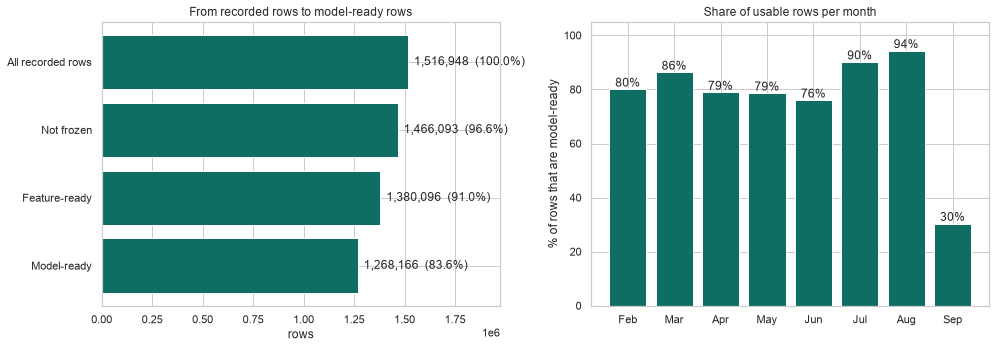

Period: 01 Feb 2020 to 01 Sep 2020


In [135]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
TEAL = "#0F6E64"

FEATURES = ["onload_time_share_1h", "compressor_starts_1h", "oil_temp_mean_1h", "tp3_min_1h",
            "tp3_drain_rate_60m", "tp3_fill_rate_60m", "dryer_abn_share_60m", "filter_abn_share_60m"]

mr = df_fe[df_fe["model_ready"]].copy()
q = mr[FEATURES]

stages = {"All recorded rows": len(df_fe),
          "Not frozen": int((df_fe["sensors_frozen"] == 0).sum()),
          "Feature-ready": int(df_fe["feature_ready"].sum()),
          "Model-ready": len(mr)}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names, values = list(stages.keys()), list(stages.values())

axes[0].barh(names, values, color=TEAL)
axes[0].invert_yaxis()
for i, v in enumerate(values):
    axes[0].text(v, i, f"  {v:,}  ({v / len(df_fe) * 100:.1f}%)", va="center")
    
axes[0].set_xlim(0, len(df_fe) * 1.3)
axes[0].set_xlabel("rows")
axes[0].set_title("From recorded rows to model-ready rows")

monthly = df_fe.groupby(df_fe["timestamp"].dt.to_period("M"))["model_ready"].mean() * 100

axes[1].bar(monthly.index.strftime("%b"), monthly.values, color=TEAL)
for i, v in enumerate(monthly.values):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center")
    
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("% of rows that are model-ready")
axes[1].set_title("Share of usable rows per month")

plt.tight_layout()
plt.show()
print(f"Period: {mr['timestamp'].min():%d %b %Y} to {mr['timestamp'].max():%d %b %Y}")

### 6.2.2 What do the eight features look like?

A table of the typical value, spread and range of each feature, and how often it is exactly zero. The bars show how many values lie far from the middle (outside the Tukey fences) and how many are zero.

**Finding:**
- The load share has a median of 0.110 (middle half 0.074 to 0.132). Its skew is 3.40, with 3.16% of rows outside the Tukey fences.
- The oil temperature has a median of 63.5 °C. The TP3 minimum has a median of 8.06 bar, but a few values drop as low as 0.82 bar.
- The dryer abnormal share is zero for 88% of rows, and the filter abnormal share for 54%.

**Conclusion:** The features are on very different scales (shares, degrees, bar, bar per minute), so they must be scaled before modelling. The abnormal shares are sparse signals that appear mainly in short windows, so a mean-based scaling alone would not fit them.

,median,IQR (25%-75%),min,max,% of rows = 0
onload_time_share_1h,0.110,0.058,0.041,0.698,0.000
compressor_starts_1h,3.000,1.000,0.000,10.000,0.009
oil_temp_mean_1h,63.501,7.571,39.227,78.489,0.000
tp3_min_1h,8.062,0.068,0.816,8.666,0.000
tp3_drain_rate_60m,-0.105,0.049,-0.686,-0.043,0.000
tp3_fill_rate_60m,0.952,0.154,-0.089,1.469,0.000
dryer_abn_share_60m,0.000,0.000,0.000,0.984,87.984
filter_abn_share_60m,0.000,0.028,0.000,0.222,53.827


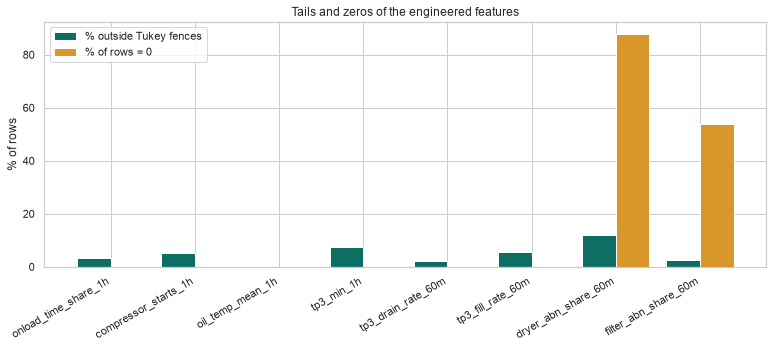

In [136]:
q1, q3 = q.quantile(0.25), q.quantile(0.75)
iqr = q3 - q1

profile = pd.DataFrame({
    "median": q.median(),
    "IQR (25%-75%)": iqr,
    "min": q.min(),
    "max": q.max(),
    "% of rows = 0": (q == 0).mean() * 100,
}).round(3)
display(profile)

outside = ((q < q1 - 1.5 * iqr) | (q > q3 + 1.5 * iqr)).mean() * 100

x = np.arange(len(FEATURES))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - 0.2, outside.values, 0.4, label="% outside Tukey fences", color=TEAL)
ax.bar(x + 0.2, profile["% of rows = 0"].values, 0.4, label="% of rows = 0", color="#D9962B")
ax.set_xticks(x)
ax.set_xticklabels(FEATURES, rotation=30, ha="right")
ax.set_ylabel("% of rows")
ax.set_title("Tails and zeros of the engineered features")
ax.legend()
plt.tight_layout()
plt.show()

### 6.2.3 Which features move together?

A correlation heatmap of the eight features (Spearman, so it is not thrown off by the outliers). Only the lower triangle is shown, so each pair appears once and the diagonal of 1s is hidden. Red means the two features rise together, blue means one rises as the other falls.

**Finding:** Oil temperature and the TP3 drain rate are strongly negatively correlated (−0.89). The drain rate is negative, so this means that when the oil gets hotter, the pressure falls faster while the compressor is not loaded (the drain rate becomes more negative). The printed list gives the other strong pairs.

**Conclusion:** Some features carry overlapping information. We keep them because each one comes from a separate physical mechanism, but the models should not be expected to gain much from both features of a strongly correlated pair alone.

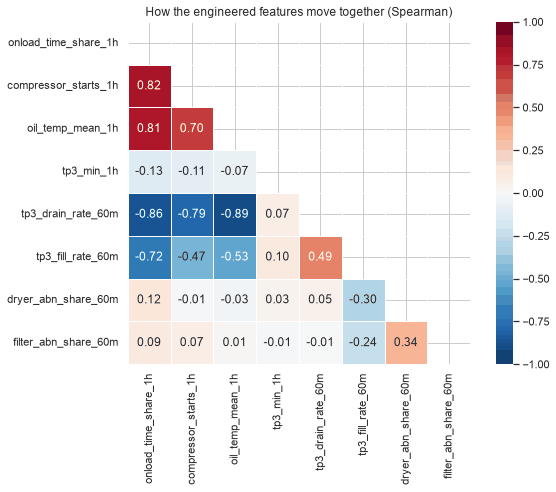

Strongest pairs:
  oil_temp_mean_1h and tp3_drain_rate_60m: correlation = -0.89
  onload_time_share_1h and tp3_drain_rate_60m: correlation = -0.86
  onload_time_share_1h and compressor_starts_1h: correlation = 0.82
  onload_time_share_1h and oil_temp_mean_1h: correlation = 0.81
  compressor_starts_1h and tp3_drain_rate_60m: correlation = -0.79


In [137]:
sample = q.sample(200_000, random_state=42)
corr = sample.corr(method="spearman")

# show each pair once: hide the upper triangle and the diagonal
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("How the engineered features move together (Spearman)")
plt.tight_layout()
plt.show()

print("Strongest pairs:")
pairs = []
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        pairs.append((FEATURES[i], FEATURES[j], corr.iloc[i, j]))
pairs = sorted(pairs, key=lambda p: abs(p[2]), reverse=True)
for a, b, r in pairs[:5]:
    print(f"  {a} and {b}: correlation = {r:.2f}")

### 6.2.4 Do the features depend on the compressor's operating state?

The compressor is either off, unloaded (running but not compressing), or loaded. Each boxplot shows the spread of one feature in each state.

**Finding:** The state changes the features strongly. In the "Off" state the median load share is 0.093, and in the "Possible unloaded" state it is 0.118. Compressor starts have a median of 2.0 per hour in the "Off" state. The printed table gives the loaded state.

**Conclusion:** A feature value is only meaningful relative to its state. This is why the pressure drain and fill rates are split by state, and why the modelling step must include the state as context.

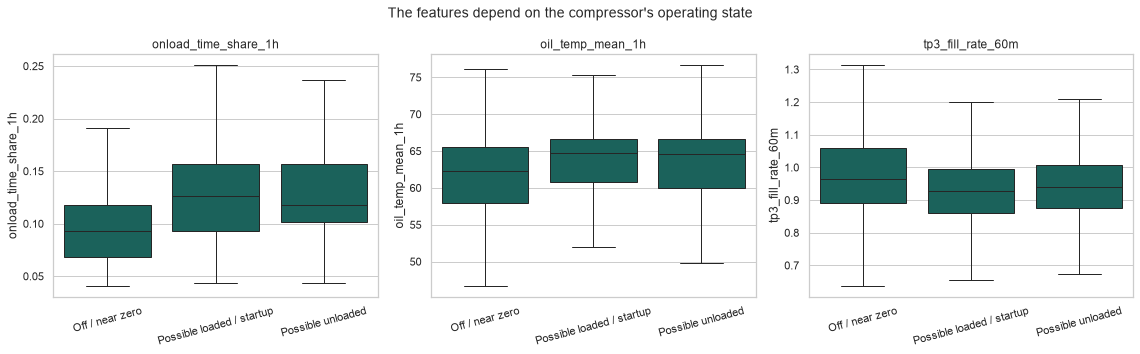

                           onload_time_share_1h  oil_temp_mean_1h  \
motor_state                                                         
Off / near zero                           0.093            62.362   
Possible loaded / startup                 0.126            64.683   
Possible unloaded                         0.118            64.543   

                           tp3_fill_rate_60m  
motor_state                                   
Off / near zero                        0.964  
Possible loaded / startup              0.928  
Possible unloaded                      0.939  
motor_state
Off / near zero              56.2
Possible unloaded            32.9
Possible loaded / startup    10.8
Name: proportion, dtype: float64


In [138]:
sample = mr.sample(100_000, random_state=42)
states = sorted(sample["motor_state"].unique())
show = ["onload_time_share_1h", "oil_temp_mean_1h", "tp3_fill_rate_60m"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, show):
    sns.boxplot(data=sample, x="motor_state", y=col, order=states, color=TEAL,
                showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("The features depend on the compressor's operating state", fontsize=14)
plt.tight_layout()
plt.show()

print(sample.groupby("motor_state")[show].median().round(3))
print((mr["motor_state"].value_counts(normalize=True) * 100).round(1))

### 6.2.5 Does the healthy baseline stay the same over time?

We take healthy rows only (no failure, and more than 24 hours before the next failure) and plot the monthly median of three features.

**Finding:** The healthy load share rises from 0.060 in February to 0.121 in June and July, roughly doubling. The other two lines show their own pattern (see the printed table).

**Conclusion:** A single fixed baseline for the whole period would be wrong. A rise in load share can look like a warning when it is only a change in the season or in use. Any alarm rule has to compare each period with its own baseline, and we should check this with the team before the modelling step. The cause of the rise is not visible in this data alone, so we describe it as a pattern and do not explain it.

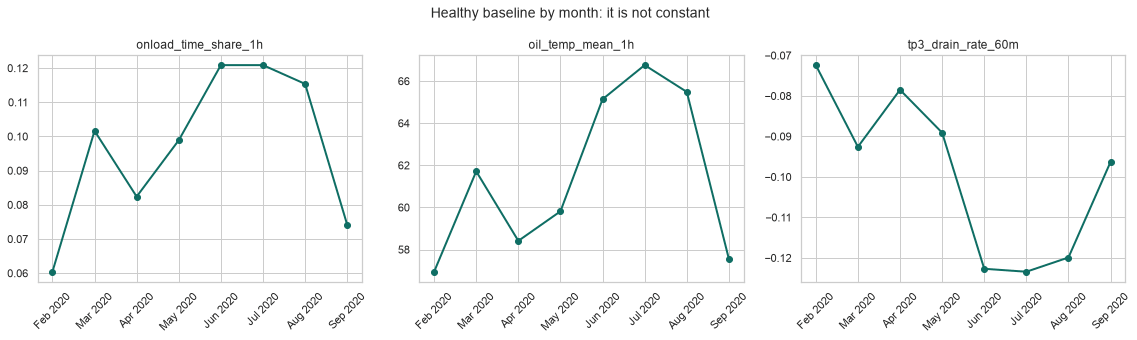

           onload_time_share_1h  oil_temp_mean_1h  tp3_drain_rate_60m
timestamp                                                            
2020-02                   0.060            56.949              -0.072
2020-03                   0.102            61.716              -0.093
2020-04                   0.082            58.415              -0.078
2020-05                   0.099            59.817              -0.089
2020-06                   0.121            65.141              -0.123
2020-07                   0.121            66.762              -0.123
2020-08                   0.115            65.490              -0.120
2020-09                   0.074            57.556              -0.096


In [139]:
healthy = mr[(mr["is_failure"] == 0) &
             (mr["hours_to_next_failure"].isna() | (mr["hours_to_next_failure"] > 24))]

cols = ["onload_time_share_1h", "oil_temp_mean_1h", "tp3_drain_rate_60m"]
monthly_med = healthy.groupby(healthy["timestamp"].dt.to_period("M"))[cols].median()
labels = monthly_med.index.strftime("%b %Y")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col in zip(axes, cols):
    ax.plot(labels, monthly_med[col], marker="o", color=TEAL, linewidth=2)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Healthy baseline by month: it is not constant", fontsize=14)
plt.tight_layout()
plt.show()

print(monthly_med.round(3))

<hr>

<hr>